# RutaBrasa: sistema multi-agente para planificar el reparto de una distribuidora en Lima

**Hackathon 7 (Semana 9): implementación de un sistema multi-agente con Groq**
Planificación y Toma de Decisiones en IA · UTEC 2026-2

| | |
|---|---|
| **Equipo** | Las Grills |
| **Integrantes** | Jimena Gurbillon · Maria Surco · Nayeli Guzman · Bihonda Epiquien · Andrea Coa |
| **Caso seleccionado** | Caso 3: Planificador logístico |
| **Fecha de entrega** | Miércoles 14 de octubre de 2026 |
| **Motor de lenguaje** | Groq: `qwen/qwen3.8-27b` y `openai/gpt-oss-120b` (respaldo: `openai/gpt-oss-20b`) |

## Resumen ejecutivo

- **Problema.** Cada mañana, el jefe de despacho de una distribuidora que abastece a pollerías y parrillas de Lima decide qué vehículo lleva cada pedido y en qué orden. Tiene ventanas horarias cortas, carga refrigerada y el tráfico de hora punta.
- **Sistema.** Cuatro agentes con roles separados: **Analista → Planificador → Evaluador → Decisor**. El Analista y el Evaluador trabajan con **8 tools propias** (6 de datos y 2 de simulación) por *tool calling* nativo de Groq.
- **Principio de diseño.** *El LLM interpreta y juzga; el código calcula y verifica.* Ningún número de la decisión final sale de la "intuición" del modelo: tiempos, costos y puntualidad los mide un simulador determinista.
- **Red de seguridad.** Además de las 3 propuestas del Planificador, el orquestador agrega una línea base **H** calculada con una regla simple sin LLM. Así el sistema nunca recomienda algo peor que esa regla, y queda medido cuánto aportan los agentes.
- **Robustez para la demo.** Hay rotación entre varias API keys, modelos de respaldo, control de *rate limits* leyendo las cabeceras de Groq, validación de esquemas y una auditoría automática de la decisión antes de pasarla a un humano.

| Sección de la consigna | Dónde está en este notebook |
|---|---|
| 6.1 Portada | arriba |
| 6.2 Introducción del caso | §1 |
| 6.3 Diseño de agentes | §2 |
| 6.4 Diseño del flujo de orquestación (con diagrama) | §3 |
| 6.5 Implementación con Groq | §4 |
| 6.6 Resultados intermedios | §5 |
| 6.7 Decisión final | §6 |
| 6.8 Evaluación crítica | §7 |
| Demo en vivo con el input de otro equipo | §8 |
| Gestión del consumo de la API | §9 |

---
# 1. Introducción del caso (6.2)

**Insumos La Brasa S.A.C.** es una distribuidora mayorista ficticia con almacén en Surquillo. Cada mañana reparte pollo y carnes refrigeradas, carbón y abarrotes a unos 18 restaurantes (pollerías, parrillas, anticucherías) repartidos por Lima. Los datos del caso son sintéticos, pero los parámetros se eligieron para que se parezcan a una operación real: horarios de recepción antes del almuerzo, hora punta de 7:00 a 10:00 y vehículos con y sin frío.

| Pregunta | Respuesta |
|---|---|
| **¿Cuál es el problema?** | Asignar ~18–20 pedidos a 3–6 vehículos de tipos distintos (furgoneta refrigerada, van, moto con caja térmica) y ordenar las visitas. Hay que respetar ventanas horarias, capacidad, cadena de frío y restricciones del día (cierres de vía, prohibiciones municipales de carga, pedidos de último minuto). Hoy se hace a mano con Excel y WhatsApp entre 6:30 y 7:15. |
| **¿Por qué es importante?** | Una pollería que no recibe el pollo antes de las 11:00 empieza el almuerzo sin producto: es la principal causa de reclamos y de pérdida de clientes. El pollo que pasa demasiado tiempo fuera de frío es merma. Además, el combustible y las horas de chofer son el costo variable más grande del reparto. |
| **¿Qué decisión se busca apoyar?** | **Qué estrategia de reparto ejecutar hoy**: qué vehículo lleva cada pedido, si algún vehículo hace segunda vuelta y en qué orden visita a los clientes. El sistema entrega una estrategia recomendada con hojas de ruta y horas estimadas de llegada (ETA). |
| **¿Quién usará el sistema?** | El **coordinador / jefe de despacho**, que es quien aprueba. Los **choferes** reciben la hoja de ruta y el **área comercial** usa las ETA para avisar a los clientes. |
| **¿Qué impacto tendría?** | Bajar la planificación de ~45 min a ~2 min. Detectar antes de salir los pedidos que no se pueden cumplir y avisar al cliente a tiempo. Hacer explícito el *trade-off* entre costo y puntualidad. Y dejar trazabilidad de por qué se eligió cada plan. |

### 1.1 Criterios de decisión

| Criterio | Cómo se mide (simulador) | Tipo |
|---|---|---|
| **Factibilidad** | Todos los pedidos asignados, sin exceder la capacidad por vuelta, refrigerados solo en vehículos con frío, caja térmica ≤ 90 min, sin entrar a zonas prohibidas | Restricción dura: si falla, la estrategia no es factible |
| **Puntualidad** | % de pedidos atendidos dentro de su ventana, % de **urgentes** a tiempo y minutos totales de tardanza | Se optimiza |
| **Costo** | S/ por km (combustible) + S/ por hora de chofer, con recargo de 50% fuera de turno | Se optimiza |
| **Tiempo total** | Hora en que vuelve al almacén el último vehículo | Se optimiza |
| **Robustez** | Caída de la puntualidad si el tráfico es 30% peor de lo previsto (prueba de estrés) | Riesgo |
| **Complejidad operativa** | Número de vehículos, vueltas y pedidos divididos | Riesgo |

El peso de cada criterio **depende del objetivo del día**, que el usuario indica en el input 5 (costo, puntualidad, rapidez o balanceado). Así, la misma operación puede terminar con decisiones distintas según lo que priorice el coordinador.

**Alcance y supuestos:** las coordenadas son centroides aproximados de cada distrito. El tiempo de viaje se calcula con distancia en línea recta × 1.4 (rodeo urbano) y un perfil de tráfico por hora. El sistema **recomienda**: el despacho real siempre lo aprueba una persona.

---
# 2. Diseño de agentes (6.3)

| # | Agente | Rol | Objetivo | Qué recibe | Qué produce | Tools | Modelo (temp.) |
|---|---|---|---|---|---|---|---|
| 1 | **Analista de operaciones** | Analista logístico | Traducir la solicitud en lenguaje natural a una configuración verificada del día | Prompt inicial con 2–5 inputs + pedidos base | Configuración aplicada en el estado + resumen con alertas y supuestos | `configurar_operacion`, `agregar_pedido`, `modificar_pedido`, `cancelar_pedido`, `registrar_restriccion`, `resumen_operacion` | qwen3.8-27b (0.1) |
| 2 | **Planificador** | Diseñador de rutas | Proponer 3 estrategias con lógicas distintas, escritas en un formato que el simulador pueda ejecutar | Resumen del Analista + datos verificados + matriz de tiempos | 3 estrategias en JSON (esquema estricto) | ninguna | gpt-oss-120b (0.5, razonamiento bajo) |
| 3 | **Evaluador** | Analista de eficiencia | Medir y comparar: tiempo, costo, complejidad y riesgo | 3 estrategias + línea base H + objetivo del día | Evaluación comparativa con cifras simuladas, ranking y, si hace falta, pedido de replanificación | `simular_estrategias`, `prueba_estres` | qwen3.8-27b (0.2) |
| 4 | **Decisor** | Coordinador logístico | Elegir la estrategia final y justificarla en eficiencia y factibilidad | KPIs simulados + pruebas de estrés + evaluación + alertas | Decisión en JSON: elegida, por qué, criterios, *trade-offs*, riesgos, qué revisar | ninguna | gpt-oss-120b (0.3, razonamiento bajo) |

### 2.1 Qué cambiamos respecto a la tabla sugerida

Partimos de los cuatro roles que propone la consigna para el caso logístico, pero cada uno tiene una responsabilidad más concreta:

1. **El Analista no solo resume: es el único agente que puede cambiar los datos de la operación**, y solo lo hace a través de tools que validan cada cambio. Por ejemplo, si el usuario escribe "Miraflorez", el distrito se corrige con aviso; si pide un pedido de -5 kg, la tool lo rechaza y el agente tiene que corregir la llamada.
2. **El Planificador escribe en un "lenguaje de rutas" ejecutable**: cada parada es un distrito o un ID de pedido, y repetir un vehículo significa hacer una segunda vuelta. Esto permite simular sus propuestas sin interpretarlas a mano.
3. **El Evaluador está obligado a simular antes de opinar** (la primera ronda usa `tool_choice="required"`). Su juicio cualitativo (complejidad, riesgo) se apoya en cifras medidas, no estimadas.
4. **El Decisor puede apartarse del ranking numérico, pero tiene que justificarlo** en un campo específico (`desviacion_del_ranking`). Una auditoría automática revisa su elección antes de mostrarla al humano.
5. **Agregamos una línea base H sin LLM como alternativa adicional.** No es un agente: es una regla voraz que calcula el orquestador. Sirve como red de seguridad (si las propuestas del LLM son malas, el Decisor tiene una opción razonable) y como vara para medir si los agentes aportan algo (§7.2).

### 2.2 ¿Por qué 4 agentes y no 3 o 5?

Cada agente corresponde a una tarea cognitiva distinta, que **falla de forma distinta** y necesita una configuración distinta:

| Tarea | Agente | Modo de falla típico | Por eso… |
|---|---|---|---|
| Comprender (extracción) | Analista | Inventar o malinterpretar datos | temperatura 0.1 y tools que validan |
| Generar (divergencia) | Planificador | Proponer variantes casi iguales | temperatura 0.5, razonamiento y "3 lógicas obligatorias" |
| Criticar (verificación) | Evaluador | Opinar sin medir, favorecer lo propio | simulador obligatorio y no ve el razonamiento del planificador |
| Decidir (juicio con *trade-offs*) | Decisor | Elegir algo no factible o justificar con cifras inventadas | esquema estricto y auditoría posterior |

- **Con 3 agentes** tendríamos que fusionar al planificador con el evaluador. Un LLM que evalúa sus propias propuestas tiende a encontrarlas buenas (sesgo de autoevaluación) y no se le podrían dar temperaturas distintas para generar y para criticar. Fusionar evaluador y decisor rompe el principio de control de que *quien mide no es quien decide*, y además el decisor tendría que cargar toda la traza de tools (más tokens).
- **Un 5.º agente** ("verificador de restricciones") lo descartamos a propósito. Verificar capacidad o ventanas horarias es **cálculo, no juicio**: como código determinista (simulador + auditoría) es exacto, gratis e instantáneo, mientras que como LLM costaría ~25% más tokens y podría equivocarse en aritmética. En la capa gratuita de Groq, cada agente extra le resta margen a la demo en vivo.

### 2.3 Prompt inicial: 5 inputs (mínimo 2)

| # | Input | ¿Obligatorio? | Valor por defecto | Ejemplo |
|---|---|---|---|---|
| 1 | `pedidos` | Sí | 18 pedidos base | "Agregar un pedido urgente de 25 kg de pollo en San Borja entre 8:30 y 9:45" |
| 2 | `flota` | Sí | 2 furgonetas refrigeradas, 1 van, 2 motos | "La van está en el taller; tenemos 2 furgonetas y 2 motos" |
| 3 | `horario` | No | salida 07:30, regreso 13:30 | "Salimos a las 7 y hay que volver antes de la 1" |
| 4 | `restricciones` | No | ninguna | "Obras en la Vía Expresa: Barranco y Chorrillos 40% más lentos" |
| 5 | `objetivo` | No | balanceado | "Lo más importante hoy es cumplir con los urgentes" |

El orquestador valida que lleguen entre 2 y 5 inputs y que estén los dos obligatorios. Todo lo que el usuario no indique se mantiene en su valor por defecto, y el Analista lo declara como supuesto.

---
# 3. Diseño del flujo de orquestación (6.4)

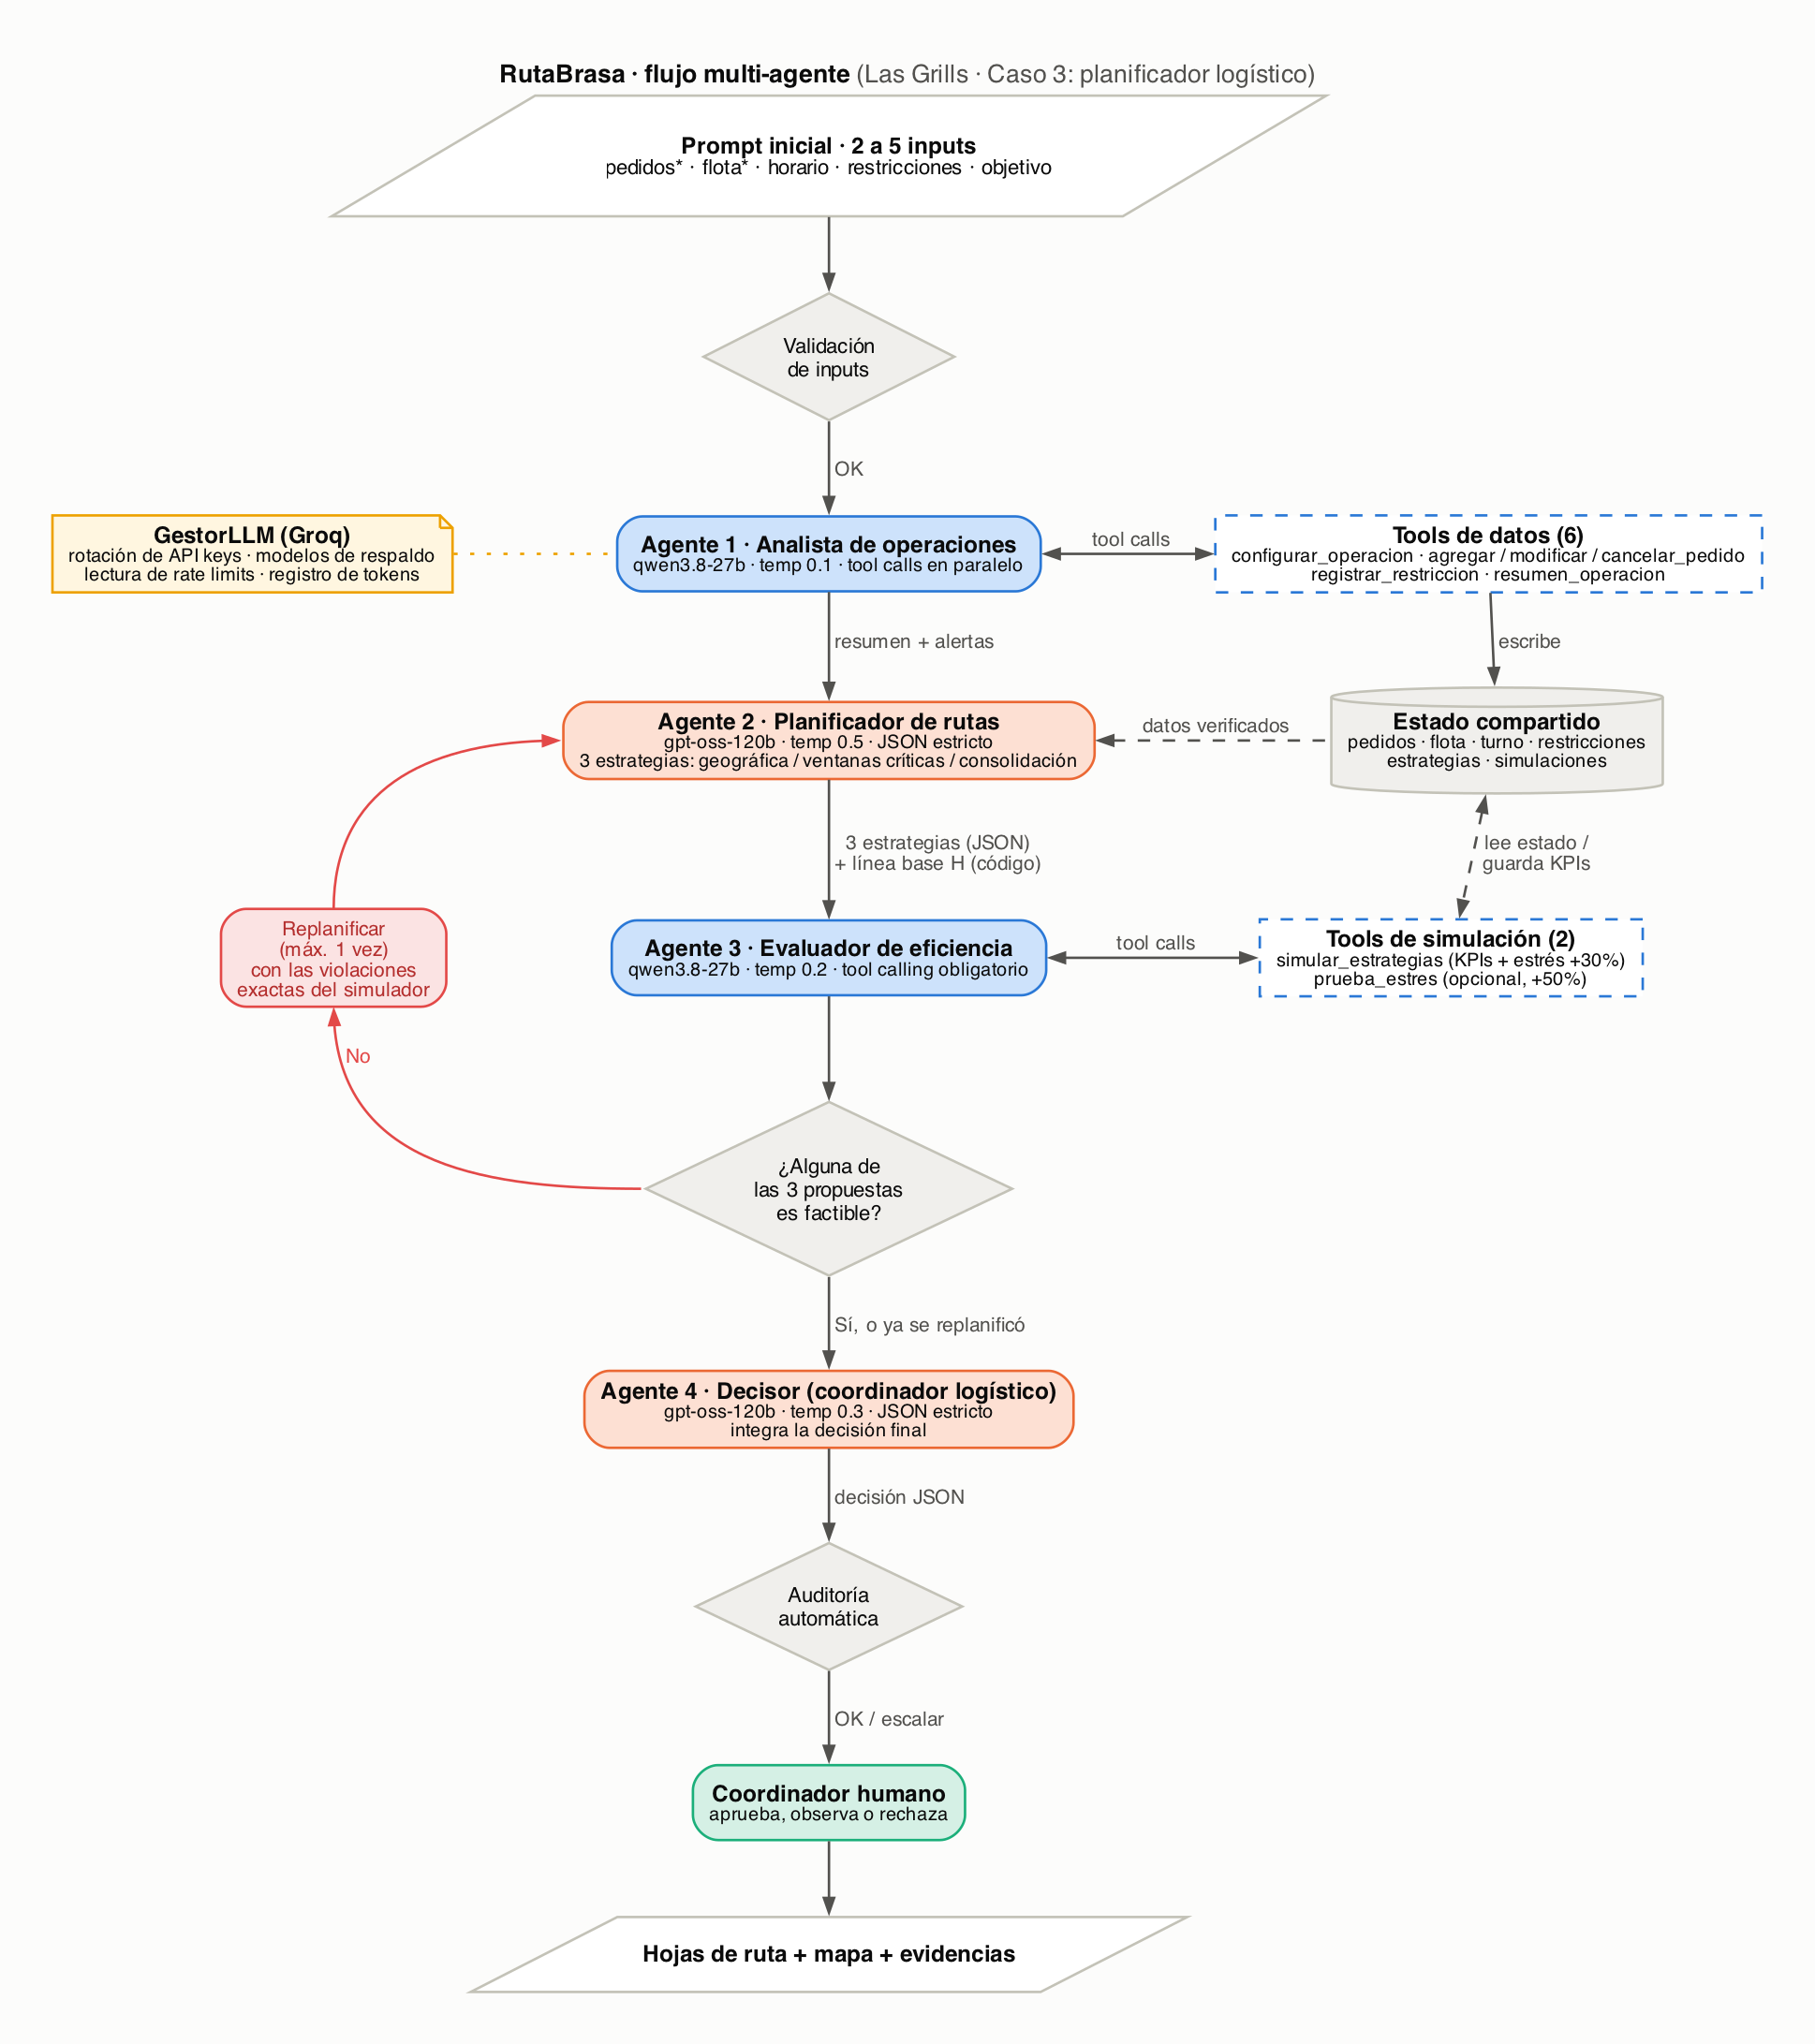

*El mismo diagrama está en `entregables/diagrama_flujo.png`. Abajo va su versión Mermaid (se ve en JupyterLab ≥ 4.1 y en GitHub).*

```mermaid
flowchart TD
    U[/"Prompt inicial: 2 a 5 inputs<br/>pedidos · flota · horario · restricciones · objetivo"/] --> V{"Validación de inputs"}
    V --> A1["Agente 1 · Analista de operaciones<br/>qwen3.8-27b"]
    A1 <-->|tool calling| T1[["Tools de datos (6)"]]
    T1 --> E[("Estado compartido<br/>pedidos · flota · restricciones")]
    A1 -->|resumen + alertas| A2["Agente 2 · Planificador<br/>gpt-oss-120b · JSON estricto"]
    E -.datos verificados.-> A2
    A2 -->|3 estrategias JSON + línea base H| A3["Agente 3 · Evaluador<br/>qwen3.8-27b"]
    A3 <-->|tool calling| T2[["Tools de simulación (2)"]]
    T2 -.lee.-> E
    A3 --> C{"¿Alguna de las 3 propuestas es factible?"}
    C -->|"No (máx. 1 vez)"| A2
    C -->|"Sí, o ya se replanificó"| A4["Agente 4 · Decisor<br/>gpt-oss-120b · JSON estricto"]
    A4 --> G{"Auditoría automática"}
    G --> H["Coordinador humano aprueba"]
    H --> R[/"Hojas de ruta + mapa + evidencias"/]
```

### 3.1 Orden de ejecución y qué información pasa

| Paso | De → A | Qué se pasa | Formato |
|---|---|---|---|
| 0 | Usuario → Orquestador | 2–5 inputs en texto libre | diccionario validado |
| 1 | Orquestador → **Analista** | Solicitud + pedidos base + valores por defecto | prompt |
| 2 | Analista ⇄ tools de datos | Cambios al estado (flota, pedidos, restricciones) y resumen verificado | *tool calling* (llamadas en paralelo) |
| 3 | Analista → **Planificador** | Resumen y alertas (texto) + **datos verificados del estado** (tabla compacta) + matriz de tiempos | Markdown + tablas |
| 4 | Planificador → **Evaluador** | 3 estrategias + línea base H (la agrega el orquestador) | JSON con esquema estricto (`json_schema`) |
| 5 | Evaluador ⇄ tools de simulación | KPIs por estrategia, puntaje según el objetivo, prueba de estrés al +30% | *tool calling* |
| 5b | Evaluador → Planificador *(condicional)* | Violaciones exactas detectadas por el simulador | retroalimentación en texto |
| 6 | Evaluador → **Decisor** | Evaluación comparativa + tabla de KPIs simulados + estrés + alertas | JSON + tabla |
| 7 | Decisor → Orquestador → Humano | Decisión + auditoría + hojas de ruta | JSON + tablas + mapa |

### 3.2 Tipo de flujo

**Secuencial con un bucle condicional.** El camino normal es Analista → Planificador → Evaluador → Decisor. Si el simulador encuentra que **ninguna** de las 3 estrategias del Planificador es factible (la línea base H no cuenta), el orquestador devuelve las violaciones al Planificador **una sola vez** (`MAX_REPLANIFICACIONES = 1`). El límite es para controlar el consumo de la API: si después de replanificar sigue sin haber una estrategia factible, el Decisor elige la de menor daño y la decisión se escala a una persona.

Entre agentes hay **compuertas de validación en código**: validación de inputs, validación del JSON del planificador, un respaldo que simula de todas formas si el evaluador no usó la tool, y una auditoría de la decisión.

### 3.3 ¿Quién integra la respuesta final?

El **Decisor** integra la decisión: elige la estrategia y redacta la justificación, los riesgos y las verificaciones humanas. El **orquestador** (código) arma el entregable operativo: las hojas de ruta y los KPIs salen de la simulación de la estrategia elegida, nunca del texto del LLM. El último paso lo da el **coordinador humano**, que aprueba o rechaza el despacho.

---
# 4. Implementación con Groq (6.5)

## 4.1 Configuración del entorno

```bash
pip install groq python-dotenv pandas matplotlib
```

**Manejo de las API keys.** Las keys **nunca se escriben en el notebook**. Se leen de un archivo `.env` que está en `.gitignore` y no se entrega (ver `.env.example`). Cada integrante crea su key gratuita en console.groq.com con su correo UTEC y la agrega como `GROQ_API_KEY`, `GROQ_API_KEY_2`, … `GROQ_API_KEY_5`. Cuantas más keys haya, más cuota tiene el sistema para la demo. Si no hay `.env`, el notebook pide la key con `getpass`, que no la muestra en pantalla. En las salidas, cada key aparece solo con un alias y sus últimos 4 caracteres.

In [1]:
import os, re, json, time, math, hashlib, unicodedata, difflib, inspect
from dataclasses import dataclass, field
from datetime import datetime
from pathlib import Path
from io import StringIO

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    from dotenv import load_dotenv
    load_dotenv(Path(".env"))   # lee .env de esta carpeta (el archivo no se entrega ni se sube a git)
except ImportError:
    print("python-dotenv no está instalado: se usan solo las variables de entorno del sistema.")

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)

In [2]:
# ---------- Parámetros de ejecución ----------
PROVEEDOR = os.getenv("PROVEEDOR_LLM", "groq")   # "groq" para la entrega y la demo; "ollama" solo para ensayos locales

# Modelo principal + cadena de respaldo por agente (solo modelos que hoy ofrece Groq: Llama ya fue retirado).
# Repartimos los agentes entre dos modelos porque Groq limita los tokens por minuto POR MODELO:
# así el Analista y el Evaluador (qwen) no compiten por la misma cuota que el Planificador y el Decisor (gpt-oss-120b).
#  - qwen3.8-27b: tool calls en paralelo (el Analista registra varios cambios en una sola ronda).
#  - gpt-oss-120b: razonamiento + salida JSON con esquema estricto.
MODELOS_POR_AGENTE = {
    "analista":     ["qwen/qwen3.8-27b", "openai/gpt-oss-120b", "openai/gpt-oss-20b"],
    "planificador": ["openai/gpt-oss-120b", "qwen/qwen3.8-27b", "openai/gpt-oss-20b"],
    "evaluador":    ["qwen/qwen3.8-27b", "openai/gpt-oss-20b", "openai/gpt-oss-120b"],
    "decisor":      ["openai/gpt-oss-120b", "qwen/qwen3.8-27b", "openai/gpt-oss-20b"],
}
MODELOS_JSON_SCHEMA = {"openai/gpt-oss-120b", "openai/gpt-oss-20b", "qwen/qwen3.8-27b"}  # admiten salida estructurada estricta
MODELO_OLLAMA = os.getenv("MODELO_OLLAMA", "qwen2.5:7b")

USAR_CACHE = os.getenv("USAR_CACHE", "0") == "1"   # solo en ensayos: no gasta cuota repitiendo exactamente la misma llamada
MAX_REPLANIFICACIONES = 1        # el bucle Evaluador → Planificador se repite como máximo 1 vez
APROBACION_INTERACTIVA = False   # True en la demo: pide confirmación al coordinador antes de "despachar"
PUNTUALIDAD_MINIMA = 70          # % de pedidos a tiempo bajo el cual la auditoría obliga a escalar a una persona
CARPETA_EVIDENCIAS = Path("evidencias")
CARPETA_EVIDENCIAS.mkdir(exist_ok=True)
print(f"Proveedor: {PROVEEDOR} | caché: {USAR_CACHE} | replanificaciones máx.: {MAX_REPLANIFICACIONES}")

Proveedor: groq | caché: False | replanificaciones máx.: 1


## 4.2 Gestor de llamadas a Groq

Todas las llamadas de los agentes pasan por una sola clase. La armamos así porque la capa gratuita de Groq es el principal riesgo de la demo en vivo:

| Problema | Qué hace el gestor |
|---|---|
| Límite de tokens por minuto (TPM) o de requests por día (RPD) | Lee las cabeceras `x-ratelimit-*` de **cada respuesta**, estima cuánto se repuso desde entonces (Groq repone la cuota de forma continua) y elige la key con más margen. Si ninguna alcanza, espera solo los segundos necesarios. Además, limita la respuesta máxima de cada solicitud para que nunca supere la cuota por minuto del modelo (8 mil tokens en la capa gratuita). |
| Error 429 | Bloquea esa combinación key/modelo durante los segundos de `retry-after` y **rota a la siguiente key**. |
| Modelo retirado o no disponible | Pasa al siguiente modelo de la cadena de respaldo del agente. Al inicio, el *preflight* consulta `models.list()`. **Nos pasó de verdad:** diseñamos con `llama-3.3-70b`, pero el día de la corrida Groq ya no lo ofrecía, así que reasignamos el Analista y el Evaluador a `qwen3.8-27b` (verificamos que hace *tool calls* en paralelo). |
| *Tool call* o JSON mal formado (`tool_use_failed`) | Reintenta bajando la temperatura y, si vuelve a fallar, cambia de modelo. |
| Key inválida (401) | La descarta y sigue con las demás. |
| Ensayos que gastan cuota | Caché opcional en disco (`USAR_CACHE=1`) y opción de Ollama local. |
| Trazabilidad | Registra cada llamada: agente, modelo, key (alias), tokens, latencia y cuota restante. |

In [3]:
def _alias(key, i):
    return f"key{i}…{key[-4:]}"          # nunca mostramos la key completa

def cargar_api_keys():
    """GROQ_API_KEY, GROQ_API_KEY_2 … GROQ_API_KEY_5 (una por integrante) o GROQ_API_KEYS separadas por comas."""
    keys = [k.strip() for k in os.getenv("GROQ_API_KEYS", "").split(",") if k.strip()]
    for nombre in ["GROQ_API_KEY"] + [f"GROQ_API_KEY_{i}" for i in range(2, 6)]:
        if os.getenv(nombre):
            keys.append(os.getenv(nombre).strip())
    keys = list(dict.fromkeys(keys))
    if not keys:
        try:
            from getpass import getpass
            k = getpass("Pega tu GROQ_API_KEY (no se muestra ni se guarda): ").strip()
            keys = [k] if k else []
        except Exception:
            pass
    return keys

def _segundos(texto):
    """'7.66s', '1m30s', '2m59.56s', '120ms' → segundos."""
    if not texto:
        return None
    unidades = {"ms": 0.001, "s": 1, "m": 60, "h": 3600}
    total = sum(float(v) * unidades[u] for v, u in re.findall(r"([\d.]+)(ms|h|m|s)", str(texto)))
    return total or None


@dataclass
class RespuestaLLM:
    contenido: str
    tool_calls: list
    modelo: str
    key: str
    tokens_prompt: int
    tokens_respuesta: int
    latencia_s: float
    fin: str
    desde_cache: bool = False


class GestorLLM:
    """Capa única de acceso al LLM: rotación de keys, modelos de respaldo, rate limits, caché y registro de consumo."""

    def __init__(self, proveedor="groq"):
        self.proveedor = proveedor
        self.registro = []           # una fila por llamada a la API
        self.limites = {}            # (key, modelo) -> último estado de rate limit informado por Groq
        self.bloqueos = {}           # (key, modelo) -> timestamp hasta el que no se usa (tras un 429)
        self.keys_invalidas = set()
        self.modelos_disponibles = None
        if proveedor == "groq":
            import groq as sdk
            keys = cargar_api_keys()
            if not keys:
                raise RuntimeError("No hay API keys de Groq. Crea un .env con GROQ_API_KEY=... (ver .env.example).")
            self.clientes = {_alias(k, i + 1): sdk.Groq(api_key=k, max_retries=0, timeout=90) for i, k in enumerate(keys)}
        elif proveedor == "ollama":
            import openai as sdk     # Ollama expone una API compatible con OpenAI
            self.clientes = {"ollama-local": sdk.OpenAI(base_url="http://localhost:11434/v1", api_key="ollama",
                                                       max_retries=0, timeout=900)}
        else:
            raise ValueError("PROVEEDOR debe ser 'groq' u 'ollama'")
        self.sdk = sdk

    # ---------- verificación previa a la demo ----------
    def verificar(self, ping=True):
        filas, disponibles = [], set()
        for alias, cliente in self.clientes.items():
            try:
                ids = {m.id for m in cliente.models.list().data}
                disponibles |= ids
                filas.append({"key": alias, "estado": "OK", "modelos visibles": len(ids)})
            except self.sdk.AuthenticationError:
                self.keys_invalidas.add(alias)
                filas.append({"key": alias, "estado": "INVÁLIDA (401)", "modelos visibles": 0})
            except Exception as e:
                filas.append({"key": alias, "estado": f"ERROR {type(e).__name__}", "modelos visibles": 0})
        display(pd.DataFrame(filas))
        if not any(f["estado"] == "OK" for f in filas):
            raise RuntimeError("Ninguna key/conexión funciona: revisa el .env o la conexión a internet.")
        self.modelos_disponibles = disponibles if self.proveedor == "groq" else None

        asignacion, probados = [], {}
        for agente in MODELOS_POR_AGENTE:
            modelo = self.modelo_para(agente)
            fila = {"agente": agente, "modelo asignado": modelo or "⚠️ ninguno disponible"}
            if ping and modelo and modelo not in probados:
                r = self.chat(agente, [{"role": "user", "content": "Responde solo: OK"}], max_tokens=24,
                              usar_cache=False, etiqueta="preflight")
                probados[modelo] = self.limites.get((r.key, r.modelo), {})
            lim = probados.get(modelo, {})
            fila.update({"TPM restantes": lim.get("restantes_tokens"), "TPM límite": lim.get("limite_tokens"),
                         "RPD restantes": lim.get("restantes_requests")})
            asignacion.append(fila)
        display(pd.DataFrame(asignacion))
        n = len(self.clientes) - len(self.keys_invalidas)
        print(f"✅ {n} key(s) operativa(s). Una corrida del sistema usa ~45 mil tokens (2 modelos); "
              f"con {n} key(s) la cuota por minuto y por día se reparte entre ellas.")

    # ---------- selección de modelo y key ----------
    def modelo_para(self, agente):
        candidatos = self._candidatos(agente)
        return candidatos[0] if candidatos else None

    def _candidatos(self, agente):
        if self.proveedor == "ollama":
            return [MODELO_OLLAMA]
        return [m for m in MODELOS_POR_AGENTE[agente]
                if self.modelos_disponibles is None or m in self.modelos_disponibles]

    def _disponible(self, lim, ahora):
        """Tokens disponibles ahora en (key, modelo). Groq repone la cuota por minuto de forma continua."""
        if not lim or lim.get("restantes_tokens") is None:
            return None
        if lim.get("limite_tokens"):
            repuesto = (ahora - lim["leido_ts"]) * lim["limite_tokens"] / 60
            return min(lim["limite_tokens"], lim["restantes_tokens"] + repuesto)
        return lim["restantes_tokens"] if lim["reset_ts"] > ahora else None

    def _elegir_key(self, modelo, estimado):
        ahora, opciones = time.time(), []
        for alias in self.clientes:
            if alias in self.keys_invalidas or self.bloqueos.get((alias, modelo), 0) > ahora:
                continue
            lim = self.limites.get((alias, modelo))
            if lim and lim["restantes_requests"] == 0:
                continue                                  # agotó sus requests del día en este modelo
            disponible = self._disponible(lim, ahora)
            if disponible is not None and disponible < estimado:
                continue                                  # no le alcanza la cuota de este minuto
            opciones.append((disponible if disponible is not None else 10**9, alias))
        return max(opciones)[1] if opciones else None

    def _espera(self, modelo, estimado):
        ahora, esperas = time.time(), []
        for alias in self.clientes:
            lim = self.limites.get((alias, modelo), {})
            if alias in self.keys_invalidas or lim.get("restantes_requests") == 0:
                continue
            espera = self.bloqueos.get((alias, modelo), 0) - ahora
            disponible = self._disponible(lim, ahora)
            if disponible is not None and disponible < estimado and lim.get("limite_tokens"):
                espera = max(espera, (estimado - disponible) / (lim["limite_tokens"] / 60))
            esperas.append(espera)
        return max(0.0, min(esperas)) if esperas else float("inf")

    def _tope_respuesta(self, modelo, prompt_est, max_tokens):
        """Ninguna solicitud puede pedir más tokens que el límite por minuto del modelo (prompt + respuesta)."""
        limites = [l["limite_tokens"] for (a, m), l in self.limites.items() if m == modelo and l.get("limite_tokens")]
        if not limites:
            return max_tokens
        return max(256, min(max_tokens, max(limites) - prompt_est - 300))

    def _leer_limites(self, alias, modelo, h):
        def num(nombre):
            try:
                return int(float(h.get(nombre)))
            except (TypeError, ValueError):
                return None
        ahora = time.time()
        self.limites[(alias, modelo)] = {
            "restantes_tokens": num("x-ratelimit-remaining-tokens"), "limite_tokens": num("x-ratelimit-limit-tokens"),
            "restantes_requests": num("x-ratelimit-remaining-requests"), "limite_requests": num("x-ratelimit-limit-requests"),
            "reset_ts": ahora + (_segundos(h.get("x-ratelimit-reset-tokens")) or 0), "leido_ts": ahora}

    # ---------- llamada principal ----------
    def chat(self, agente, mensajes, tools=None, tool_choice=None, esquema=None, temperatura=0.2,
             max_tokens=1200, razonamiento=None, usar_cache=None, etiqueta=None):
        usar_cache = USAR_CACHE if usar_cache is None else usar_cache
        clave = self._clave_cache(agente, mensajes, tools, tool_choice, esquema, temperatura)
        if usar_cache and (r := self._leer_cache(clave)):
            self._registrar(etiqueta or agente, r)
            return r
        # ~2.7 caracteres por token en español con JSON (medido con las respuestas de Groq)
        prompt_est = int(len(json.dumps(mensajes, ensure_ascii=False)) / 2.7 + (len(json.dumps(tools)) / 2.7 if tools else 0))
        ultimo_error = None
        for modelo in self._candidatos(agente):
            tope = self._tope_respuesta(modelo, prompt_est, max_tokens)
            kwargs = self._armar_kwargs(modelo, mensajes, tools, tool_choice, esquema, temperatura, tope, razonamiento)
            fallos_formato = 0
            for _ in range(8):
                tope = kwargs.get("max_completion_tokens") or kwargs.get("max_tokens") or tope
                estimado = prompt_est + tope           # Groq reserva prompt + máximo de respuesta contra la cuota por minuto
                alias = self._elegir_key(modelo, estimado)
                if alias is None:
                    espera = self._espera(modelo, estimado)
                    if espera > 75:
                        print(f"   ⚠️ {modelo}: sin cuota en ninguna key por {espera:.0f}s → paso al modelo de respaldo")
                        break
                    print(f"   ⏳ {modelo}: cuota por minuto agotada en todas las keys; espero {espera:.0f}s…")
                    time.sleep(espera + 0.5)
                    continue
                try:
                    t0 = time.time()
                    crudo = self.clientes[alias].chat.completions.with_raw_response.create(**kwargs)
                    resp = crudo.parse()
                    self._leer_limites(alias, modelo, crudo.headers)
                    r = self._normalizar(resp, modelo, alias, time.time() - t0)
                    self._registrar(etiqueta or agente, r)
                    if usar_cache:
                        self._guardar_cache(clave, r)
                    return r
                except self.sdk.RateLimitError as e:
                    ultimo_error = e
                    if "too large" in str(e).lower():          # la solicitud sola excede la cuota por minuto
                        self._achicar(kwargs)
                        continue
                    espera = float(e.response.headers.get("retry-after") or 15)
                    self.bloqueos[(alias, modelo)] = time.time() + espera
                    print(f"   ⚠️ 429 en {alias} / {modelo} → bloqueo {espera:.0f}s y roto de key")
                except self.sdk.AuthenticationError as e:
                    ultimo_error = e
                    self.keys_invalidas.add(alias)
                    print(f"   ⚠️ {alias} es inválida → la descarto")
                except self.sdk.NotFoundError as e:
                    ultimo_error = e
                    break                                           # modelo inexistente → siguiente modelo
                except self.sdk.BadRequestError as e:
                    ultimo_error, texto = e, str(e)
                    if any(s in texto for s in ("decommissioned", "model_not_found", "does not exist")):
                        break
                    if esquema and not tools and ("json_schema" in texto or "response_format" in texto) \
                            and kwargs.get("response_format", {}).get("type") == "json_schema":
                        kwargs["response_format"] = {"type": "json_object"}
                        continue
                    if "max completion tokens" in texto and kwargs.get("reasoning_effort") not in (None, "low"):
                        kwargs["reasoning_effort"] = "low"     # el razonamiento consumió el presupuesto y el JSON quedó truncado
                        print(f"   ⚠️ {modelo}: JSON truncado por falta de tokens → reintento con razonamiento bajo")
                        continue
                    if "tool_choice" in texto and kwargs.get("tool_choice") not in (None, "auto"):
                        kwargs["tool_choice"] = "auto"
                        continue
                    if any(s in texto for s in ("tool_use_failed", "json_validate_failed", "failed_generation")):
                        fallos_formato += 1
                        print(f"   ⚠️ {modelo} generó una tool call/JSON mal formado (intento {fallos_formato})")
                        if fallos_formato >= 2:
                            break
                        kwargs["temperature"] = max(0.0, kwargs["temperature"] - 0.15)
                        continue
                    raise
                except (self.sdk.APIConnectionError, self.sdk.InternalServerError) as e:
                    ultimo_error = e
                    print(f"   ⚠️ {type(e).__name__} en {modelo}; reintento en 3s")
                    time.sleep(3)
                except self.sdk.APIStatusError as e:
                    ultimo_error = e
                    if e.status_code == 413 or "too large" in str(e).lower():
                        self._achicar(kwargs)
                        continue
                    raise
        raise RuntimeError(f"No se pudo completar la llamada del agente '{agente}'. Último error: {ultimo_error}")

    def _achicar(self, kwargs):
        clave = "max_completion_tokens" if "max_completion_tokens" in kwargs else "max_tokens"
        kwargs[clave] = max(256, int(kwargs[clave] * 0.6))
        print(f"   ⚠️ solicitud demasiado grande para la cuota por minuto → reduzco la respuesta máxima a {kwargs[clave]} tokens")

    def _armar_kwargs(self, modelo, mensajes, tools, tool_choice, esquema, temperatura, max_tokens, razonamiento):
        kw = {"model": modelo, "messages": mensajes, "temperature": temperatura}
        if self.proveedor == "groq":
            kw["max_completion_tokens"] = max_tokens
            if razonamiento and modelo.startswith("openai/gpt-oss"):
                kw["reasoning_effort"] = razonamiento
        else:
            kw["max_tokens"] = max_tokens
        if tools:
            kw["tools"] = tools
            if tool_choice:
                kw["tool_choice"] = tool_choice
        elif esquema:
            if modelo in MODELOS_JSON_SCHEMA or self.proveedor == "ollama":
                kw["response_format"] = {"type": "json_schema",
                                         "json_schema": {"name": esquema["name"], "strict": True, "schema": esquema["schema"]}}
            else:
                kw["response_format"] = {"type": "json_object"}
        return kw

    def _normalizar(self, resp, modelo, alias, latencia):
        msg = resp.choices[0].message
        contenido = re.sub(r"<think>.*?</think>", "", msg.content or "", flags=re.S).strip()
        calls = [{"id": tc.id, "nombre": tc.function.name, "argumentos": tc.function.arguments or "{}"}
                 for tc in (msg.tool_calls or [])]
        uso = resp.usage
        return RespuestaLLM(contenido, calls, modelo, alias, getattr(uso, "prompt_tokens", 0) or 0,
                            getattr(uso, "completion_tokens", 0) or 0, round(latencia, 2),
                            resp.choices[0].finish_reason or "")

    def _registrar(self, etiqueta, r):
        lim = self.limites.get((r.key, r.modelo), {})
        self.registro.append({"hora": datetime.now().strftime("%H:%M:%S"), "agente": etiqueta, "modelo": r.modelo,
                              "key": r.key, "tokens_prompt": r.tokens_prompt, "tokens_respuesta": r.tokens_respuesta,
                              "tokens_total": r.tokens_prompt + r.tokens_respuesta, "latencia_s": r.latencia_s,
                              "TPM_restantes": lim.get("restantes_tokens"), "RPD_restantes": lim.get("restantes_requests"),
                              "cache": r.desde_cache})

    # ---------- caché para ensayos ----------
    def _clave_cache(self, agente, *partes):
        crudo = json.dumps([self.proveedor, agente, MODELOS_POR_AGENTE.get(agente), *partes],
                           ensure_ascii=False, sort_keys=True, default=str)
        return hashlib.sha256(crudo.encode()).hexdigest()[:24]

    def _leer_cache(self, clave):
        f = Path(".cache_llm") / f"{clave}.json"
        if f.exists():
            d = json.loads(f.read_text(encoding="utf-8"))
            d.update(desde_cache=True, latencia_s=0.0)
            return RespuestaLLM(**d)

    def _guardar_cache(self, clave, r):
        Path(".cache_llm").mkdir(exist_ok=True)
        (Path(".cache_llm") / f"{clave}.json").write_text(json.dumps(r.__dict__, ensure_ascii=False), encoding="utf-8")

## 4.3 Verificación previa (*preflight*)

Esta celda se corre **antes de la demo**. Comprueba que cada key responde, qué modelos están disponibles hoy (si alguno fue retirado, el agente pasa a su respaldo) y cuánta cuota queda. Hace una llamada mínima por modelo para leer las cabeceras de *rate limit*.

In [4]:
gestor = GestorLLM(PROVEEDOR)
gestor.verificar(ping=True)

,key,estado,modelos visibles
0,key1…iFTc,OK,11
1,key2…FhHH,OK,11


,agente,modelo asignado,TPM restantes,TPM límite,RPD restantes
0,analista,qwen/qwen3.8-27b,7975,8000,998
1,planificador,openai/gpt-oss-120b,7916,8000,997
2,evaluador,qwen/qwen3.8-27b,7975,8000,998
3,decisor,openai/gpt-oss-120b,7916,8000,997


✅ 2 key(s) operativa(s). Una corrida del sistema usa ~45 mil tokens (2 modelos); con 2 key(s) la cuota por minuto y por día se reparte entre ellas.


## 4.4 Datos del dominio

- **Almacén** en Surquillo y **centroides aproximados de 29 distritos** de Lima Metropolitana. Los alias más comunes ("Surco", "Magdalena", "SJL", "Cercado") y los errores de tipeo leves se resuelven solos.
- **Tipos de vehículo** con capacidad por vuelta, tipo de frío, velocidad, sensibilidad al tráfico (la moto se ve afectada a la mitad) y costos.
- **Perfil de tráfico** de un día laborable: el tiempo de viaje se multiplica por 1.7 entre 7:00 y 10:00.
- **18 pedidos base** del día (sintéticos). La ventana es el horario en que el cliente recibe y el tiempo de descarga es de 5 min + 1 min por cada 15 kg.

In [5]:
ALMACEN = {"nombre": "Almacén La Brasa (Surquillo)", "lat": -12.1125, "lon": -77.0105}

DISTRITOS = {   # centroides aproximados (lat, lon)
    "Ate": (-12.0260, -76.9200), "Barranco": (-12.1480, -77.0210), "Breña": (-12.0590, -77.0520),
    "Callao": (-12.0560, -77.1180), "Chorrillos": (-12.1700, -77.0150), "Comas": (-11.9400, -77.0600),
    "Independencia": (-11.9900, -77.0500), "Jesús María": (-12.0760, -77.0480), "La Molina": (-12.0840, -76.9420),
    "La Victoria": (-12.0700, -77.0160), "Lima": (-12.0464, -77.0428), "Lince": (-12.0850, -77.0350),
    "Los Olivos": (-11.9900, -77.0700), "Magdalena del Mar": (-12.0920, -77.0700), "Miraflores": (-12.1210, -77.0300),
    "Pueblo Libre": (-12.0760, -77.0640), "Rímac": (-12.0290, -77.0280), "San Borja": (-12.1000, -77.0000),
    "San Isidro": (-12.0970, -77.0360), "San Juan de Lurigancho": (-11.9800, -77.0000),
    "San Juan de Miraflores": (-12.1580, -76.9700), "San Luis": (-12.0770, -76.9950),
    "San Martín de Porres": (-12.0000, -77.0600), "San Miguel": (-12.0780, -77.0880), "Santa Anita": (-12.0430, -76.9710),
    "Santiago de Surco": (-12.1400, -76.9950), "Surquillo": (-12.1130, -77.0150),
    "Villa El Salvador": (-12.2130, -76.9370), "Villa María del Triunfo": (-12.1600, -76.9400),
}
ALIAS_DISTRITOS = {"surco": "Santiago de Surco", "magdalena": "Magdalena del Mar", "cercado": "Lima",
                   "cercado de lima": "Lima", "lima cercado": "Lima", "centro de lima": "Lima",
                   "sjl": "San Juan de Lurigancho", "smp": "San Martín de Porres", "sjm": "San Juan de Miraflores",
                   "ves": "Villa El Salvador", "vmt": "Villa María del Triunfo", "ate vitarte": "Ate"}

TIPOS_VEHICULO = {   # capacidad por vuelta, frío, velocidad sin tráfico, sensibilidad al tráfico y costos
    "furgoneta_refrigerada": {"prefijo": "F", "capacidad_kg": 600, "frio": "refrigerado",  "vel_kmh": 30,
                              "sens_trafico": 1.0, "costo_km": 1.10, "costo_hora": 20.0},
    "van":                   {"prefijo": "V", "capacidad_kg": 400, "frio": "no",           "vel_kmh": 30,
                              "sens_trafico": 1.0, "costo_km": 0.80, "costo_hora": 16.0},
    "moto":                  {"prefijo": "M", "capacidad_kg": 30,  "frio": "caja_termica", "vel_kmh": 34,
                              "sens_trafico": 0.5, "costo_km": 0.25, "costo_hora": 11.0},
}
FLOTA_POR_DEFECTO = {"furgoneta_refrigerada": 2, "van": 1, "moto": 2}
TURNO_POR_DEFECTO = ("07:30", "13:30")

FACTOR_RODEO = 1.40          # distancia por calles ≈ 1.4 × línea recta
MIN_CAJA_TERMICA = 90        # minutos máximos de un refrigerado en caja térmica (moto)
MIN_RECARGA = 20             # recarga en almacén entre vueltas
MIN_TRAMO = 3                # ningún tramo dura menos de 3 min (estacionar, cruzar)
RECARGO_HORA_EXTRA = 1.5
PERFIL_TRAFICO = [("00:00", "06:00", 1.00), ("06:00", "07:00", 1.15), ("07:00", "10:00", 1.70),
                  ("10:00", "12:00", 1.30), ("12:00", "14:00", 1.40), ("14:00", "17:00", 1.30),
                  ("17:00", "21:00", 1.80), ("21:00", "24:00", 1.00)]

PEDIDOS_BASE_CSV = """id,cliente,distrito,kg,tipo,ventana_inicio,ventana_fin,prioridad
P01,Pollería Brasa Real,Miraflores,110,refrigerado,08:00,10:30,normal
P02,Anticuchería Doña Pochita,Barranco,25,seco,09:00,12:00,normal
P03,Parrilla El Gaucho Limeño,San Isidro,140,refrigerado,08:30,10:00,urgente
P04,Pollos Hermanos Quispe,Santiago de Surco,95,refrigerado,09:00,11:30,normal
P05,Chifa Pollería Kam Lung,San Borja,60,seco,08:00,12:00,normal
P06,La Leña de Chorrillos,Chorrillos,130,refrigerado,09:30,11:30,normal
P07,Pollería Sabor Norteño,Jesús María,85,refrigerado,08:00,10:00,urgente
P08,Parrillas Los Andes,La Molina,150,refrigerado,09:00,11:00,normal
P09,Brasas del Parque,Lince,20,seco,08:00,09:30,urgente
P10,Carbón y Sazón,Pueblo Libre,70,seco,09:00,12:30,normal
P11,Pollería La Esquina,Magdalena del Mar,15,refrigerado,08:30,10:00,urgente
P12,El Rincón Parrillero,San Miguel,120,refrigerado,10:00,12:00,normal
P13,Pollos a la Leña Rosita,Surquillo,30,seco,08:00,11:00,normal
P14,Asados Don Lucho,Santiago de Surco,45,seco,10:00,12:30,normal
P15,Pollería Mi Causa,La Victoria,90,refrigerado,08:30,10:30,normal
P16,Parrilla Bar Miramar,Barranco,12,refrigerado,09:00,10:00,urgente
P17,Pollería El Molinero,La Molina,40,seco,10:00,12:00,normal
P18,Brasería San Isidro,San Isidro,55,seco,09:00,11:30,normal
"""

In [6]:
# ---------- utilidades de tiempo, texto y distancia ----------
def a_min(hora):
    """'7:30', '07:30', '7', '7:30 am', '1:15 pm' → minutos desde medianoche."""
    if isinstance(hora, (int, float)):
        return int(round(hora * 60)) if hora <= 24 else int(hora)
    m = re.fullmatch(r"\s*(\d{1,2})(?:[:h.](\d{2}))?\s*(a\.?\s?m\.?|p\.?\s?m\.?|hrs?)?\s*", str(hora).lower())
    if not m:
        raise ValueError(f"hora no válida: {hora!r} (usa HH:MM)")
    h, mi, sufijo = int(m.group(1)), int(m.group(2) or 0), (m.group(3) or "")
    if sufijo.startswith("p") and h < 12:
        h += 12
    if sufijo.startswith("a") and h == 12:
        h = 0
    if not (0 <= h <= 24 and 0 <= mi < 60) or h * 60 + mi > 1440:
        raise ValueError(f"hora fuera de rango: {hora!r}")
    return h * 60 + mi

def a_hora(minutos):
    minutos = int(round(minutos))
    return f"{minutos // 60:02d}:{minutos % 60:02d}"

_PERFIL = [(a_min(a), a_min(b), f) for a, b, f in PERFIL_TRAFICO]
def factor_trafico(minuto):
    m = minuto % 1440
    return next((f for a, b, f in _PERFIL if a <= m < b), 1.0)

def _norm(texto):
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode().lower().strip()
    return re.sub(r"\s+", " ", t)

_INDICE_DISTRITOS = {_norm(d): d for d in DISTRITOS} | {_norm(a): d for a, d in ALIAS_DISTRITOS.items()}

def resolver_distrito(texto):
    """→ (distrito oficial, nota). Tolera tildes, alias y errores de tipeo leves; None si no lo reconoce."""
    t = _norm(texto)
    if t in _INDICE_DISTRITOS:
        return _INDICE_DISTRITOS[t], None
    parecido = difflib.get_close_matches(t, list(_INDICE_DISTRITOS), n=1, cutoff=0.85)
    if parecido:
        d = _INDICE_DISTRITOS[parecido[0]]
        return d, f"'{texto}' se interpretó como '{d}'"
    return None, None

def km_entre(a, b):
    """Distancia por calles ≈ distancia haversine × factor de rodeo."""
    lat1, lon1, lat2, lon2 = map(math.radians, (a[0], a[1], b[0], b[1]))
    h = math.sin((lat2 - lat1) / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * math.asin(math.sqrt(h)) * FACTOR_RODEO

def tiempo_servicio(kg):
    return round(5 + kg / 15)          # 5 min fijos (guía, firma) + 1 min cada 15 kg

def coord_pedido(pid, distrito):
    """Ubica al cliente dentro de su distrito (desplazamiento determinista de hasta ~650 m)."""
    lat, lon = DISTRITOS[distrito]
    h = int(hashlib.md5(pid.encode()).hexdigest(), 16)
    return lat + ((h % 1000) / 1000 - 0.5) * 0.012, lon + ((h // 1000 % 1000) / 1000 - 0.5) * 0.012

base = pd.read_csv(StringIO(PEDIDOS_BASE_CSV))
print(f"{len(base)} pedidos base · {base.kg.sum():.0f} kg · "
      f"{base[base.tipo == 'refrigerado'].kg.sum():.0f} kg refrigerados · {sum(base.prioridad == 'urgente')} urgentes")
display(base)

18 pedidos base · 1292 kg · 947 kg refrigerados · 5 urgentes


,id,cliente,distrito,kg,tipo,ventana_inicio,ventana_fin,prioridad
0,P01,Pollería Brasa Real,Miraflores,110,refrigerado,08:00,10:30,normal
1,P02,Anticuchería Doña Pochita,Barranco,25,seco,09:00,12:00,normal
2,P03,Parrilla El Gaucho Limeño,San Isidro,140,refrigerado,08:30,10:00,urgente
3,P04,Pollos Hermanos Quispe,Santiago de Surco,95,refrigerado,09:00,11:30,normal
4,P05,Chifa Pollería Kam Lung,San Borja,60,seco,08:00,12:00,normal
5,P06,La Leña de Chorrillos,Chorrillos,130,refrigerado,09:30,11:30,normal
6,P07,Pollería Sabor Norteño,Jesús María,85,refrigerado,08:00,10:00,urgente
7,P08,Parrillas Los Andes,La Molina,150,refrigerado,09:00,11:00,normal
8,P09,Brasas del Parque,Lince,20,seco,08:00,09:30,urgente
9,P10,Carbón y Sazón,Pueblo Libre,70,seco,09:00,12:30,normal


## 4.5 Estado compartido ("pizarra")

Los agentes **no se pasan los datos copiándolos de texto en texto**, porque ahí es donde un LLM pierde o inventa información. Hay un único objeto `EstadoOperacion` que **solo modifican las tools**. El Planificador recibe una vista compacta generada desde el estado y el simulador lee del estado. Así, todos trabajan sobre los mismos datos verificados.

In [7]:
def construir_flota(conteo):
    flota = []
    for tipo, n in conteo.items():
        for i in range(1, int(n) + 1):
            flota.append({"id": f"{TIPOS_VEHICULO[tipo]['prefijo']}{i}", "tipo": tipo, **TIPOS_VEHICULO[tipo]})
    return flota

def describir_restriccion(r):
    zonas = ", ".join(r["distritos"])
    if r["tipo"] == "congestion":
        return f"congestión ×{r['factor']} en {zonas}" + (f" ({r['motivo']})" if r.get("motivo") else "")
    if r["tipo"] == "prohibicion_vehiculo":
        return f"{r['vehiculo_tipo']} no puede ingresar a {zonas}" + (f" ({r['motivo']})" if r.get("motivo") else "")
    return f"descarga solo {a_hora(r['desde'])}-{a_hora(r['hasta'])} en {zonas}" + (f" ({r['motivo']})" if r.get("motivo") else "")


class EstadoOperacion:
    """Pizarra compartida. Solo las tools la modifican; el simulador y el orquestador la leen."""

    def __init__(self):
        self.pedidos, self.cancelados = {}, {}
        for fila in pd.read_csv(StringIO(PEDIDOS_BASE_CSV)).to_dict("records"):
            self.cargar_pedido(fila)
        self.flota = construir_flota(FLOTA_POR_DEFECTO)
        self.salida, self.limite = map(a_min, TURNO_POR_DEFECTO)
        self.objetivo = "balanceado"
        self.restricciones = []
        self.cambios = []                 # bitácora legible de lo que cambió el Analista
        self.estrategias = {}             # propuestas vigentes del Planificador
        self.simulaciones = {}            # KPIs del simulador (fuente de verdad)
        self.itinerarios = {}             # detalle parada por parada
        self.estres = {}
        self.historial_estrategias = []   # propuestas de iteraciones anteriores

    def cargar_pedido(self, fila):
        kg = float(fila["kg"])
        lat, lon = coord_pedido(fila["id"], fila["distrito"])
        self.pedidos[fila["id"]] = {**fila, "kg": kg, "ini": a_min(fila["ventana_inicio"]), "fin": a_min(fila["ventana_fin"]),
                                    "servicio_min": tiempo_servicio(kg), "lat": lat, "lon": lon}

    def vehiculo(self, vid):
        return next((v for v in self.flota if v["id"] == vid), None)

    def factor_congestion(self, distrito):
        f = 1.0
        for r in self.restricciones:
            if r["tipo"] == "congestion" and ("todos" in r["distritos"] or distrito in r["distritos"]):
                f *= r["factor"]
        return f

    def prohibido(self, tipo_vehiculo, distrito):
        return any(r["tipo"] == "prohibicion_vehiculo" and r["vehiculo_tipo"] == tipo_vehiculo and distrito in r["distritos"]
                   for r in self.restricciones)

    def ventana_efectiva(self, p):
        ini, fin = p["ini"], p["fin"]
        for r in self.restricciones:
            if r["tipo"] == "horario_descarga" and ("todos" in r["distritos"] or p["distrito"] in r["distritos"]):
                ini, fin = max(ini, r["desde"]), min(fin, r["hasta"])
        return ini, fin

    def siguiente_id(self):
        n = max(int(k[1:]) for k in list(self.pedidos) + list(self.cancelados)) + 1
        return f"P{n:02d}"

    # ---------- vistas compactas para los prompts ----------
    def texto_flota(self):
        return " · ".join(f"{v['id']} = {v['tipo']} {v['capacidad_kg']} kg ({'con frío' if v['frio'] == 'refrigerado' else 'caja térmica máx 90 min' if v['frio'] == 'caja_termica' else 'sin frío'})"
                          for v in self.flota)

    def texto_pedidos(self, con_cliente=False):
        lineas = []
        for k, p in sorted(self.pedidos.items()):
            ini, fin = self.ventana_efectiva(p)
            marca = "*" if (ini, fin) != (p["ini"], p["fin"]) else ""
            cliente = f" | {p['cliente']}" if con_cliente else ""
            lineas.append(f"{k}{cliente} | {p['distrito']} | {p['kg']:.0f} kg | {p['tipo']} | {a_hora(ini)}-{a_hora(fin)}{marca} | {p['prioridad']}")
        return "\n".join(lineas)

    def texto_restricciones(self):
        return "; ".join(describir_restriccion(r) for r in self.restricciones) or "ninguna"

    def tabla_pedidos(self):
        filas = []
        for k, p in sorted(self.pedidos.items()):
            ini, fin = self.ventana_efectiva(p)
            filas.append({"id": k, "cliente": p["cliente"], "distrito": p["distrito"], "kg": p["kg"], "tipo": p["tipo"],
                          "ventana": f"{a_hora(ini)}-{a_hora(fin)}", "prioridad": p["prioridad"]})
        return pd.DataFrame(filas)

## 4.6 Simulador de rutas (el motor de las tools del Evaluador)

El simulador ejecuta una estrategia parada por parada:

1. **Expande las paradas.** Un distrito toma todos sus pedidos pendientes; un ID asigna ese pedido puntual. Detecta pedidos duplicados, sin asignar o inexistentes.
2. **Ordena las visitas** según la secuencia elegida: `tal_cual`, `ventana`, `cercania` (vecino más cercano) o `urgentes_primero`.
3. **Avanza el reloj.** Cada vehículo sale del almacén justo a tiempo para su primera ventana (**salida diferida**: no espera en la calle con carga refrigerada). Cada tramo se calcula con la distancia, la velocidad del vehículo, el factor de tráfico de **la hora en que sale** y la congestión del distrito. Si llega antes de la ventana, espera; después descarga.
4. **Revisa las restricciones duras** (capacidad por vuelta, frío, caja térmica ≤ 90 min, prohibiciones, cobertura) y las blandas (tardanza, horas fuera de turno).
5. **Calcula los KPIs** y un **puntaje de 0 a 100** ponderado según el objetivo del día. Las estrategias no factibles valen la mitad.

Si un vehículo aparece en dos rutas, se interpreta como **segunda vuelta**: vuelve al almacén y recarga en 20 min.

In [8]:
SECUENCIAS = ("tal_cual", "ventana", "cercania", "urgentes_primero")

PESOS_OBJETIVO = {   # suma 1.0 por fila; el objetivo del día viene del input 5
    "puntualidad": {"puntualidad": .30, "urgentes": .30, "tardanza": .15, "costo": .15, "tiempo": .10},
    "costo":       {"puntualidad": .15, "urgentes": .15, "tardanza": .10, "costo": .45, "tiempo": .15},
    "rapidez":     {"puntualidad": .15, "urgentes": .15, "tardanza": .10, "costo": .15, "tiempo": .45},
    "balanceado":  {"puntualidad": .25, "urgentes": .20, "tardanza": .15, "costo": .20, "tiempo": .20},
}

def _id_vehiculo(texto):
    """'F1', 'f1', 'F-1', 'F1 furgoneta_refrigerada 600 kg' → 'F1'."""
    m = re.match(r"\s*([A-Za-z])\s*-?\s*(\d{1,2})\b", str(texto))
    return f"{m.group(1).upper()}{int(m.group(2))}" if m else str(texto).upper().strip()

def _id_pedido(token):
    m = re.fullmatch(r"\s*[pP]\s*-?0*(\d{1,3})\s*", str(token))
    return f"P{int(m.group(1)):02d}" if m else None

def expandir_paradas(estado, estrategia):
    """Paradas (distritos o IDs) → lista de pedidos por ruta. Los IDs explícitos tienen prioridad sobre los distritos."""
    rutas = estrategia["rutas"]
    problemas, avisos, duenio = [], [], {}
    listas = [[] for _ in rutas]
    for i, r in enumerate(rutas):
        for tok in r["paradas"]:
            pid = _id_pedido(tok)
            if pid is None:
                continue
            if pid in estado.cancelados:
                problemas.append(f"{pid} está cancelado y no debe repartirse")
            elif pid not in estado.pedidos:
                problemas.append(f"{pid} no existe")
            elif pid in duenio and duenio[pid] != i:
                problemas.append(f"{pid} asignado en dos rutas")
            else:
                duenio[pid] = i
    for i, r in enumerate(rutas):
        for tok in r["paradas"]:
            pid = _id_pedido(tok)
            if pid is not None:
                if duenio.get(pid) == i and pid not in listas[i]:
                    listas[i].append(pid)
                continue
            d, nota = resolver_distrito(tok)
            if d is None:
                problemas.append(f"parada '{tok}' no es un pedido ni un distrito válido")
                continue
            if nota:
                avisos.append(nota)
            libres = sorted((k for k, p in estado.pedidos.items() if p["distrito"] == d and k not in duenio),
                            key=lambda k: estado.ventana_efectiva(estado.pedidos[k])[1])
            for k in libres:
                duenio[k] = i
                listas[i].append(k)
    sin_asignar = [k for k in estado.pedidos if k not in duenio]
    return listas, problemas, avisos, sin_asignar

def secuenciar(estado, pids, criterio):
    peds = estado.pedidos
    if criterio == "ventana":
        return sorted(pids, key=lambda k: (estado.ventana_efectiva(peds[k])[1], estado.ventana_efectiva(peds[k])[0]))
    if criterio in ("cercania", "urgentes_primero"):
        grupos = [list(pids)]
        if criterio == "urgentes_primero":
            grupos = [[k for k in pids if peds[k]["prioridad"] == "urgente"], [k for k in pids if peds[k]["prioridad"] != "urgente"]]
        orden, pos = [], (ALMACEN["lat"], ALMACEN["lon"])
        for grupo in grupos:
            while grupo:
                k = min(grupo, key=lambda x: km_entre(pos, (peds[x]["lat"], peds[x]["lon"])))
                orden.append(k)
                grupo.remove(k)
                pos = (peds[k]["lat"], peds[k]["lon"])
        return orden
    return list(pids)

def minutos_tramo(estado, origen, destino, distrito_destino, minuto, veh, factor_extra=1.0):
    km = km_entre(origen, destino)
    f = factor_trafico(minuto) * estado.factor_congestion(distrito_destino) * factor_extra
    f_veh = 1 + (f - 1) * veh["sens_trafico"]
    return max(MIN_TRAMO, km / veh["vel_kmh"] * 60 * f_veh), km

def simular(estado, est_id, factor_extra=1.0):
    """Ejecuta una estrategia y devuelve (KPIs, itinerario parada por parada)."""
    est = estado.estrategias[est_id]
    listas, problemas, avisos, sin_asignar = expandir_paradas(estado, est)
    duras = list(problemas)
    if sin_asignar:
        duras.append(f"pedidos sin asignar: {', '.join(sin_asignar)}")
    almacen = (ALMACEN["lat"], ALMACEN["lon"])
    reloj, km_veh, vueltas, resumen_veh, itinerario, salida_veh = {}, {}, {}, {}, [], {}
    for i, ruta in enumerate(est["rutas"]):
        vid = _id_vehiculo(ruta["vehiculo"])
        veh = estado.vehiculo(vid)
        if veh is None:
            if listas[i]:
                duras.append(f"vehículo {vid} no está disponible hoy ({len(listas[i])} pedidos quedan sin vehículo)")
            continue
        pids = secuenciar(estado, listas[i], est.get("secuencia", "tal_cual"))
        if not pids:
            continue
        vueltas[vid] = vueltas.get(vid, 0) + 1
        t = reloj.get(vid, estado.salida) + (MIN_RECARGA if vueltas[vid] > 1 else 0)
        if vueltas[vid] == 1:
            # salida diferida: si el primer cliente aún no recibe, el vehículo sale más tarde en vez de esperar en la calle
            p0 = estado.pedidos[pids[0]]
            mins0, _ = minutos_tramo(estado, almacen, (p0["lat"], p0["lon"]), p0["distrito"], t, veh, factor_extra)
            t += max(0, estado.ventana_efectiva(p0)[0] - (t + mins0))
            salida_veh[vid] = t
        t_salida, pos = t, almacen
        carga = sum(estado.pedidos[k]["kg"] for k in pids)
        if carga > veh["capacidad_kg"]:
            duras.append(f"{vid} vuelta {vueltas[vid]}: {carga:.0f} kg > capacidad {veh['capacidad_kg']} kg")
        for orden, k in enumerate(pids, 1):
            p = estado.pedidos[k]
            if p["tipo"] == "refrigerado" and veh["frio"] == "no":
                duras.append(f"{k} es refrigerado y va en {vid} ({veh['tipo']}) sin frío")
            if estado.prohibido(veh["tipo"], p["distrito"]):
                duras.append(f"{vid} ({veh['tipo']}) tiene prohibido ingresar a {p['distrito']} ({k})")
            mins, km = minutos_tramo(estado, pos, (p["lat"], p["lon"]), p["distrito"], t, veh, factor_extra)
            llegada = t + mins
            km_veh[vid] = km_veh.get(vid, 0) + km
            ini, fin = estado.ventana_efectiva(p)
            inicio = max(llegada, ini)
            tarde = round(max(0, inicio - fin))
            if p["tipo"] == "refrigerado" and veh["frio"] == "caja_termica" and inicio - t_salida > MIN_CAJA_TERMICA:
                duras.append(f"{k}: {inicio - t_salida:.0f} min en caja térmica de {vid} (máx {MIN_CAJA_TERMICA})")
            itinerario.append({"vehiculo": vid, "vuelta": vueltas[vid], "orden": orden, "pedido": k, "cliente": p["cliente"],
                               "distrito": p["distrito"], "kg": p["kg"], "tipo": p["tipo"], "prioridad": p["prioridad"],
                               "ventana": f"{a_hora(ini)}-{a_hora(fin)}", "llegada": a_hora(llegada), "inicio_descarga": a_hora(inicio),
                               "espera_min": round(max(0, ini - llegada)), "min_tarde": tarde,
                               "estado": "a tiempo" if tarde == 0 else f"tarde +{tarde} min", "lat": p["lat"], "lon": p["lon"]})
            t = inicio + p["servicio_min"]
            pos = (p["lat"], p["lon"])
        mins, km = minutos_tramo(estado, pos, almacen, None, t, veh, factor_extra)
        t += mins
        km_veh[vid] += km
        reloj[vid] = t
        rv = resumen_veh.setdefault(vid, {"veh": vid, "tipo": veh["tipo"], "vueltas": 0, "paradas": 0, "kg_max": 0,
                                          "cap": veh["capacidad_kg"]})
        rv.update(vueltas=vueltas[vid], paradas=rv["paradas"] + len(pids), kg_max=max(rv["kg_max"], carga),
                  sale=a_hora(salida_veh[vid]), regreso=a_hora(t))

    total = len(estado.pedidos)
    entregado = {r["pedido"]: r for r in itinerario}
    a_tiempo = sum(r["min_tarde"] == 0 for r in itinerario)
    urgentes = [k for k, p in estado.pedidos.items() if p["prioridad"] == "urgente"]
    urg_ok = sum(1 for k in urgentes if k in entregado and entregado[k]["min_tarde"] == 0)
    costo = fuera_turno = 0.0
    for vid, fin_v in reloj.items():
        veh = estado.vehiculo(vid)
        extra = max(0, fin_v - estado.limite)
        fuera_turno += extra
        costo += km_veh[vid] * veh["costo_km"] + (fin_v - salida_veh[vid]) / 60 * veh["costo_hora"] \
                 + extra / 60 * veh["costo_hora"] * (RECARGO_HORA_EXTRA - 1)
    hora_fin = max(reloj.values()) if reloj else estado.salida
    res = {"id": est_id, "nombre": est.get("nombre", ""), "factible": not duras,
           "violaciones": list(dict.fromkeys(duras)), "avisos": sorted(set(avisos)),
           "costo_soles": round(costo, 1), "km": round(sum(km_veh.values()), 1),
           "hora_fin": a_hora(hora_fin), "duracion_min": round(hora_fin - estado.salida),
           "min_fuera_de_turno": round(fuera_turno),
           "a_tiempo": f"{a_tiempo}/{total}", "pct_a_tiempo": round(100 * a_tiempo / total, 1) if total else 0.0,
           "urgentes_a_tiempo": f"{urg_ok}/{len(urgentes)}",
           "pct_urgentes": round(100 * urg_ok / len(urgentes), 1) if urgentes else 100.0,
           "min_tarde_total": sum(r["min_tarde"] for r in itinerario),
           "tardes": [f"{r['pedido']} +{r['min_tarde']}min" for r in sorted(itinerario, key=lambda r: -r["min_tarde"]) if r["min_tarde"]],
           "vehiculos": list(resumen_veh.values())}
    return res, itinerario

def puntuar(resultados, objetivo):
    """Puntaje 0-100: suma ponderada de componentes en [0,1] según el objetivo del día."""
    pesos = PESOS_OBJETIVO.get(objetivo, PESOS_OBJETIVO["balanceado"])
    con_entregas = [r for r in resultados if r["costo_soles"] > 0 and r["duracion_min"] > 0]
    min_costo = min((r["costo_soles"] for r in con_entregas), default=1)
    min_dur = min((r["duracion_min"] for r in con_entregas), default=1)
    for r in resultados:
        if r not in con_entregas:            # no entrega nada: no tiene sentido puntuarla
            r["puntaje"] = 0.0
            continue
        comp = {"puntualidad": r["pct_a_tiempo"] / 100, "urgentes": r["pct_urgentes"] / 100,
                "tardanza": 1 / (1 + r["min_tarde_total"] / 30),
                "costo": min_costo / r["costo_soles"], "tiempo": min_dur / r["duracion_min"]}
        p = 100 * sum(pesos[c] * min(1.0, max(0.0, v)) for c, v in comp.items())
        p -= min(15, r["min_fuera_de_turno"] / 4)          # 1 punto por cada 4 min fuera de turno (tope 15)
        r["puntaje"] = round(max(0.0, p) * (1 if r["factible"] else 0.5), 1)

def estrategia_heuristica(estado):
    """Línea base SIN LLM: urgentes primero y luego por hora de cierre; cada pedido va al vehículo compatible
    con capacidad libre cuyo último punto está más cerca. Sirve para medir si los agentes aportan valor."""
    carga = {v["id"]: 0.0 for v in estado.flota}
    ultimo = {v["id"]: (ALMACEN["lat"], ALMACEN["lon"]) for v in estado.flota}
    paradas = {v["id"]: [] for v in estado.flota}
    orden = sorted(estado.pedidos.values(), key=lambda p: (p["prioridad"] != "urgente", estado.ventana_efectiva(p)[1]))
    for p in orden:
        compatibles = [v for v in estado.flota
                       if carga[v["id"]] + p["kg"] <= v["capacidad_kg"] and not (p["tipo"] == "refrigerado" and v["frio"] == "no")
                       and not estado.prohibido(v["tipo"], p["distrito"])]
        if compatibles:
            v = min(compatibles, key=lambda v: km_entre(ultimo[v["id"]], (p["lat"], p["lon"])))
            carga[v["id"]] += p["kg"]
            ultimo[v["id"]] = (p["lat"], p["lon"])
            paradas[v["id"]].append(p["id"])
    return {"id": "H", "nombre": "Línea base: heurística voraz sin LLM", "logica": "urgentes primero, vehículo compatible más cercano",
            "secuencia": "tal_cual", "rutas": [{"vehiculo": vid, "paradas": ps} for vid, ps in paradas.items() if ps],
            "por_que_podria_ganar": "Regla simple y transparente que prioriza urgentes y ventanas tempranas.",
            "riesgo_principal": "No agrupa zonas ni optimiza costo: suele usar todos los vehículos."}

**Prueba unitaria del simulador (sin LLM, sin gastar cuota).** Simulamos la línea base heurística sobre el día estándar para confirmar que el motor funciona antes de conectarlo a los agentes.

In [9]:
_e = EstadoOperacion()
_e.estrategias["H"] = estrategia_heuristica(_e)
_kpi, _itin = simular(_e, "H")
puntuar([_kpi], "balanceado")
print({k: _kpi[k] for k in ("factible", "costo_soles", "km", "hora_fin", "a_tiempo", "urgentes_a_tiempo", "min_tarde_total", "puntaje")})
print("violaciones:", _kpi["violaciones"] or "ninguna")
display(pd.DataFrame(_itin).drop(columns=["lat", "lon"]).head(8))

{'factible': True, 'costo_soles': 335.7, 'km': 137.9, 'hora_fin': '12:26', 'a_tiempo': '17/18', 'urgentes_a_tiempo': '5/5', 'min_tarde_total': 17, 'puntaje': 93.2}
violaciones: ninguna


,vehiculo,vuelta,orden,pedido,cliente,distrito,kg,tipo,prioridad,ventana,llegada,inicio_descarga,espera_min,min_tarde,estado
0,F1,1,1,P09,Brasas del Parque,Lince,20.0,seco,urgente,08:00-09:30,08:00,08:00,0,0,a tiempo
1,F1,1,2,P03,Parrilla El Gaucho Limeño,San Isidro,140.0,refrigerado,urgente,08:30-10:00,08:12,08:30,18,0,a tiempo
2,F1,1,3,P07,Pollería Sabor Norteño,Jesús María,85.0,refrigerado,urgente,08:00-10:00,08:58,08:58,0,0,a tiempo
3,F1,1,4,P11,Pollería La Esquina,Magdalena del Mar,15.0,refrigerado,urgente,08:30-10:00,09:23,09:23,0,0,a tiempo
4,F1,1,5,P18,Brasería San Isidro,San Isidro,55.0,seco,normal,09:00-11:30,09:43,09:43,0,0,a tiempo
5,F1,1,6,P12,El Rincón Parrillero,San Miguel,120.0,refrigerado,normal,10:00-12:00,10:21,10:21,0,0,a tiempo
6,F1,1,7,P10,Carbón y Sazón,Pueblo Libre,70.0,seco,normal,09:00-12:30,10:48,10:48,0,0,a tiempo
7,F2,1,1,P16,Parrilla Bar Miramar,Barranco,12.0,refrigerado,urgente,09:00-10:00,09:00,09:00,0,0,a tiempo


## 4.7 Tools de los agentes

Son **funciones Python propias** que se exponen a Groq con *tool calling* nativo (esquema JSON por función). Cada tool **valida sus argumentos** y, ante un error, devuelve `{"ok": false, "error": ...}` en vez de romper el programa. Así el agente puede leer el error y corregir su llamada.

| Agente | Tool | Para qué |
|---|---|---|
| Analista | `configurar_operacion` | Flota del día, turno y objetivo |
| Analista | `agregar_pedido` / `modificar_pedido` / `cancelar_pedido` | Cambios en los pedidos |
| Analista | `registrar_restriccion` | Congestión, prohibición de ingreso u horario de descarga |
| Analista | `resumen_operacion` | Totales, capacidad, pedidos por distrito y **alertas calculadas** (inalcanzables, capacidad, frío) |
| Evaluador | `simular_estrategias` | KPIs, puntaje según el objetivo y prueba de estrés al +30% de tráfico, para todas las estrategias en una sola llamada |
| Evaluador | `prueba_estres` | Opcional: escenario más severo (+50%) para desempatar entre las dos mejores |

La prueba de estrés al +30% va **dentro** de `simular_estrategias` por una razón de costo. En nuestras pruebas, el Evaluador era el agente que más tokens gastaba (4 llamadas por corrida, porque cada prueba de estrés era una ronda más). Al incluirla, normalmente le bastan 2 llamadas, lo que cuida el límite de tokens por minuto de Groq.

In [10]:
SINONIMOS_OBJETIVO = {"barato": "costo", "ahorro": "costo", "minimizar costo": "costo", "a tiempo": "puntualidad",
                      "cumplimiento": "puntualidad", "rapido": "rapidez", "terminar temprano": "rapidez",
                      "equilibrado": "balanceado", "balance": "balanceado"}
ALIAS_VEHICULO = {"furgoneta": "furgoneta_refrigerada", "furgonetas": "furgoneta_refrigerada",
                  "furgoneta refrigerada": "furgoneta_refrigerada", "camion": "furgoneta_refrigerada",
                  "vans": "van", "camioneta": "van", "motos": "moto", "motocicleta": "moto"}

def _ok(**datos):
    return {"ok": True, **datos}

def _error(msg):
    return {"ok": False, "error": msg}

def _numero(valor, nombre):
    try:
        return float(valor), None
    except (TypeError, ValueError):
        return None, _error(f"{nombre} debe ser numérico (recibí {valor!r})")

def _tipo_carga(texto):
    t = _norm(texto)
    if t in ("refrigerado", "refrigerada", "frio", "congelado", "pollo", "carne"):
        return "refrigerado"
    if t in ("seco", "abarrotes", "no refrigerado", "carbon"):
        return "seco"
    return None

# ---------------- tools del Analista ----------------
def tool_configurar_operacion(estado, furgonetas_refrigeradas=None, vans=None, motos=None,
                              hora_salida=None, hora_limite=None, objetivo=None):
    conteo = {t: sum(v["tipo"] == t for v in estado.flota) for t in TIPOS_VEHICULO}
    for tipo, valor in (("furgoneta_refrigerada", furgonetas_refrigeradas), ("van", vans), ("moto", motos)):
        if valor is None:
            continue
        n, err = _numero(valor, f"cantidad de {tipo}")
        if err:
            return err
        if not 0 <= n <= 6:
            return _error(f"cantidad de {tipo} fuera de rango 0-6: {n:.0f}")
        conteo[tipo] = int(n)
    if sum(conteo.values()) == 0:
        return _error("la flota no puede quedar vacía")
    try:
        salida = a_min(hora_salida) if hora_salida else estado.salida
        limite = a_min(hora_limite) if hora_limite else estado.limite
    except ValueError as e:
        return _error(str(e))
    if limite - salida < 120:
        return _error(f"turno {a_hora(salida)}-{a_hora(limite)} demasiado corto (mínimo 2 h)")
    nuevo_objetivo = estado.objetivo
    if objetivo:
        o = _norm(objetivo)
        nuevo_objetivo = o if o in PESOS_OBJETIVO else SINONIMOS_OBJETIVO.get(o)
        if nuevo_objetivo is None:
            return _error(f"objetivo no reconocido {objetivo!r}: usa costo, puntualidad, rapidez o balanceado")
    estado.flota, estado.salida, estado.limite, estado.objetivo = construir_flota(conteo), salida, limite, nuevo_objetivo
    estado.cambios.append(f"Operación: flota {conteo}, turno {a_hora(salida)}-{a_hora(limite)}, objetivo {nuevo_objetivo}")
    return _ok(flota=[f"{v['id']} {v['tipo']} {v['capacidad_kg']} kg" for v in estado.flota],
               turno=f"{a_hora(salida)}-{a_hora(limite)}", objetivo=nuevo_objetivo,
               capacidad_total_kg=sum(v["capacidad_kg"] for v in estado.flota),
               capacidad_con_frio_kg=sum(v["capacidad_kg"] for v in estado.flota if v["frio"] != "no"))

def tool_agregar_pedido(estado, distrito, kg, tipo, ventana_inicio, ventana_fin, prioridad="normal", cliente=None):
    d, nota = resolver_distrito(distrito)
    if d is None:
        return _error(f"distrito no reconocido {distrito!r}. Válidos: {', '.join(DISTRITOS)}")
    kg, err = _numero(kg, "kg")
    if err:
        return err
    if not 0 < kg <= 600:
        return _error(f"kg fuera de rango (0, 600]: {kg}")
    tipo_ok = _tipo_carga(tipo)
    if tipo_ok is None:
        return _error(f"tipo {tipo!r} no válido: usa 'refrigerado' o 'seco'")
    try:
        ini, fin = a_min(ventana_inicio), a_min(ventana_fin)
    except ValueError as e:
        return _error(str(e))
    if fin - ini < 15:
        return _error(f"ventana {a_hora(ini)}-{a_hora(fin)} inválida: el fin debe ser al menos 15 min después del inicio")
    prioridad = "urgente" if _norm(prioridad) in ("urgente", "alta", "critica", "prioritario", "prioritaria") else "normal"
    pid = estado.siguiente_id()
    estado.cargar_pedido({"id": pid, "cliente": cliente or f"Cliente nuevo {pid}", "distrito": d, "kg": kg, "tipo": tipo_ok,
                          "ventana_inicio": a_hora(ini), "ventana_fin": a_hora(fin), "prioridad": prioridad})
    estado.cambios.append(f"Nuevo {pid}: {kg:.0f} kg {tipo_ok} en {d}, {a_hora(ini)}-{a_hora(fin)}, {prioridad}")
    r = _ok(id=pid, distrito=d, kg=kg, tipo=tipo_ok, ventana=f"{a_hora(ini)}-{a_hora(fin)}", prioridad=prioridad)
    if nota:
        r["nota"] = nota
    return r

def tool_modificar_pedido(estado, pedido_id, kg=None, tipo=None, ventana_inicio=None, ventana_fin=None, prioridad=None):
    pid = _id_pedido(pedido_id)
    if pid not in estado.pedidos:
        return _error(f"pedido {pedido_id!r} no existe. Vigentes: {', '.join(sorted(estado.pedidos))}")
    p = dict(estado.pedidos[pid])
    if kg is not None:
        kg, err = _numero(kg, "kg")
        if err:
            return err
        if not 0 < kg <= 600:
            return _error(f"kg fuera de rango: {kg}")
        p["kg"] = kg
    if tipo is not None:
        if _tipo_carga(tipo) is None:
            return _error("tipo debe ser 'refrigerado' o 'seco'")
        p["tipo"] = _tipo_carga(tipo)
    try:
        ini = a_min(ventana_inicio) if ventana_inicio else p["ini"]
        fin = a_min(ventana_fin) if ventana_fin else p["fin"]
    except ValueError as e:
        return _error(str(e))
    if fin - ini < 15:
        return _error(f"ventana {a_hora(ini)}-{a_hora(fin)} inválida")
    if prioridad is not None:
        p["prioridad"] = "urgente" if _norm(prioridad) in ("urgente", "alta", "critica", "prioritario") else "normal"
    p.update(ventana_inicio=a_hora(ini), ventana_fin=a_hora(fin))
    estado.cargar_pedido({k: p[k] for k in ("id", "cliente", "distrito", "kg", "tipo", "ventana_inicio", "ventana_fin", "prioridad")})
    estado.cambios.append(f"Modificado {pid}: {p['kg']:.0f} kg {p['tipo']}, {a_hora(ini)}-{a_hora(fin)}, {p['prioridad']}")
    return _ok(id=pid, cliente=p["cliente"], kg=p["kg"], tipo=p["tipo"], ventana=f"{a_hora(ini)}-{a_hora(fin)}", prioridad=p["prioridad"])

def tool_cancelar_pedido(estado, pedido_id, motivo=""):
    pid = _id_pedido(pedido_id)
    if pid not in estado.pedidos:
        return _error(f"pedido {pedido_id!r} no existe. Vigentes: {', '.join(sorted(estado.pedidos))}")
    estado.cancelados[pid] = estado.pedidos.pop(pid)
    estado.cambios.append(f"Cancelado {pid} ({estado.cancelados[pid]['cliente']}) {motivo}".strip())
    return _ok(cancelado=pid, cliente=estado.cancelados[pid]["cliente"], pedidos_vigentes=len(estado.pedidos))

def tool_registrar_restriccion(estado, distritos, tipo=None, factor=None, vehiculo_tipo=None, desde=None, hasta=None, motivo=""):
    if not tipo:     # si el modelo olvida el tipo, se infiere de los parámetros que sí envió
        tipo = "congestion" if factor else "horario_descarga" if (desde or hasta) else "prohibicion_vehiculo" if vehiculo_tipo else ""
    tipo = _norm(tipo).replace(" ", "_")
    if isinstance(distritos, str):
        distritos = [x for x in re.split(r",|;|/| y ", distritos) if x.strip()]
    lista, notas = [], []
    for x in distritos or []:
        if _norm(x) in ("todos", "toda lima", "todas", "lima metropolitana"):
            lista.append("todos")
            continue
        d, nota = resolver_distrito(x)
        if d is None:
            return _error(f"distrito no reconocido {x!r}")
        lista.append(d)
        if nota:
            notas.append(nota)
    if not lista:
        return _error("indica al menos un distrito o 'todos'")
    r = {"tipo": tipo, "distritos": lista, "motivo": motivo or ""}
    if tipo == "congestion":
        f, err = _numero(factor, "factor")
        if err:
            return _error("factor requerido (ej. 1.4 = 40% más lento)")
        if 0 < f < 1:
            f = 1 + f                     # "0.4" interpretado como +40%
        elif 3 < f <= 300:
            f = 1 + f / 100               # "40" interpretado como +40%
        if not 1.0 < f <= 3.0:
            return _error(f"factor fuera de rango (1, 3]: {f}")
        r["factor"] = round(f, 2)
    elif tipo == "prohibicion_vehiculo":
        vt = _norm(vehiculo_tipo or "")
        vt = ALIAS_VEHICULO.get(vt, vt.replace(" ", "_"))
        if vt not in TIPOS_VEHICULO:
            return _error(f"vehiculo_tipo debe ser uno de {list(TIPOS_VEHICULO)}")
        if "todos" in lista:
            return _error("una prohibición debe indicar distritos concretos")
        r["vehiculo_tipo"] = vt
    elif tipo == "horario_descarga":
        try:
            r["desde"], r["hasta"] = a_min(desde or "00:00"), a_min(hasta or "24:00")
        except ValueError as e:
            return _error(str(e))
        if r["hasta"] - r["desde"] < 30:
            return _error("el horario de descarga debe durar al menos 30 min")
    else:
        return _error("tipo debe ser 'congestion', 'prohibicion_vehiculo' u 'horario_descarga'")
    estado.restricciones.append(r)
    estado.cambios.append(f"Restricción: {describir_restriccion(r)}")
    afectados = [k for k, p in estado.pedidos.items() if "todos" in lista or p["distrito"] in lista]
    res = _ok(registrada=describir_restriccion(r), pedidos_afectados=afectados)
    if notas:
        res["notas"] = notas
    return res

def tool_resumen_operacion(estado):
    peds = list(estado.pedidos.values())
    kg_total = sum(p["kg"] for p in peds)
    kg_frio = sum(p["kg"] for p in peds if p["tipo"] == "refrigerado")
    cap_total = sum(v["capacidad_kg"] for v in estado.flota)
    cap_frio = sum(v["capacidad_kg"] for v in estado.flota if v["frio"] != "no")
    almacen = (ALMACEN["lat"], ALMACEN["lon"])
    alertas = []
    if kg_total > cap_total:
        alertas.append(f"CAPACIDAD: demanda {kg_total:.0f} kg > {cap_total} kg por vuelta → hacen falta segundas vueltas o más vehículos")
    if kg_frio > cap_frio:
        alertas.append(f"FRÍO: {kg_frio:.0f} kg refrigerados > {cap_frio} kg de capacidad con frío por vuelta")
    for k, p in sorted(estado.pedidos.items()):
        ini, fin = estado.ventana_efectiva(p)
        if fin - ini < 15:
            alertas.append(f"VENTANA: {k} ({p['distrito']}) queda sin horario de entrega válido por las restricciones")
            continue
        compatibles = [v for v in estado.flota if p["kg"] <= v["capacidad_kg"] and not estado.prohibido(v["tipo"], p["distrito"])
                       and not (p["tipo"] == "refrigerado" and v["frio"] == "no")]
        if not compatibles:
            alertas.append(f"SIN VEHÍCULO: ningún vehículo de hoy puede llevar {k} ({p['kg']:.0f} kg {p['tipo']}, {p['distrito']})")
            continue
        llegada = min(estado.salida + minutos_tramo(estado, almacen, (p["lat"], p["lon"]), p["distrito"], estado.salida, v)[0]
                      for v in compatibles)
        if llegada > fin:
            alertas.append(f"INALCANZABLE: {k} ({p['distrito']}) cierra {a_hora(fin)}; lo más pronto posible es {a_hora(llegada)}")
        elif p["prioridad"] == "urgente" and fin - llegada < 45:
            alertas.append(f"AJUSTADO: {k} urgente en {p['distrito']}: margen de {fin - llegada:.0f} min aun saliendo directo")
    ref = next((v for v in estado.flota if v["tipo"] != "moto"), estado.flota[0])
    por_distrito = []
    for d in sorted({p["distrito"] for p in peds}):
        ps = [p for p in peds if p["distrito"] == d]
        lat_lon = DISTRITOS[d]
        por_distrito.append({"distrito": d, "pedidos": [p["id"] for p in ps], "kg": round(sum(p["kg"] for p in ps)),
                             "kg_frio": round(sum(p["kg"] for p in ps if p["tipo"] == "refrigerado")),
                             "urgentes": sum(p["prioridad"] == "urgente" for p in ps),
                             "cierra_primero": a_hora(min(estado.ventana_efectiva(p)[1] for p in ps)),
                             "min_desde_almacen": round(minutos_tramo(estado, almacen, lat_lon, d, estado.salida, ref)[0])})
    return _ok(pedidos=len(peds), kg_total=round(kg_total), kg_refrigerado=round(kg_frio),
               urgentes=[p["id"] for p in peds if p["prioridad"] == "urgente"],
               turno=f"{a_hora(estado.salida)}-{a_hora(estado.limite)}", objetivo=estado.objetivo,
               flota=[f"{v['id']} {v['tipo']}" for v in estado.flota],
               capacidad={"total_kg": cap_total, "con_frio_kg": cap_frio},
               restricciones=[describir_restriccion(r) for r in estado.restricciones],
               por_distrito=por_distrito, alertas=alertas or ["sin alertas"])

# ---------------- tools del Evaluador ----------------
def _kpi_compacto(r):
    return {"id": r["id"], "nombre": r["nombre"], "factible": r["factible"], "violaciones": r["violaciones"][:4],
            "costo_soles": r["costo_soles"], "km": r["km"], "hora_fin": r["hora_fin"],
            "min_fuera_de_turno": r["min_fuera_de_turno"], "a_tiempo": r["a_tiempo"], "pct_a_tiempo": r["pct_a_tiempo"],
            "urgentes_a_tiempo": r["urgentes_a_tiempo"], "min_tarde_total": r["min_tarde_total"], "tardes": r["tardes"][:5],
            "vehiculos": [f"{v['veh']}: sale {v['sale']}, {v['vueltas']} vuelta(s), {v['paradas']} paradas, {v['kg_max']:.0f}/{v['cap']} kg, regreso {v['regreso']}"
                          for v in r["vehiculos"]],
            "puntaje": r.get("puntaje")}

def _estres(estado, eid, factor):
    """Re-simula una estrategia con más tráfico y resume cuánto empeora (se guarda en el estado)."""
    base_r = estado.simulaciones.get(eid) or simular(estado, eid)[0]
    r, _ = simular(estado, eid, factor_extra=factor)
    out = {"estrategia": eid, "factor_trafico": factor,
           "pct_a_tiempo": f"{base_r['pct_a_tiempo']} → {r['pct_a_tiempo']}",
           "urgentes_a_tiempo": f"{base_r['urgentes_a_tiempo']} → {r['urgentes_a_tiempo']}",
           "hora_fin": f"{base_r['hora_fin']} → {r['hora_fin']}",
           "min_tarde_total": f"{base_r['min_tarde_total']} → {r['min_tarde_total']}",
           "caida_puntualidad_pts": round(base_r["pct_a_tiempo"] - r["pct_a_tiempo"], 1),
           "nuevas_violaciones": [v for v in r["violaciones"] if v not in base_r["violaciones"]][:4]}
    estado.estres[eid] = out
    return out

def tool_simular_estrategias(estado, ids=None):
    if isinstance(ids, str):
        ids = re.findall(r"[A-Za-z]", ids)
    ids = [str(i).strip().upper() for i in (ids or list(estado.estrategias))]
    desconocidos = [i for i in ids if i not in estado.estrategias]
    ids = [i for i in ids if i in estado.estrategias]
    for i in ids:
        estado.simulaciones[i], estado.itinerarios[i] = simular(estado, i)
        _estres(estado, i, 1.3)          # prueba de estrés incluida: ahorra una llamada al LLM por estrategia
    if not estado.simulaciones:
        return _error(f"no hay estrategias para simular. Disponibles: {list(estado.estrategias)}")
    puntuar(list(estado.simulaciones.values()), estado.objetivo)
    ranking = sorted(estado.simulaciones.values(), key=lambda r: -r["puntaje"])
    resultados = []
    for i in ids:
        k = _kpi_compacto(estado.simulaciones[i])
        e = estado.estres[i]
        k["estres_trafico_+30%"] = {"pct_a_tiempo": e["pct_a_tiempo"], "urgentes": e["urgentes_a_tiempo"],
                                    "caida_puntualidad_pts": e["caida_puntualidad_pts"]}
        resultados.append(k)
    res = _ok(objetivo_del_dia=estado.objetivo, pesos=PESOS_OBJETIVO[estado.objetivo], resultados=resultados,
              ranking_numerico=[f"{r['id']} ({r['puntaje']})" for r in ranking],
              nota="puntaje 0-100 ponderado por el objetivo; si una estrategia no es factible su puntaje se multiplica por 0.5. "
                   "H es la línea base calculada por código (sin LLM).")
    if desconocidos:
        res["ids_desconocidos"] = desconocidos
    return res

def tool_prueba_estres(estado, estrategia, factor_trafico=1.5):
    eid = str(estrategia).strip().upper()
    if eid not in estado.estrategias:
        return _error(f"estrategia {estrategia!r} no existe. Disponibles: {list(estado.estrategias)}")
    f, err = _numero(factor_trafico, "factor_trafico")
    if err:
        return err
    if not 1.0 <= f <= 2.0:
        return _error("factor_trafico debe estar entre 1.0 y 2.0")
    return _ok(**_estres(estado, eid, f))

In [11]:
# ---------------- esquemas de las tools (formato OpenAI/Groq) ----------------
def _fn(nombre, descripcion, propiedades, requeridos=()):
    return {"type": "function", "function": {"name": nombre, "description": descripcion,
            "parameters": {"type": "object", "properties": propiedades, "required": list(requeridos)}}}

_HORA = {"type": "string", "description": "Hora HH:MM en formato 24 h, ej. 09:30"}
_DISTRITOS = {"type": "array", "items": {"type": "string"}, "description": "Distritos de Lima, o ['todos']"}

TOOLS_ANALISTA = [
    _fn("configurar_operacion", "Define la flota disponible hoy, el turno y el objetivo del día. Omite los parámetros que el usuario no mencionó (conservan su valor por defecto).",
        {"furgonetas_refrigeradas": {"type": "integer", "description": "Furgonetas con frío, 600 kg c/u"},
         "vans": {"type": "integer", "description": "Vans sin frío, 400 kg c/u"},
         "motos": {"type": "integer", "description": "Motos con caja térmica, 30 kg c/u"},
         "hora_salida": _HORA, "hora_limite": {**_HORA, "description": "Hora máxima de regreso al almacén, HH:MM"},
         "objetivo": {"type": "string", "enum": ["costo", "puntualidad", "rapidez", "balanceado"]}}),
    _fn("agregar_pedido", "Registra un pedido NUEVO (los pedidos base P01-P18 ya están cargados).",
        {"distrito": {"type": "string"}, "kg": {"type": "number"},
         "tipo": {"type": "string", "enum": ["refrigerado", "seco"]},
         "ventana_inicio": _HORA, "ventana_fin": _HORA,
         "prioridad": {"type": "string", "enum": ["urgente", "normal"]},
         "cliente": {"type": "string", "description": "Nombre del cliente si se menciona"}},
        ["distrito", "kg", "tipo", "ventana_inicio", "ventana_fin"]),
    _fn("modificar_pedido", "Cambia datos de un pedido existente. Solo envía los campos que cambian.",
        {"pedido_id": {"type": "string", "description": "ej. P03"}, "kg": {"type": "number"},
         "tipo": {"type": "string", "enum": ["refrigerado", "seco"]}, "ventana_inicio": _HORA, "ventana_fin": _HORA,
         "prioridad": {"type": "string", "enum": ["urgente", "normal"]}}, ["pedido_id"]),
    _fn("cancelar_pedido", "Cancela un pedido existente.",
        {"pedido_id": {"type": "string"}, "motivo": {"type": "string"}}, ["pedido_id"]),
    _fn("registrar_restriccion", "Registra un evento del día. congestion: tráfico más lento (factor 1.4 = 40% más lento). prohibicion_vehiculo: un tipo de vehículo no puede entrar a ciertos distritos. horario_descarga: en esos distritos solo se puede descargar entre desde y hasta.",
        {"tipo": {"type": "string", "enum": ["congestion", "prohibicion_vehiculo", "horario_descarga"]},
         "distritos": _DISTRITOS, "factor": {"type": "number"},
         "vehiculo_tipo": {"type": "string", "enum": list(TIPOS_VEHICULO)},
         "desde": _HORA, "hasta": _HORA, "motivo": {"type": "string"}}, ["tipo", "distritos"]),
    _fn("resumen_operacion", "Devuelve el resumen VERIFICADO del día: totales, capacidad, pedidos por distrito y alertas calculadas. Llamar al final, después de todos los cambios.", {}),
]
TOOLS_EVALUADOR = [
    _fn("simular_estrategias", "Simula las estrategias parada por parada (tráfico por hora, ventanas, capacidad, frío, restricciones) y devuelve KPIs, una prueba de estrés con +30% de tráfico y un puntaje 0-100 según el objetivo del día.",
        {"ids": {"type": "array", "items": {"type": "string"}, "description": "IDs a simular, ej. ['A','B','C']; vacío = todas"}}),
    _fn("prueba_estres", "Opcional: vuelve a simular una estrategia con un escenario de tráfico más severo (ej. 1.5) para desempatar entre las mejores.",
        {"estrategia": {"type": "string", "description": "ID, ej. 'B'"},
         "factor_trafico": {"type": "number", "description": "1.5 = 50% más tráfico"}}, ["estrategia"]),
]
FUNCIONES_TOOLS = {"configurar_operacion": tool_configurar_operacion, "agregar_pedido": tool_agregar_pedido,
                   "modificar_pedido": tool_modificar_pedido, "cancelar_pedido": tool_cancelar_pedido,
                   "registrar_restriccion": tool_registrar_restriccion, "resumen_operacion": tool_resumen_operacion,
                   "simular_estrategias": tool_simular_estrategias, "prueba_estres": tool_prueba_estres}

def ejecutar_tool(estado, nombre, argumentos_json):
    """Ejecuta la tool pedida por el LLM con argumentos validados. Nunca lanza excepción: devuelve ok/error."""
    if nombre not in FUNCIONES_TOOLS:
        return _error(f"herramienta desconocida: {nombre}")
    try:
        args = json.loads(argumentos_json or "{}") or {}
    except json.JSONDecodeError:
        return _error("los argumentos no son JSON válido")
    if not isinstance(args, dict):
        return _error("los argumentos deben ser un objeto JSON")
    fn = FUNCIONES_TOOLS[nombre]
    firma = inspect.signature(fn).parameters
    params = set(firma) - {"estado"}
    for alias, real in (("distrito", "distritos"), ("id", "pedido_id"), ("pedido", "pedido_id"), ("estrategias", "ids")):
        if alias in args and real in params and real not in args:     # nombres alternativos frecuentes
            args[real] = [args.pop(alias)] if real in ("distritos", "ids") and not isinstance(args[alias], list) else args.pop(alias)
    ignorados = [k for k in args if k not in params]
    args = {k: v for k, v in args.items() if k in params and v not in (None, "")
            and not (isinstance(v, dict) and ("type" in v or "description" in v))}   # eco del esquema = no enviado
    faltan = [k for k, p in firma.items() if k != "estado" and p.default is inspect.Parameter.empty and k not in args]
    if faltan:
        return _error(f"faltan parámetros obligatorios: {faltan}")
    try:
        res = fn(estado, **args)
    except TypeError as e:
        res = _error(f"parámetros incorrectos: {e}")
    except Exception as e:
        res = _error(f"{type(e).__name__}: {e}")
    if ignorados:
        res["parametros_ignorados"] = ignorados
    return res

print(f"Tools del Analista: {[t['function']['name'] for t in TOOLS_ANALISTA]}")
print(f"Tools del Evaluador: {[t['function']['name'] for t in TOOLS_EVALUADOR]}")

Tools del Analista: ['configurar_operacion', 'agregar_pedido', 'modificar_pedido', 'cancelar_pedido', 'registrar_restriccion', 'resumen_operacion']
Tools del Evaluador: ['simular_estrategias', 'prueba_estres']


## 4.8 Prompts de cada agente

Los cuatro prompts siguen la misma estructura: **rol + contexto del negocio → procedimiento numerado → reglas duras → formato de salida**. Cada regla responde a una restricción del negocio, a un error que anticipamos o a uno que observamos en las pruebas (ver la tabla 4.8.1, que indica cuáles se observaron).

In [12]:
PROMPT_ANALISTA = """Eres el ANALISTA DE OPERACIONES de Insumos La Brasa, distribuidora que abastece a pollerías y parrillas de Lima desde su almacén en Surquillo.

TU TAREA
Recibes la solicitud del coordinador de despacho (hasta 5 campos en lenguaje natural: pedidos, flota, horario, restricciones, objetivo). Debes convertirla en la configuración del día usando tus herramientas y luego entregar un resumen para el diseñador de rutas.

PROCEDIMIENTO
1. Lee los 5 campos completos antes de llamar herramientas.
2. Llama a configurar_operacion UNA vez con la flota, el horario y el objetivo mencionados. No envíes parámetros que el usuario no mencionó: conservan su valor por defecto y los declaras como supuesto.
3. Pedidos: uno NUEVO → agregar_pedido; un cambio en un pedido base → modificar_pedido (identifícalo por ID o por nombre del cliente en la lista base); una cancelación → cancelar_pedido. Los pedidos base P01-P18 ya están cargados: no los vuelvas a agregar.
4. Eventos del día → registrar_restriccion:
   - "X% más lento" o "tráfico pesado" en zonas → tipo congestion con factor 1 + X/100 (si no dice cuánto, usa 1.3).
   - un tipo de vehículo no puede entrar a un distrito → prohibicion_vehiculo.
   - un distrito solo permite descargar en un horario → horario_descarga.
5. Puedes llamar varias herramientas a la vez. Al final llama a resumen_operacion y usa SOLO sus cifras; no sumes ni estimes nada por tu cuenta.
6. Si una herramienta devuelve "ok": false, lee el error y corrige la llamada (máximo 2 intentos). Si sigue fallando, repórtalo como dato faltante.
7. No inventes pedidos, clientes ni restricciones. Si algo es ambiguo ("temprano", "en la mañana"), elige la interpretación más conservadora y declárala como supuesto.

RESPUESTA FINAL (Markdown, máximo 220 palabras, sin repetir la lista de pedidos):
### Configuración aplicada
### Cambios en pedidos
### Alertas críticas
(las alertas de resumen_operacion ordenadas por gravedad: INALCANZABLE, SIN VEHÍCULO, CAPACIDAD/FRÍO, AJUSTADO)
### Supuestos y datos faltantes"""

PROMPT_PLANIFICADOR = """Eres el DISEÑADOR DE RUTAS de Insumos La Brasa. Con el análisis del día debes proponer EXACTAMENTE 3 estrategias de reparto que un simulador pueda ejecutar.

LENGUAJE DE RUTAS (el simulador solo entiende esto)
- Cada estrategia tiene "rutas"; cada ruta es un vehículo de la flota de hoy, escrito SOLO con su ID (ej. "F1", "M2"), con su lista de "paradas".
- Una parada es un DISTRITO (toma todos los pedidos pendientes de ese distrito) o un ID de pedido como "P07" (para mover pedidos sueltos o dividir un distrito entre vehículos; los IDs tienen prioridad sobre los distritos).
- Si un vehículo aparece en dos rutas, la segunda es una SEGUNDA VUELTA: vuelve al almacén y recarga en 20 min.
- "secuencia" define el orden de visita dentro de cada ruta: tal_cual (el orden que escribiste), ventana (por hora de cierre del cliente), cercania (vecino más cercano desde el almacén) o urgentes_primero.

REGLAS DURAS (si rompes una, la estrategia se descarta)
1. Cada pedido vigente queda asignado exactamente una vez.
2. Un pedido refrigerado va en furgoneta_refrigerada, o en moto (caja térmica) solo si pesa 30 kg o menos y se entrega en menos de 90 min desde la salida. En una moto, ponlo como PRIMERA parada.
3. No superes la capacidad por vuelta: furgoneta 600 kg, van 400 kg, moto 30 kg. Suma los subtotales de los distritos (y los kg de los IDs sueltos) de cada ruta antes de responder.
   La van NO tiene frío: solo puede llevar distritos con "refrigerado 0 kg" o pedidos secos por ID.
   Para repartir un distrito mixto: escribe los IDs refrigerados en la ruta de una furgoneta y el NOMBRE del distrito en la ruta de la van; el distrito se lleva automáticamente los pedidos que no asignaste por ID, así ninguno queda fuera.
4. Respeta las prohibiciones de ingreso registradas.
5. Antes de responder, recorre la lista de pedidos uno por uno y confirma que cada ID queda cubierto (por su distrito o por su ID) en las 3 estrategias. Un distrito escrito en una ruta se lleva TODOS sus pedidos pendientes.

CÓMO DISEÑAR LAS 3 ESTRATEGIAS
- Deben seguir lógicas DISTINTAS, no variantes cosméticas:
  A) Agrupación geográfica: cada vehículo cubre una zona contigua para minimizar kilómetros.
  B) Protección de ventanas críticas: urgentes y ventanas que cierran antes de las 10:00 se atienden primero, aunque cueste más.
  C) Consolidación: la menor cantidad de vehículos o vueltas que cumpla las reglas, para bajar costo.
  Adapta los detalles al objetivo del día, pero mantén las 3 lógicas diferenciadas.
- Entre 7:00 y 10:00 el tráfico es ~70% más lento (las motos sufren la mitad). Usa los minutos y los distritos cercanos de la lista para agrupar zonas.
- Las motos sirven para pedidos pequeños y urgentes; no les asignes más de 30 kg por vuelta.
- No calcules costos ni tiempos totales: eso lo mide el simulador del evaluador.

Responde SOLO con el JSON pedido."""

PROMPT_EVALUADOR = """Eres el ANALISTA DE EFICIENCIA de Insumos La Brasa. Tu trabajo es medir y comparar estrategias, no proponer rutas nuevas.

PROCEDIMIENTO OBLIGATORIO
1. Llama a simular_estrategias con TODOS los IDs (incluida H, la línea base calculada por código) ANTES de opinar. Sus cifras son la única fuente válida de tiempo, costo y puntualidad; ya incluyen una prueba de estrés con +30% de tráfico.
2. Como máximo UNA llamada a prueba_estres (factor_trafico 1.5), y solo si las dos mejores están a menos de 5 puntos. No vuelvas a llamar a simular_estrategias: sus resultados no cambian.
3. Evalúa cada estrategia en 4 dimensiones:
   - Tiempo total: hora_fin y min_fuera_de_turno.
   - Costo: costo_soles.
   - Complejidad operativa: baja = 3 vehículos o menos y sin segundas vueltas; alta = 5 rutas o más, o pedidos sueltos de un mismo distrito repartidos entre vehículos; media en otro caso.
   - Riesgo: violaciones duras, urgentes fuera de ventana, caída de puntualidad en la prueba de estrés (más de 15 puntos = alto) y vehículos cargados por encima del 95% de su capacidad.
   Evalúa también H, pero recuerda que no la propuso el planificador.
4. Una estrategia con violaciones NO es factible aunque tenga buen puntaje.
5. Cita cifras exactas del simulador ("S/ 182.4", "16/19 a tiempo"). Nunca inventes ni redondees cifras.
6. Si NINGUNA de las estrategias A, B, C es factible: requiere_replanificacion = true y, en feedback_planificador, di exactamente qué romper o mover (pedido, vehículo, regla).

RESPUESTA FINAL: solo un bloque JSON con esta forma:
{"evaluaciones":[{"id":"A","factible":true,"tiempo":"...","costo":"...","complejidad":"baja|media|alta","riesgo":"bajo|medio|alto","ventajas":["..."],"desventajas":["..."]}],
 "ranking":["B","A","C"],
 "recomendacion":"2-3 frases para el decisor",
 "requiere_replanificacion":false,
 "feedback_planificador":""}"""

PROMPT_DECISOR = """Eres el COORDINADOR LOGÍSTICO de Insumos La Brasa y tomas la decisión final de reparto del día. Respondes ante el gerente: tu decisión debe poder defenderse con números.

RECIBES: el objetivo del día con sus pesos, la tabla de KPIs simulados (fuente confiable), las pruebas de estrés, la evaluación del analista de eficiencia y las alertas del día.

REGLAS DE DECISIÓN
1. Elige UNA estrategia factible. Si ninguna lo es, elige la de menor daño, pon escalar_a_humano = true y explica qué tendría que autorizar una persona (ej. subcontratar una moto, renegociar una ventana con el cliente).
2. Manda el criterio de mayor peso según el objetivo del día; los demás sirven para desempatar.
3. Puedes apartarte del ranking numérico solo con una razón concreta (ej. el primero colapsa en la prueba de estrés). Escríbela en desviacion_del_ranking; si no te apartas, escribe "ninguna".
4. Los riesgos deben ser específicos del plan elegido (pedido, distrito, vehículo, hora), no genéricos.
5. revisar_antes_de_aplicar: verificaciones que el coordinador puede hacer en menos de 10 minutos antes de despachar.
6. Usa solo cifras que aparezcan en los insumos.
7. H es una línea base calculada por una regla simple, sin LLM. Puedes elegirla si es la mejor opción, pero dilo explícitamente en el resumen.

Responde SOLO con el JSON pedido."""

In [13]:
def _esquema(nombre, propiedades):
    return {"name": nombre, "schema": {"type": "object", "properties": propiedades,
                                       "required": list(propiedades), "additionalProperties": False}}

_TXT, _LISTA = {"type": "string"}, {"type": "array", "items": {"type": "string"}}

ESQUEMA_PLANIFICADOR = _esquema("estrategias_reparto", {
    "estrategias": {"type": "array", "items": {
        "type": "object", "additionalProperties": False,
        "properties": {"id": {"type": "string", "enum": ["A", "B", "C"]}, "nombre": _TXT, "logica": _TXT,
                       "secuencia": {"type": "string", "enum": list(SECUENCIAS)},
                       "rutas": {"type": "array", "items": {"type": "object", "additionalProperties": False,
                                                            "properties": {"vehiculo": _TXT, "paradas": _LISTA},
                                                            "required": ["vehiculo", "paradas"]}},
                       "por_que_podria_ganar": _TXT, "riesgo_principal": _TXT},
        "required": ["id", "nombre", "logica", "secuencia", "rutas", "por_que_podria_ganar", "riesgo_principal"]}}})

ESQUEMA_EVALUADOR = _esquema("evaluacion", {
    "evaluaciones": {"type": "array", "items": {
        "type": "object", "additionalProperties": False,
        "properties": {"id": _TXT, "factible": {"type": "boolean"}, "tiempo": _TXT, "costo": _TXT,
                       "complejidad": {"type": "string", "enum": ["baja", "media", "alta"]},
                       "riesgo": {"type": "string", "enum": ["bajo", "medio", "alto"]},
                       "ventajas": _LISTA, "desventajas": _LISTA},
        "required": ["id", "factible", "tiempo", "costo", "complejidad", "riesgo", "ventajas", "desventajas"]}},
    "ranking": _LISTA, "recomendacion": _TXT, "requiere_replanificacion": {"type": "boolean"},
    "feedback_planificador": _TXT})

ESQUEMA_DECISOR = _esquema("decision_final", {
    "estrategia_elegida": _TXT, "resumen": _TXT, "por_que": _LISTA,
    "criterios_que_pesaron": {"type": "array", "items": {
        "type": "object", "additionalProperties": False,
        "properties": {"criterio": _TXT, "importancia": {"type": "string", "enum": ["alta", "media", "baja"]}, "evidencia": _TXT},
        "required": ["criterio", "importancia", "evidencia"]}},
    "desviacion_del_ranking": _TXT, "trade_offs": _LISTA,
    "riesgos": {"type": "array", "items": {"type": "object", "additionalProperties": False,
                                           "properties": {"riesgo": _TXT, "mitigacion": _TXT}, "required": ["riesgo", "mitigacion"]}},
    "revisar_antes_de_aplicar": _LISTA, "confianza": {"type": "string", "enum": ["alta", "media", "baja"]},
    "escalar_a_humano": {"type": "boolean"}})

def ejemplo_json(esquema):
    """Plantilla compacta del esquema para incluir en el mensaje (necesaria con modelos sin json_schema estricto)."""
    def ej(s):
        if s.get("type") == "object":
            return {k: ej(v) for k, v in s["properties"].items()}
        if s.get("type") == "array":
            return [ej(s["items"])]
        if "enum" in s:
            return "|".join(s["enum"])
        return {"string": "...", "boolean": True, "number": 0}.get(s.get("type"), "...")
    return json.dumps(ej(esquema["schema"]), ensure_ascii=False)

### 4.8.1 Por qué cada regla de los prompts (notas de diseño)

| Agente | Regla | Problema que resuelve |
|---|---|---|
| Analista | "configurar_operacion **una vez**; no envíes lo que el usuario no mencionó" | Si el modelo completa campos que nadie mencionó, cambia la operación sin que nadie lo haya pedido. Lo no dicho conserva su valor por defecto y se declara como supuesto. |
| Analista | "usa **solo** las cifras de `resumen_operacion`" | Los LLM suman mal los kg. Los totales y las alertas los calcula el código. |
| Analista | Conversión explícita "X% más lento → factor 1 + X/100" | Evita factores ambiguos como 40 o 0.4; además, la tool normaliza ambos casos. |
| Analista | "Si `ok: false`, corrige" + insistencia automática + auditoría | **Observado en pruebas:** con un modelo local de 7B, el Analista llamó a `registrar_restriccion` sin el parámetro `tipo` y cerró su respuesta sin corregirlo. Ahora la tool infiere el tipo a partir de los parámetros, el agente recibe **una** insistencia con las llamadas pendientes y la auditoría reporta las que siguen fallidas. |
| Planificador | "Lenguaje de rutas" con distritos o IDs y segunda vuelta = vehículo repetido | Hace que la propuesta sea **ejecutable** por el simulador, no solo prosa. |
| Planificador | "Cada pedido asignado exactamente una vez" + revisar la suma de kg | **Observado en pruebas:** un modelo pequeño dejó 13 de 19 pedidos sin asignar. El simulador lo detecta como violación dura y se activa la replanificación con la lista exacta de pedidos faltantes. |
| Planificador | Verificación de cobertura pedido por pedido + "refrigerado en moto = primera parada" | **Observado con Groq:** en una corrida, gpt-oss-120b dejó P02 y P05 sin asignar y mandó un refrigerado en moto con 122 min de caja térmica, y la replanificación no lo corrigió. Agregamos estas dos reglas, y en el simulador, la salida diferida (antes todas las motos salían a las 7:30 y esperaban en la calle). |
| Planificador | 3 lógicas obligatorias (geográfica / ventanas críticas / consolidación) | Sin una lógica fija por estrategia, nada impide que las tres sean la misma idea con otro nombre, y el Evaluador no tendría nada real que comparar. |
| Planificador | "No calcules costos ni tiempos" | Evita cifras inventadas que el Decisor pudiera tomar como reales. |
| Planificador y Decisor | Razonamiento **bajo** en gpt-oss-120b | **Observado con Groq:** con razonamiento medio, el modelo gastaba todo el presupuesto en "pensar" y el JSON quedaba truncado (`json_validate_failed`), porque la capa gratuita no deja pedir más de 8 mil tokens por minuto. Con razonamiento bajo responde en ~5 s y, en nuestra prueba, sus 3 estrategias salieron factibles. |
| Evaluador | "Simula **antes** de opinar" + `tool_choice="required"` en la primera ronda | Garantiza el uso de la tool (y su evidencia en la demo). |
| Evaluador | "Como máximo UNA prueba de estrés extra" + máximo 3 rondas | **Observado con Groq:** qwen llamó 9 veces a `prueba_estres` y 2 veces a `simular_estrategias` en una sola evaluación, y gastó ~45% de su cuota diaria en una corrida. Cada ronda reenvía toda la conversación, así que limitar las rondas es gestión de cuota. |
| Evaluador | Umbrales explícitos de complejidad y riesgo (>15 pts de caída = alto, >95% de carga) | Sin umbrales, "riesgo medio" no significa nada y cambia de una corrida a otra. |
| Decisor | `desviacion_del_ranking` obligatorio | Puede apartarse del puntaje numérico, pero tiene que justificarlo, y la auditoría lo revisa. |
| Decisor | Riesgos "específicos del plan (pedido, distrito, vehículo, hora)" | Evita listas genéricas del tipo "puede haber tráfico". |
| Todos | Salidas en JSON con esquema (estricto en gpt-oss) | El orquestador puede validar y la auditoría puede revisar campo por campo. |

## 4.9 Clase `Agente` (bucle de *tool calling*)

Un agente es: prompt de sistema + modelo (vía el gestor) + tools opcionales + esquema de salida opcional. El bucle es el estándar de *tool calling*: el modelo pide tools → el código las ejecuta sobre el estado → el resultado vuelve al modelo como mensaje `tool` → se repite hasta que el modelo responde sin pedir tools. Medidas de seguridad:
- `max_rondas`: en la última ronda se envía `tool_choice="none"` para obligar al modelo a responder.
- Si la salida no es JSON válido, se hace **un** intento de reparación con una llamada corta y aparte, con el esquema.
- Si un modelo con razonamiento se queda sin tokens y devuelve una respuesta vacía, se reintenta una vez con más margen.

In [14]:
@dataclass
class SalidaAgente:
    agente: str
    nombre: str
    texto: str = ""
    datos: dict = None
    tools: list = field(default_factory=list)
    llamadas: list = field(default_factory=list)
    modelo: str = ""
    segundos: float = 0.0

    @property
    def tokens(self):
        return sum(r.tokens_prompt + r.tokens_respuesta for r in self.llamadas)


def parsear_json(texto):
    if not texto:
        return None
    candidatos = re.findall(r"```(?:json)?\s*(\{.*?\})\s*```", texto, re.S)
    i, j = texto.find("{"), texto.rfind("}")
    if i != -1 and j > i:
        candidatos.append(texto[i:j + 1])
    for c in candidatos:
        try:
            return json.loads(c)
        except json.JSONDecodeError:
            continue
    return None

def fallidas_sin_corregir(tools):
    """Tool calls con ok=False que no fueron seguidas por una llamada exitosa a la misma tool."""
    pendientes = []
    for i, t in enumerate(tools):
        if not t["ok"] and not any(u["tool"] == t["tool"] and u["ok"] for u in tools[i + 1:]):
            pendientes.append(t)
    return pendientes

def _resumen_args(args_json, max_len=120):
    try:
        args = json.loads(args_json or "{}")
        s = ", ".join(f"{k}={v!r}" for k, v in args.items())
    except json.JSONDecodeError:
        s = str(args_json)
    return s if len(s) <= max_len else s[:max_len - 1] + "…"

def _resumen_resultado(res, max_len=150):
    if not res.get("ok"):
        return f"❌ {res.get('error', 'error')}"[:max_len]
    claves = ["id", "cancelado", "registrada", "turno", "objetivo", "pedidos", "kg_total", "ranking_numerico",
              "pct_a_tiempo", "caida_puntualidad_pts", "nota"]
    partes = [f"{k}={res[k]}" for k in claves if k in res]
    if "alertas" in res:
        partes.append(f"alertas={len([a for a in res['alertas'] if a != 'sin alertas'])}")
    s = "✅ " + ", ".join(partes)
    return s if len(s) <= max_len else s[:max_len - 1] + "…"


class Agente:
    def __init__(self, clave, nombre, prompt, tools=None, esquema=None, temperatura=0.2, max_tokens=1200,
                 razonamiento=None, max_rondas=6, forzar_tool_inicial=False):
        self.clave, self.nombre, self.prompt = clave, nombre, prompt
        self.tools, self.esquema = tools, esquema
        self.temperatura, self.max_tokens, self.razonamiento = temperatura, max_tokens, razonamiento
        self.max_rondas, self.forzar_tool_inicial = max_rondas, forzar_tool_inicial

    def ejecutar(self, mensaje, estado, gestor, mostrar=True):
        t0 = time.time()
        salida = SalidaAgente(self.clave, self.nombre)
        mensajes = [{"role": "system", "content": self.prompt}, {"role": "user", "content": mensaje}]
        max_tokens, razonamiento, reintento_vacio, insistio, ronda = self.max_tokens, self.razonamiento, False, False, 0
        while True:
            ronda += 1
            ultima = ronda >= self.max_rondas
            eleccion = None
            if self.tools:
                eleccion = "none" if ultima else ("required" if ronda == 1 and self.forzar_tool_inicial else "auto")
            r = gestor.chat(self.clave, mensajes, tools=self.tools, tool_choice=eleccion,
                            esquema=None if self.tools else self.esquema, temperatura=self.temperatura,
                            max_tokens=max_tokens, razonamiento=razonamiento)
            salida.llamadas.append(r)
            salida.modelo = r.modelo
            if r.tool_calls and not ultima:
                mensajes.append({"role": "assistant", "content": r.contenido or None,
                                 "tool_calls": [{"id": tc["id"], "type": "function",
                                                 "function": {"name": tc["nombre"], "arguments": tc["argumentos"]}}
                                                for tc in r.tool_calls]})
                for tc in r.tool_calls:
                    resultado = ejecutar_tool(estado, tc["nombre"], tc["argumentos"])
                    salida.tools.append({"agente": self.clave, "ronda": ronda, "tool": tc["nombre"], "args": tc["argumentos"],
                                         "ok": resultado.get("ok", False), "resultado": resultado})
                    if mostrar:
                        print(f"   🔧 {tc['nombre']}({_resumen_args(tc['argumentos'], 95)})\n      → {_resumen_resultado(resultado, 130)}")
                    mensajes.append({"role": "tool", "tool_call_id": tc["id"],
                                     "content": json.dumps(resultado, ensure_ascii=False)})
                continue
            if not r.contenido.strip() and not reintento_vacio:
                reintento_vacio, ronda = True, ronda - 1
                max_tokens, razonamiento = int(max_tokens * 1.6), "low"
                print(f"   ⚠️ respuesta vacía (fin={r.fin}); reintento con más margen de tokens")
                continue
            pendientes = fallidas_sin_corregir(salida.tools)
            if pendientes and not insistio and not ultima:
                # una sola insistencia: el agente cerró su respuesta dejando llamadas fallidas sin corregir
                insistio = True
                print(f"   ↩️ quedan {len(pendientes)} tool call(s) fallidas sin corregir; se le pide al agente que las corrija")
                mensajes.append({"role": "assistant", "content": r.contenido})
                mensajes.append({"role": "user", "content": "Estas llamadas fallaron y no las corregiste:\n"
                                 + "\n".join(f"- {t['tool']}({t['args']}) → {t['resultado'].get('error')}" for t in pendientes)
                                 + "\nCorrígelas con los parámetros correctos y luego entrega de nuevo tu respuesta final completa."})
                continue
            salida.texto = r.contenido
            break
        if self.esquema:
            salida.datos = parsear_json(salida.texto)
            if salida.datos is None:
                salida.datos = self._reparar_json(salida, gestor)
        salida.segundos = round(time.time() - t0, 1)
        return salida

    def _reparar_json(self, salida, gestor):
        print("   ⚠️ la salida no era JSON válido; un intento de reparación")
        mensajes = [{"role": "system", "content": "Convierte el texto del usuario a un único objeto JSON con esta forma exacta, "
                                                  f"sin agregar información nueva:\n{ejemplo_json(self.esquema)}"},
                    {"role": "user", "content": salida.texto or "(vacío)"}]
        r = gestor.chat(self.clave, mensajes, esquema=self.esquema, temperatura=0.0, max_tokens=self.max_tokens,
                        razonamiento="low", etiqueta=f"{self.clave}-reparacion")
        salida.llamadas.append(r)
        return parsear_json(r.contenido)


AGENTES = {
    "analista": Agente("analista", "Agente 1 · Analista de operaciones", PROMPT_ANALISTA, tools=TOOLS_ANALISTA,
                       temperatura=0.1, max_tokens=1000, max_rondas=6, forzar_tool_inicial=True),
    "planificador": Agente("planificador", "Agente 2 · Planificador de rutas", PROMPT_PLANIFICADOR,
                           esquema=ESQUEMA_PLANIFICADOR, temperatura=0.5, max_tokens=4500, razonamiento="low"),
    "evaluador": Agente("evaluador", "Agente 3 · Evaluador de eficiencia", PROMPT_EVALUADOR, tools=TOOLS_EVALUADOR,
                        esquema=ESQUEMA_EVALUADOR, temperatura=0.2, max_tokens=1800, max_rondas=3, forzar_tool_inicial=True),
    "decisor": Agente("decisor", "Agente 4 · Decisor / Coordinador logístico", PROMPT_DECISOR,
                      esquema=ESQUEMA_DECISOR, temperatura=0.3, max_tokens=3500, razonamiento="low"),
}
display(pd.DataFrame([{"agente": a.nombre, "modelo": gestor.modelo_para(k), "temperatura": a.temperatura,
                       "max tokens": a.max_tokens, "tools": len(a.tools or []), "salida": "JSON" if a.esquema else "Markdown"}
                      for k, a in AGENTES.items()]))

,agente,modelo,temperatura,max tokens,tools,salida
0,Agente 1 · Analista de operaciones,qwen/qwen3.8-27b,0.1,1000,6,Markdown
1,Agente 2 · Planificador de rutas,openai/gpt-oss-120b,0.5,4500,0,JSON
2,Agente 3 · Evaluador de eficiencia,qwen/qwen3.8-27b,0.2,1800,2,JSON
3,Agente 4 · Decisor / Coordinador logístico,openai/gpt-oss-120b,0.3,3500,0,JSON


## 4.10 Orquestador

El orquestador es **código determinista, no un LLM**. Arma el mensaje de cada agente a partir del estado, aplica las compuertas de validación, decide si hay que replanificar y audita la decisión final. Así el flujo es reproducible y fácil de explicar.

In [15]:
CAMPOS_ENTRADA = {
    "pedidos": "Pedidos del día: cambios sobre los pedidos base (nuevos, cancelados, modificados)",
    "flota": "Vehículos disponibles hoy",
    "horario": "Hora de salida y hora límite de regreso",
    "restricciones": "Eventos del día: tráfico, cierres, prohibiciones, horarios de descarga",
    "objetivo": "Qué priorizar: costo, puntualidad, rapidez o balanceado",
}
OBLIGATORIOS = ("pedidos", "flota")

def validar_solicitud(solicitud):
    desconocidos = set(solicitud) - set(CAMPOS_ENTRADA)
    if desconocidos:
        raise ValueError(f"Inputs no reconocidos: {desconocidos}. Usa: {list(CAMPOS_ENTRADA)}")
    entradas = {k: str(v).strip() for k, v in solicitud.items() if v is not None and str(v).strip()}
    if not 2 <= len(entradas) <= 5:
        raise ValueError(f"El prompt inicial debe tener entre 2 y 5 inputs con contenido (llegaron {len(entradas)}).")
    faltan = [k for k in OBLIGATORIOS if k not in entradas]
    if faltan:
        raise ValueError(f"Faltan inputs obligatorios: {faltan}")
    return entradas

def mensaje_analista(entradas, estado):
    lineas = ["SOLICITUD DEL COORDINADOR DE DESPACHO"]
    for i, campo in enumerate(CAMPOS_ENTRADA, 1):
        lineas.append(f"{i}. {campo.upper()}: {entradas.get(campo, '(no especificado: mantener el valor por defecto)')}")
    lineas += ["", "ESTADO INICIAL (antes de tus cambios)",
               f"- Flota por defecto: {estado.texto_flota()}",
               f"- Turno por defecto: {a_hora(estado.salida)}-{a_hora(estado.limite)} | objetivo por defecto: {estado.objetivo}",
               f"- Pedidos base cargados ({len(estado.pedidos)}): id | cliente | distrito | kg | tipo | ventana | prioridad",
               estado.texto_pedidos(con_cliente=True)]
    return "\n".join(lineas)

def bloque_distritos(estado):
    """Vista del día agrupada por distrito: subtotales de kg (y kg refrigerados), minutos desde el almacén,
    distritos cercanos y el detalle de cada pedido. Es la unidad con la que razona el Planificador."""
    ref = next((v for v in estado.flota if v["tipo"] != "moto"), estado.flota[0])
    distritos = sorted({p["distrito"] for p in estado.pedidos.values()})
    almacen, hora = (ALMACEN["lat"], ALMACEN["lon"]), estado.salida + 30
    lineas = []
    for d in distritos:
        ps = sorted((k, p) for k, p in estado.pedidos.items() if p["distrito"] == d)
        kg = sum(p["kg"] for _, p in ps)
        kg_r = sum(p["kg"] for _, p in ps if p["tipo"] == "refrigerado")
        desde = round(minutos_tramo(estado, almacen, DISTRITOS[d], d, hora, ref)[0])
        vecinos = sorted(((round(minutos_tramo(estado, DISTRITOS[d], DISTRITOS[o], o, hora, ref)[0]), o)
                          for o in distritos if o != d))[:3]
        detalle = "; ".join(f"{k} {p['kg']:.0f}kg {'REFRIG' if p['tipo'] == 'refrigerado' else 'seco'} "
                            f"{a_hora(estado.ventana_efectiva(p)[0])}-{a_hora(estado.ventana_efectiva(p)[1])}"
                            f"{' URGENTE' if p['prioridad'] == 'urgente' else ''}" for k, p in ps)
        lineas.append(f"- {d} [subtotal {kg:.0f} kg, refrigerado {kg_r:.0f} kg] almacén {desde} min · cerca: "
                      + ", ".join(f"{o} {m}" for m, o in vecinos) + f"\n    {detalle}")
    return "\n".join(lineas)

def mensaje_planificador(texto_analista, estado, feedback=None):
    peds = estado.pedidos.values()
    kg_r = sum(p["kg"] for p in peds if p["tipo"] == "refrigerado")
    cap_frio = sum(v["capacidad_kg"] for v in estado.flota if v["frio"] == "refrigerado")
    partes = [
        "RESUMEN DEL ANALISTA", texto_analista.strip(), "",
        "DATOS VERIFICADOS (fuente: herramientas; prevalecen sobre el resumen si hay diferencias)",
        f"Objetivo del día: {estado.objetivo} | Turno: {a_hora(estado.salida)}-{a_hora(estado.limite)} | Almacén: Surquillo",
        f"Flota: {estado.texto_flota()}",
        f"Restricciones: {estado.texto_restricciones()}",
        f"Totales: {len(estado.pedidos)} pedidos, {sum(p['kg'] for p in peds):.0f} kg; refrigerado {kg_r:.0f} kg "
        f"(capacidad con frío por vuelta en furgonetas: {cap_frio} kg); seco {sum(p['kg'] for p in peds) - kg_r:.0f} kg.",
        "", f"PEDIDOS AGRUPADOS POR DISTRITO (tiempos en furgoneta a las {a_hora(estado.salida + 30)}; ventanas ya recortadas por restricciones):",
        bloque_distritos(estado)]
    if feedback:
        partes += ["", "⚠️ RETROALIMENTACIÓN: tu propuesta anterior no tuvo NINGUNA estrategia factible. Corrige esto:", feedback]
    partes += ["", f"Devuelve las 3 estrategias en JSON con esta forma:\n{ejemplo_json(ESQUEMA_PLANIFICADOR)}"]
    return "\n".join(partes)

def texto_estrategias(estado):
    lineas = []
    for e in estado.estrategias.values():
        marca = " [línea base calculada por código, sin LLM]" if e["id"] == "H" else ""
        lineas.append(f"{e['id']} · {e['nombre']}{marca} (secuencia: {e['secuencia']}) · lógica: {e.get('logica', '')}")
        for r in e["rutas"]:
            lineas.append(f"   {r['vehiculo']}: {', '.join(r['paradas'])}")
    return "\n".join(lineas)

def alertas_del_dia(estado):
    return [a for a in tool_resumen_operacion(estado)["alertas"] if a != "sin alertas"]

def mensaje_evaluador(estado):
    pesos = ", ".join(f"{k} {v:.0%}" for k, v in PESOS_OBJETIVO[estado.objetivo].items())
    return "\n".join([f"OBJETIVO DEL DÍA: {estado.objetivo} → pesos del puntaje: {pesos}",
                      f"ALERTAS DEL DÍA: {'; '.join(alertas_del_dia(estado)) or 'ninguna'}", "",
                      "ESTRATEGIAS PROPUESTAS POR EL PLANIFICADOR:", texto_estrategias(estado), "",
                      "Sigue tu procedimiento: simula, haz las pruebas de estrés y entrega el JSON final."])

def tabla_kpis_texto(estado):
    filas = ["id | factible | costo S/ | km | hora fin | min fuera turno | a tiempo | urgentes | min tarde | puntaje"]
    for r in sorted(estado.simulaciones.values(), key=lambda r: -r["puntaje"]):
        filas.append(f"{r['id']} | {'sí' if r['factible'] else 'NO'} | {r['costo_soles']} | {r['km']} | {r['hora_fin']} | "
                     f"{r['min_fuera_de_turno']} | {r['a_tiempo']} | {r['urgentes_a_tiempo']} | {r['min_tarde_total']} | {r['puntaje']}")
        if r["violaciones"]:
            filas.append(f"   violaciones {r['id']}: {'; '.join(r['violaciones'][:3])}")
        if r["tardes"]:
            filas.append(f"   tardanzas {r['id']}: {', '.join(r['tardes'][:5])}")
    return "\n".join(filas)

def mensaje_decisor(estado, evaluacion):
    pesos = ", ".join(f"{k} {v:.0%}" for k, v in PESOS_OBJETIVO[estado.objetivo].items())
    estres = [f"{k}: puntualidad {v['pct_a_tiempo']}, urgentes {v['urgentes_a_tiempo']}, hora fin {v['hora_fin']}, "
              f"caída {v['caida_puntualidad_pts']} pts" for k, v in estado.estres.items()]
    return "\n".join([
        f"OBJETIVO DEL DÍA: {estado.objetivo} → pesos: {pesos}",
        f"Turno {a_hora(estado.salida)}-{a_hora(estado.limite)} | flota: {', '.join(v['id'] for v in estado.flota)}", "",
        "TABLA DE KPIs SIMULADOS (fuente confiable, ordenada por puntaje):", tabla_kpis_texto(estado), "",
        "PRUEBAS DE ESTRÉS (+30% tráfico):", "\n".join(estres) or "no se realizaron", "",
        "ESTRATEGIAS:", texto_estrategias(estado), "",
        "EVALUACIÓN DEL ANALISTA DE EFICIENCIA:", json.dumps(evaluacion or {}, ensure_ascii=False), "",
        f"ALERTAS DEL DÍA: {'; '.join(alertas_del_dia(estado)) or 'ninguna'}", "",
        f"Responde con el JSON de la decisión con esta forma:\n{ejemplo_json(ESQUEMA_DECISOR)}"])

def normalizar_estrategias(datos, estado):
    """Compuerta 1: valida la salida del Planificador antes de simular."""
    lista = (datos or {}).get("estrategias") or []
    if not isinstance(lista, list) or not lista:
        raise ValueError("El Planificador no devolvió estrategias válidas.")
    salida, usados = {}, set()
    for n, e in enumerate(lista[:3]):
        eid = str(e.get("id", "")).strip().upper()[:1]
        if eid not in "ABC" or not eid or eid in usados:
            eid = next(x for x in "ABC" if x not in usados)
        usados.add(eid)
        rutas = [{"vehiculo": _id_vehiculo(r.get("vehiculo", "")), "paradas": [str(p) for p in r.get("paradas", [])]}
                 for r in e.get("rutas", []) if r.get("paradas")]
        secuencia = e.get("secuencia") if e.get("secuencia") in SECUENCIAS else "tal_cual"
        salida[eid] = {"id": eid, "nombre": e.get("nombre", f"Estrategia {eid}"), "logica": e.get("logica", ""),
                       "secuencia": secuencia, "rutas": rutas, "por_que_podria_ganar": e.get("por_que_podria_ganar", ""),
                       "riesgo_principal": e.get("riesgo_principal", "")}
    return salida

def feedback_para_planificador(estado, evaluacion):
    lineas = [f"- {r['id']}: {'; '.join(r['violaciones'][:4])}" for r in estado.simulaciones.values() if r["violaciones"] and r["id"] != "H"]
    if evaluacion and evaluacion.get("feedback_planificador"):
        lineas.append(f"Sugerencia del evaluador: {evaluacion['feedback_planificador']}")
    return "\n".join(lineas)

In [16]:
def _cifras_verificables(decision, estado):
    """Busca montos 'S/ x' y porcentajes en el texto del Decisor y revisa si existen en las simulaciones (anti-alucinación)."""
    texto = json.dumps(decision, ensure_ascii=False)
    conocidos = set()
    for r in list(estado.simulaciones.values()):
        conocidos |= {r["costo_soles"], r["pct_a_tiempo"], r["pct_urgentes"], r["km"], float(r["min_tarde_total"]), r.get("puntaje") or -1}
    for v in estado.estres.values():
        conocidos |= {float(x) for x in re.findall(r"\d+(?:\.\d+)?", json.dumps(v))}
    conocidos |= {round(p * 100, 1) for p in PESOS_OBJETIVO[estado.objetivo].values()}
    citadas = [float(x.replace(",", ".")) for x in re.findall(r"S/\s?(\d+(?:[.,]\d+)?)", texto)]
    citadas += [float(x.replace(",", ".")) for x in re.findall(r"(\d+(?:[.,]\d+)?)\s?%", texto)]
    malas = [c for c in citadas if not any(abs(c - k) <= 0.15 for k in conocidos)]
    return citadas, malas

def auditar_decision(decision, estado, salidas):
    """Compuerta final: verificaciones automáticas antes de mostrar la decisión al coordinador humano."""
    filas = []
    def check(nombre, ok, detalle, critico=True):
        filas.append({"verificación": nombre, "resultado": "✅" if ok else ("❌" if critico else "⚠️"), "detalle": detalle})
    elegida_txt = str((decision or {}).get("estrategia_elegida", ""))
    m = re.search(r"\b([ABCH])\b", elegida_txt.upper())
    elegida = m.group(1) if m and m.group(1) in estado.simulaciones else None
    ranking = sorted(estado.simulaciones.values(), key=lambda r: (not r["factible"], -r["puntaje"]))
    check("La estrategia elegida existe", elegida is not None,
          f"el Decisor eligió '{elegida_txt}'" + ("" if elegida else f" → se usa {ranking[0]['id']} (mejor del ranking)"))
    elegida = elegida or ranking[0]["id"]
    s = estado.simulaciones[elegida]
    pendientes = fallidas_sin_corregir(salidas["analista"].tools)
    check("El Analista aplicó todas las instrucciones (sin tool calls fallidas pendientes)", not pendientes,
          "; ".join(f"{t['tool']}: {t['resultado'].get('error')}" for t in pendientes)[:200] or "sí", critico=False)
    check("Sin violaciones duras (capacidad, frío, prohibiciones)", s["factible"], "; ".join(s["violaciones"][:3]) or "ninguna")
    check("Todos los pedidos asignados", not any("sin asignar" in v for v in s["violaciones"]), s["a_tiempo"] + " a tiempo")
    urg_ok, urg_tot = map(int, s["urgentes_a_tiempo"].split("/"))
    check("Urgentes dentro de su ventana", urg_ok == urg_tot, s["urgentes_a_tiempo"], critico=False)
    check(f"Puntualidad mínima aceptable (≥ {PUNTUALIDAD_MINIMA}% a tiempo)", s["pct_a_tiempo"] >= PUNTUALIDAD_MINIMA,
          f"{s['pct_a_tiempo']}% a tiempo" + ("" if s["pct_a_tiempo"] >= PUNTUALIDAD_MINIMA else " → bajo el umbral: el plan no sale sin revisión humana"))
    check("Regreso dentro del turno", s["min_fuera_de_turno"] == 0, f"último regreso {s['hora_fin']}, {s['min_fuera_de_turno']} min fuera de turno", critico=False)
    top = max(estado.simulaciones.values(), key=lambda r: r["puntaje"])
    justificada = _norm((decision or {}).get("desviacion_del_ranking", "")) not in ("", "ninguna", "ninguno", "no", "n/a")
    check("Coincide con el #1 numérico o justifica la desviación", top["id"] == elegida or justificada,
          f"#1 numérico: {top['id']} ({top['puntaje']}); elegida: {elegida} ({s['puntaje']})", critico=False)
    check("Robustez evaluada con prueba de estrés", elegida in estado.estres,
          f"caída {estado.estres[elegida]['caida_puntualidad_pts']} pts" if elegida in estado.estres else "no se probó", critico=False)
    uso_sim = any(t["tool"] == "simular_estrategias" for t in salidas["evaluador"].tools)
    check("El Evaluador usó el simulador (tool)", uso_sim, "sí" if uso_sim else "lo ejecutó el orquestador como respaldo", critico=False)
    citadas, malas = _cifras_verificables(decision or {}, estado)
    check("Las cifras del Decisor existen en el simulador", not malas,
          f"{len(citadas) - len(malas)}/{len(citadas)} cifras verificadas" + (f"; no encontradas: {malas[:4]}" if malas else ""), critico=False)
    escalar = bool((decision or {}).get("escalar_a_humano")) or any(f["resultado"] == "❌" for f in filas)
    return elegida, pd.DataFrame(filas), escalar


@dataclass
class ResultadoSistema:
    etiqueta: str
    entradas: dict
    estado: EstadoOperacion
    salidas: dict
    historial: list
    decision: dict
    elegida: str
    auditoria: pd.DataFrame
    escalar: bool
    iteraciones: int
    segundos: float
    consumo: list
    carpeta: Path = None


def _banner(texto):
    print(f"\n{'═' * 100}\n {texto}\n{'═' * 100}")

def _pie(s):
    print(f"   ✔ {s.nombre}: modelo {s.modelo} · {len(s.llamadas)} llamada(s) · {s.tokens:,} tokens · {s.segundos}s · {len(s.tools)} tool call(s)")

def ejecutar_sistema(solicitud, etiqueta="corrida", mostrar=True):
    t0, n_registro = time.time(), len(gestor.registro)
    entradas = validar_solicitud(solicitud)
    estado = EstadoOperacion()
    historial, salidas = [], {}
    if mostrar:
        _banner(f"PROMPT INICIAL · {len(entradas)} inputs: {', '.join(entradas)}")
        for k, v in entradas.items():
            print(f"   • {k}: {v}")

    # 1) Analista
    if mostrar: _banner("1/4 · ANALISTA DE OPERACIONES (tools de datos)")
    s1 = AGENTES["analista"].ejecutar(mensaje_analista(entradas, estado), estado, gestor, mostrar)
    if not s1.tools:
        print("   ⚠️ El Analista no usó tools: se continúa con la configuración por defecto (queda en la auditoría).")
    historial.append(s1); salidas["analista"] = s1
    if mostrar: _pie(s1)

    # 2-3) Planificador ⇄ Evaluador con bucle condicional
    feedback, iteracion = None, 0
    while True:
        iteracion += 1
        if mostrar: _banner(f"2/4 · PLANIFICADOR DE RUTAS (iteración {iteracion})")
        s2 = AGENTES["planificador"].ejecutar(mensaje_planificador(s1.texto, estado, feedback), estado, gestor, mostrar)
        try:
            nuevas = normalizar_estrategias(s2.datos, estado)
        except ValueError as e:
            print(f"   ⚠️ {e} Reintento con el error como retroalimentación.")
            s2 = AGENTES["planificador"].ejecutar(mensaje_planificador(s1.texto, estado, f"Tu salida no era válida: {e}"),
                                                  estado, gestor, mostrar)
            nuevas = normalizar_estrategias(s2.datos, estado)
        if estado.estrategias:
            estado.historial_estrategias.append({"estrategias": estado.estrategias, "simulaciones": estado.simulaciones})
        nuevas["H"] = estrategia_heuristica(estado)      # red de seguridad: línea base determinista, sin LLM
        estado.estrategias, estado.simulaciones, estado.itinerarios, estado.estres = nuevas, {}, {}, {}
        historial.append(s2); salidas["planificador"] = s2
        if len(nuevas) < 3:
            print(f"   ⚠️ El Planificador devolvió {len(nuevas)} estrategia(s) en vez de 3; se evalúan las que hay.")
        if mostrar:
            _pie(s2)
            for e in nuevas.values():
                print(f"   • {e['id']} · {e['nombre']} ({e['secuencia']}): " + " | ".join(f"{r['vehiculo']}→{len(r['paradas'])} paradas" for r in e["rutas"]))

        if mostrar: _banner(f"3/4 · EVALUADOR DE EFICIENCIA (tools de simulación, iteración {iteracion})")
        s3 = AGENTES["evaluador"].ejecutar(mensaje_evaluador(estado), estado, gestor, mostrar)
        faltan = [k for k in estado.estrategias if k not in estado.simulaciones]
        if faltan:                           # respaldo: la decisión nunca se toma sin simular todas las alternativas
            print(f"   ⚠️ El Evaluador no simuló {faltan}; el orquestador las simula como respaldo.")
            tool_simular_estrategias(estado, faltan)
        historial.append(s3); salidas["evaluador"] = s3
        if mostrar: _pie(s3)
        factibles = [k for k, r in estado.simulaciones.items() if r["factible"] and k != "H"]
        if mostrar:
            h = estado.simulaciones.get("H", {})
            print(f"   ➜ factibles del Planificador según el simulador: {factibles or 'ninguna'} "
                  f"(línea base H: {'factible' if h.get('factible') else 'no factible'}, puntaje {h.get('puntaje')})")
        if factibles or iteracion > MAX_REPLANIFICACIONES:
            break
        feedback = feedback_para_planificador(estado, s3.datos)
        if mostrar: print("   🔁 Ninguna estrategia del Planificador es factible → vuelve al Planificador con las violaciones detectadas")

    # 4) Decisor
    if mostrar: _banner("4/4 · DECISOR / COORDINADOR LOGÍSTICO")
    s4 = AGENTES["decisor"].ejecutar(mensaje_decisor(estado, s3.datos), estado, gestor, mostrar)
    historial.append(s4); salidas["decisor"] = s4
    if mostrar: _pie(s4)
    elegida, auditoria, escalar = auditar_decision(s4.datos, estado, salidas)
    res = ResultadoSistema(etiqueta, entradas, estado, salidas, historial, s4.datos or {}, elegida, auditoria, escalar,
                           iteracion, round(time.time() - t0, 1), gestor.registro[n_registro:])
    if mostrar:
        _banner(f"RESULTADO: estrategia {elegida} · {'⚠️ REQUIERE REVISIÓN HUMANA' if escalar else 'lista para aprobación del coordinador'} · "
                f"{res.segundos}s · {sum(f['tokens_total'] for f in res.consumo):,} tokens")
    guardar_evidencias(res)
    return res

In [17]:
# ---------------- visualización y evidencias ----------------
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#e87ba4", "#008300", "#eda100", "#e34948"]  # paleta categórica validada
MARCADORES = ["o", "s", "^", "D", "v", "P", "X", "*"]
TINTA, TINTA_2, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

def _estilo_ejes(ax):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color("#c3c2b7")
    ax.tick_params(colors=TINTA_2, labelsize=9)
    ax.grid(axis="y", color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)

def tabla_estrategias(estado):
    return pd.DataFrame([{"id": e["id"], "nombre": e["nombre"], "secuencia": e["secuencia"],
                          "rutas": " | ".join(f"{r['vehiculo']}: {', '.join(r['paradas'])}" for r in e["rutas"]),
                          "por qué podría ganar": e.get("por_que_podria_ganar", ""), "riesgo principal": e.get("riesgo_principal", "")}
                         for e in estado.estrategias.values()])

def tabla_kpis(estado):
    return pd.DataFrame([{"estrategia": f"{r['id']} · {r['nombre']}", "factible": "sí" if r["factible"] else "NO",
                          "costo S/": r["costo_soles"], "km": r["km"], "hora fin": r["hora_fin"],
                          "min fuera turno": r["min_fuera_de_turno"], "a tiempo": r["a_tiempo"],
                          "urgentes a tiempo": r["urgentes_a_tiempo"], "min tarde": r["min_tarde_total"],
                          "puntaje": r["puntaje"], "violaciones": "; ".join(r["violaciones"][:2]) or "—"}
                         for r in sorted(estado.simulaciones.values(), key=lambda r: -r["puntaje"])])

def hoja_de_ruta(estado, est_id):
    cols = ["vehiculo", "vuelta", "orden", "pedido", "cliente", "distrito", "kg", "tipo", "prioridad", "ventana",
            "llegada", "inicio_descarga", "espera_min", "estado"]
    return pd.DataFrame(estado.itinerarios[est_id])[cols]

def graficar_comparacion(estado, elegida=None, guardar_en=None):
    sims = sorted(estado.simulaciones.values(), key=lambda r: r["id"])
    ids = [r["id"] for r in sims]
    metricas = [("Costo (S/)", [r["costo_soles"] for r in sims], "{:.0f}"),
                ("Pedidos a tiempo (%)", [r["pct_a_tiempo"] for r in sims], "{:.0f}%"),
                ("Duración de la operación (min)", [r["duracion_min"] for r in sims], "{:.0f}")]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    fig.patch.set_facecolor("#fcfcfb")
    for ax, (titulo, valores, fmt) in zip(axes, metricas):
        colores = [COLORES[0] if i == elegida else "#c3c2b7" for i in ids]
        barras = ax.bar(ids, valores, color=colores, width=0.55)
        for b, v, r in zip(barras, valores, sims):
            ax.annotate(fmt.format(v) + ("" if r["factible"] else " ✗"), (b.get_x() + b.get_width() / 2, b.get_height()),
                        ha="center", va="bottom", fontsize=9, color=TINTA, xytext=(0, 2), textcoords="offset points")
        ax.set_title(titulo, fontsize=10, color=TINTA, loc="left")
        ax.set_facecolor("#fcfcfb")
        _estilo_ejes(ax)
    fig.suptitle(f"Comparación de estrategias simuladas (azul = elegida{f': {elegida}' if elegida else ''}; ✗ = no factible)",
                 fontsize=11, color=TINTA, x=0.01, ha="left")
    fig.tight_layout()
    if guardar_en:
        fig.savefig(guardar_en, dpi=150, bbox_inches="tight")
    plt.show()

def graficar_rutas(estado, est_id, guardar_en=None):
    itin = pd.DataFrame(estado.itinerarios[est_id])
    fig, ax = plt.subplots(figsize=(8.5, 8))
    fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
    usados = sorted({p["distrito"] for p in estado.pedidos.values()})
    for d in usados:
        lat, lon = DISTRITOS[d]
        ax.annotate(d, (lon, lat), fontsize=8, color=TINTA_SUAVE, ha="center", va="center", alpha=0.9)
    vehiculos = list(dict.fromkeys(itin["vehiculo"]))
    for n, vid in enumerate(vehiculos):
        color, marca = COLORES[n % len(COLORES)], MARCADORES[n % len(MARCADORES)]
        for vuelta, tramo in itin[itin.vehiculo == vid].groupby("vuelta"):
            xs = [ALMACEN["lon"], *tramo["lon"], ALMACEN["lon"]]
            ys = [ALMACEN["lat"], *tramo["lat"], ALMACEN["lat"]]
            ax.plot(xs, ys, color=color, linewidth=2, alpha=0.85, linestyle="-" if vuelta == 1 else "--",
                    label=f"{vid}" + (f" (vuelta {vuelta})" if vuelta > 1 else ""))
            ax.scatter(tramo["lon"], tramo["lat"], color=color, marker=marca, s=60, edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
            for _, fila in tramo.iterrows():
                etiqueta = fila["pedido"] + ("!" if fila["prioridad"] == "urgente" else "") + (f" +{fila['min_tarde']}m" if fila["min_tarde"] else "")
                ax.annotate(etiqueta, (fila["lon"], fila["lat"]), fontsize=7.5, color=TINTA, xytext=(4, 4), textcoords="offset points")
    ax.scatter([ALMACEN["lon"]], [ALMACEN["lat"]], marker="*", s=320, color=TINTA, zorder=4, label="Almacén (Surquillo)")
    ax.set_aspect(1 / math.cos(math.radians(-12.1)))
    ax.set_title(f"Rutas de la estrategia {est_id}: {estado.estrategias[est_id]['nombre']}\n"
                 f"(! = urgente, +Nm = minutos de retraso, línea punteada = segunda vuelta)", fontsize=10, color=TINTA, loc="left")
    ax.legend(loc="lower left", fontsize=8, frameon=False)
    ax.set_xticks([]); ax.set_yticks([])
    for lado in ax.spines.values():
        lado.set_visible(False)
    fig.tight_layout()
    if guardar_en:
        fig.savefig(guardar_en, dpi=150, bbox_inches="tight")
    plt.show()

def mostrar_agente(res, clave):
    s = res.salidas[clave]
    display(Markdown(f"**{s.nombre}** · modelo `{s.modelo}` · {len(s.llamadas)} llamada(s) a la API · "
                     f"{s.tokens:,} tokens · {s.segundos} s · {len(s.tools)} tool call(s)"))
    if s.tools:
        display(Markdown("**Tool calls ejecutadas (evidencia de uso de tools):**"))
        display(pd.DataFrame([{"#": i + 1, "ronda": t["ronda"], "tool": t["tool"], "argumentos": _resumen_args(t["args"], 100),
                               "resultado": _resumen_resultado(t["resultado"], 120)} for i, t in enumerate(s.tools)]))
    if clave == "planificador":
        display(tabla_estrategias(res.estado))
    elif clave == "evaluador" and s.datos:
        display(pd.DataFrame([{"id": e.get("id"), "factible": e.get("factible"), "tiempo": e.get("tiempo"), "costo": e.get("costo"),
                               "complejidad": e.get("complejidad"), "riesgo": e.get("riesgo"),
                               "ventajas": "; ".join(e.get("ventajas", [])), "desventajas": "; ".join(e.get("desventajas", []))}
                              for e in s.datos.get("evaluaciones", [])]))
        display(Markdown(f"**Ranking del Evaluador:** {' > '.join(s.datos.get('ranking', []))}\n\n"
                         f"**Recomendación:** {s.datos.get('recomendacion', '')}\n\n"
                         f"**¿Pide replanificar?** {s.datos.get('requiere_replanificacion')}"))
    elif clave == "decisor" and s.datos:
        display(Markdown(f"```json\n{json.dumps(s.datos, ensure_ascii=False, indent=2)}\n```"))
    else:
        display(Markdown(s.texto or "_(sin texto)_"))

def mostrar_decision(res):
    d, s = res.decision, res.estado.simulaciones[res.elegida]
    e = res.estado.estrategias[res.elegida]
    lineas = [f"### ✅ Alternativa seleccionada: **{res.elegida} · {e['nombre']}**",
              f"> {d.get('resumen', '')}", "",
              f"**KPIs simulados:** costo **S/ {s['costo_soles']}** · {s['km']} km · último regreso **{s['hora_fin']}** · "
              f"**{s['a_tiempo']}** pedidos a tiempo · urgentes **{s['urgentes_a_tiempo']}** · {s['min_tarde_total']} min de tardanza total · puntaje {s['puntaje']}",
              "", "**¿Por qué fue seleccionada?**", *[f"- {x}" for x in d.get("por_que", [])],
              "", "**¿Qué criterios pesaron más?**",
              "| criterio | importancia | evidencia |", "|---|---|---|",
              *[f"| {c.get('criterio')} | {c.get('importancia')} | {c.get('evidencia')} |" for c in d.get("criterios_que_pesaron", [])],
              "", f"**Desviación respecto del ranking numérico:** {d.get('desviacion_del_ranking', '')}",
              "", "**Trade-offs aceptados:**", *[f"- {x}" for x in d.get("trade_offs", [])],
              "", "**¿Qué riesgos permanecen?**", "| riesgo | mitigación |", "|---|---|",
              *[f"| {r.get('riesgo')} | {r.get('mitigacion')} |" for r in d.get("riesgos", [])],
              "", "**¿Qué debe revisar un humano antes de aplicar la decisión?**",
              *[f"- [ ] {x}" for x in d.get("revisar_antes_de_aplicar", [])],
              "", f"**Confianza declarada por el Decisor:** {d.get('confianza')} · **Escalar a humano:** "
                  f"{'sí' if res.escalar else 'no'}"]
    display(Markdown("\n".join(lineas)))

def mostrar_evidencia_tools(res):
    filas = [{"agente": t["agente"], "tool": t["tool"], "ok": "✅" if t["ok"] else "❌", "argumentos": _resumen_args(t["args"], 90)}
             for s in res.historial for t in s.tools]
    df = pd.DataFrame(filas)
    print(f"🔧 {len(df)} tool calls en esta corrida: " + ", ".join(f"{k}={v}" for k, v in df.groupby('agente').size().items()))
    display(df)

def guardar_evidencias(res):
    carpeta = CARPETA_EVIDENCIAS / f"{datetime.now():%Y%m%d_%H%M%S}_{res.etiqueta}"
    carpeta.mkdir(parents=True, exist_ok=True)
    traza = {"etiqueta": res.etiqueta, "fecha": datetime.now().isoformat(timespec="seconds"), "proveedor": PROVEEDOR,
             "entradas": res.entradas, "cambios_aplicados": res.estado.cambios,
             "agentes": [{"agente": s.agente, "modelo": s.modelo, "segundos": s.segundos, "tokens": s.tokens,
                          "texto": s.texto, "datos": s.datos, "tools": s.tools} for s in res.historial],
             "estrategias": res.estado.estrategias, "simulaciones": res.estado.simulaciones, "estres": res.estado.estres,
             "historial_estrategias": res.estado.historial_estrategias, "decision": res.decision, "elegida": res.elegida,
             "auditoria": res.auditoria.to_dict("records"), "escalar_a_humano": res.escalar, "consumo_api": res.consumo}
    (carpeta / "traza.json").write_text(json.dumps(traza, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    s = res.estado.simulaciones[res.elegida]
    md_txt = [f"# Evidencia de ejecución: {res.etiqueta}", f"- Fecha: {traza['fecha']} · proveedor: {PROVEEDOR}",
              f"- Duración: {res.segundos}s · tokens: {sum(f['tokens_total'] for f in res.consumo):,} · iteraciones: {res.iteraciones}",
              "", "## Inputs", *[f"- **{k}**: {v}" for k, v in res.entradas.items()],
              "", "## Tool calls", *[f"- [{t['agente']}] `{t['tool']}`({_resumen_args(t['args'], 140)}) → {_resumen_resultado(t['resultado'], 160)}"
                                    for x in res.historial for t in x.tools],
              "", "## KPIs simulados", tabla_kpis(res.estado).to_markdown(index=False) if _hay_tabulate() else tabla_kpis(res.estado).to_string(),
              "", f"## Decisión: {res.elegida} (S/ {s['costo_soles']}, {s['a_tiempo']} a tiempo, urgentes {s['urgentes_a_tiempo']})",
              res.decision.get("resumen", ""), "", "## Auditoría",
              *[f"- {f['resultado']} {f['verificación']}: {f['detalle']}" for f in res.auditoria.to_dict("records")]]
    (carpeta / "resumen.md").write_text("\n".join(md_txt), encoding="utf-8")
    res.carpeta = carpeta
    print(f"📁 Evidencias guardadas en {carpeta}/ (traza.json, resumen.md)")

def _hay_tabulate():
    try:
        import tabulate  # noqa: F401
        return True
    except ImportError:
        return False

---
# 5. Ejecución y resultados intermedios (6.6)

### Prompt inicial del caso base (5 inputs)

Un martes cualquiera. Entra un pedido urgente de último minuto, un cliente cambia su horario, hay obras en la Vía Expresa y una restricción municipal de descarga en San Isidro. El coordinador prioriza la puntualidad.

In [18]:
SOLICITUD_BASE = {
    "pedidos": "Trabajamos con los 18 pedidos base. Entró un pedido urgente de último minuto: Pollería Don Beto en San Borja, "
               "25 kg de pollo refrigerado, recibe de 8:30 a 9:45. Además, la Parrilla El Gaucho Limeño pidió mover su entrega a 9:00-10:30.",
    "flota": "Hoy tenemos las 2 furgonetas refrigeradas, la van y 2 motos con caja térmica.",
    "horario": "Salimos del almacén a las 7:30 y todos deben estar de vuelta antes de la 1:30 pm.",
    "restricciones": "Hay obras en la Vía Expresa: el tráfico hacia Barranco y Chorrillos está 40% más lento. "
                     "En San Isidro solo se permite descargar entre 9:00 y 12:00.",
    "objetivo": "Priorizar la puntualidad, sobre todo de los pedidos urgentes.",
}
resultado = ejecutar_sistema(SOLICITUD_BASE, etiqueta="caso_base")


════════════════════════════════════════════════════════════════════════════════════════════════════
 PROMPT INICIAL · 5 inputs: pedidos, flota, horario, restricciones, objetivo
════════════════════════════════════════════════════════════════════════════════════════════════════
   • pedidos: Trabajamos con los 18 pedidos base. Entró un pedido urgente de último minuto: Pollería Don Beto en San Borja, 25 kg de pollo refrigerado, recibe de 8:30 a 9:45. Además, la Parrilla El Gaucho Limeño pidió mover su entrega a 9:00-10:30.
   • flota: Hoy tenemos las 2 furgonetas refrigeradas, la van y 2 motos con caja térmica.
   • horario: Salimos del almacén a las 7:30 y todos deben estar de vuelta antes de la 1:30 pm.
   • restricciones: Hay obras en la Vía Expresa: el tráfico hacia Barranco y Chorrillos está 40% más lento. En San Isidro solo se permite descargar entre 9:00 y 12:00.
   • objetivo: Priorizar la puntualidad, sobre todo de los pedidos urgentes.

═══════════════════════════════════════

   🔧 configurar_operacion(furgonetas_refrigeradas=2, hora_limite='13:30', hora_salida='07:30', motos=2, objetivo='puntua…)
      → ✅ turno=07:30-13:30, objetivo=puntualidad
   🔧 agregar_pedido(cliente='Pollería Don Beto', distrito='San Borja', kg=25, prioridad='urgente', tipo='refrigera…)
      → ✅ id=P19
   🔧 modificar_pedido(pedido_id='P03', ventana_fin='10:30', ventana_inicio='09:00')
      → ✅ id=P03
   🔧 registrar_restriccion(distritos=['Barranco', 'Chorrillos'], factor=1.4, motivo='Obras en la Vía Expresa', tipo='cong…)
      → ✅ registrada=congestión ×1.4 en Barranco, Chorrillos (Obras en la Vía Expresa)
   🔧 registrar_restriccion(desde='09:00', distritos=['San Isidro'], hasta='12:00', motivo='Solo se permite descargar entr…)
      → ✅ registrada=descarga solo 09:00-12:00 en San Isidro (Solo se permite descargar entre 9:00 y 12:00)


   🔧 resumen_operacion()
      → ✅ turno=07:30-13:30, objetivo=puntualidad, pedidos=19, kg_total=1317, alertas=0
   ⏳ qwen/qwen3.8-27b: cuota por minuto agotada en todas las keys; espero 12s…


   ✔ Agente 1 · Analista de operaciones: modelo qwen/qwen3.8-27b · 3 llamada(s) · 12,899 tokens · 16.4s · 6 tool call(s)

════════════════════════════════════════════════════════════════════════════════════════════════════
 2/4 · PLANIFICADOR DE RUTAS (iteración 1)
════════════════════════════════════════════════════════════════════════════════════════════════════


   ✔ Agente 2 · Planificador de rutas: modelo openai/gpt-oss-120b · 1 llamada(s) · 5,726 tokens · 7.4s · 0 tool call(s)
   • A · Agrupación geográfica (tal_cual): F1→5 paradas | F2→5 paradas | V1→9 paradas | M1→1 paradas | M2→1 paradas
   • B · Protección de ventanas críticas (urgentes_primero): M1→1 paradas | M2→1 paradas | F1→5 paradas | F2→5 paradas | V1→9 paradas
   • C · Consolidación mínima de vehículos (cercania): F1→6 paradas | F2→5 paradas | V1→9 paradas | M1→1 paradas | M2→1 paradas
   • H · Línea base: heurística voraz sin LLM (tal_cual): F1→7 paradas | F2→5 paradas | V1→5 paradas | M1→1 paradas | M2→1 paradas

════════════════════════════════════════════════════════════════════════════════════════════════════
 3/4 · EVALUADOR DE EFICIENCIA (tools de simulación, iteración 1)
════════════════════════════════════════════════════════════════════════════════════════════════════


   🔧 simular_estrategias(ids=['A', 'B', 'C', 'H'])
      → ✅ ranking_numerico=['H (100.0)', 'B (73.2)', 'A (54.7)', 'C (39.2)'], nota=puntaje 0-100 ponderado por el objetivo; si una estrat…
   ⏳ qwen/qwen3.8-27b: cuota por minuto agotada en todas las keys; espero 1s…


   🔧 prueba_estres(estrategia='B', factor_trafico=1.5)
      → ✅ pct_a_tiempo=78.9 → 63.2, caida_puntualidad_pts=15.7
   ⏳ qwen/qwen3.8-27b: cuota por minuto agotada en todas las keys; espero 20s…


   ⚠️ la salida no era JSON válido; un intento de reparación


   ✔ Agente 3 · Evaluador de eficiencia: modelo qwen/qwen3.8-27b · 4 llamada(s) · 9,605 tokens · 25.1s · 2 tool call(s)
   ➜ factibles del Planificador según el simulador: ['A', 'B'] (línea base H: factible, puntaje 100.0)

════════════════════════════════════════════════════════════════════════════════════════════════════
 4/4 · DECISOR / COORDINADOR LOGÍSTICO
════════════════════════════════════════════════════════════════════════════════════════════════════


   ✔ Agente 4 · Decisor / Coordinador logístico: modelo openai/gpt-oss-120b · 1 llamada(s) · 2,859 tokens · 2.1s · 0 tool call(s)

════════════════════════════════════════════════════════════════════════════════════════════════════
 RESULTADO: estrategia H · lista para aprobación del coordinador · 51.0s · 31,089 tokens
════════════════════════════════════════════════════════════════════════════════════════════════════
📁 Evidencias guardadas en evidencias/20261011_163331_caso_base/ (traza.json, resumen.md)


## 5.1 Resultado del Agente 1: Analista de operaciones

Fíjense en la tabla de *tool calls*: el Analista tradujo cada frase del prompt a una llamada de tool validada. El pedido nuevo pasó por `agregar_pedido`, el cambio de horario por `modificar_pedido` y las obras y la restricción municipal por `registrar_restriccion`. Después revisó el resultado con `resumen_operacion`.

In [19]:
mostrar_agente(resultado, "analista")
print("Cambios que quedaron registrados en el estado compartido:")
for c in resultado.estado.cambios:
    print("  •", c)

**Agente 1 · Analista de operaciones** · modelo `qwen/qwen3.8-27b` · 3 llamada(s) a la API · 12,899 tokens · 16.4 s · 6 tool call(s)

**Tool calls ejecutadas (evidencia de uso de tools):**

,#,ronda,tool,argumentos,resultado
0,1,1,configurar_operacion,"furgonetas_refrigeradas=2, hora_limite='13:30', hora_salida='07:30', motos=2, objetivo='puntualidad…","✅ turno=07:30-13:30, objetivo=puntualidad"
1,2,1,agregar_pedido,"cliente='Pollería Don Beto', distrito='San Borja', kg=25, prioridad='urgente', tipo='refrigerado', …",✅ id=P19
2,3,1,modificar_pedido,"pedido_id='P03', ventana_fin='10:30', ventana_inicio='09:00'",✅ id=P03
3,4,1,registrar_restriccion,"distritos=['Barranco', 'Chorrillos'], factor=1.4, motivo='Obras en la Vía Expresa', tipo='congestio…","✅ registrada=congestión ×1.4 en Barranco, Chorrillos (Obras en la Vía Expresa)"
4,5,1,registrar_restriccion,"desde='09:00', distritos=['San Isidro'], hasta='12:00', motivo='Solo se permite descargar entre 9:0…",✅ registrada=descarga solo 09:00-12:00 en San Isidro (Solo se permite descargar entre 9:00 y 12:00)
5,6,2,resumen_operacion,,"✅ turno=07:30-13:30, objetivo=puntualidad, pedidos=19, kg_total=1317, alertas=0"


### Configuración aplicada
- **Flota:** 2 furgonetas refrigeradas (600 kg c/u), 1 van (400 kg), 2 motos (30 kg c/u). Capacidad total 1660 kg; con frío 1260 kg.
- **Turno:** 07:30 – 13:30.
- **Objetivo:** puntualidad.
- **Restricciones:** congestión ×1.4 en Barranco y Chorrillos (obras Vía Expresa); descarga en San Isidro solo 09:00–12:00.

### Cambios en pedidos
- **P19 (nuevo):** Pollería Don Beto, San Borja, 25 kg refrigerado, 08:30–09:45, urgente.
- **P03:** Parrilla El Gaucho Limeño, ventana movida a 09:00–10:30 (urgente).

### Alertas críticas
- **AJUSTADO:** P03 (San Isidro) ahora abre a 09:00, justo al inicio de la ventana de descarga permitida (09:00–12:00); margen cero para llegar a tiempo.
- **AJUSTADO:** P16 (Barranco, urgente, cierra 10:00) y P02/P06 (Barranco/Chorrillos) operan con tráfico ×1.4; P06 cierra 11:30.
- **AJUSTADO:** P19 (San Borja, urgente) cierra 09:45, ventana corta tras la salida 07:30.
- Sin alertas INALCANZABLE, SIN VEHÍCULO ni CAPACIDAD/FRÍO: 1317 kg totales (972 kg refrigerado) dentro de capacidad.

### Supuestos y datos faltantes
- Ninguno: todos los campos de la solicitud quedaron cubiertos.

Cambios que quedaron registrados en el estado compartido:
  • Operación: flota {'furgoneta_refrigerada': 2, 'van': 1, 'moto': 2}, turno 07:30-13:30, objetivo puntualidad
  • Nuevo P19: 25 kg refrigerado en San Borja, 08:30-09:45, urgente
  • Modificado P03: 140 kg refrigerado, 09:00-10:30, urgente
  • Restricción: congestión ×1.4 en Barranco, Chorrillos (Obras en la Vía Expresa)
  • Restricción: descarga solo 09:00-12:00 en San Isidro (Solo se permite descargar entre 9:00 y 12:00)


## 5.2 Resultado del Agente 2: Planificador de rutas

Tres estrategias en el "lenguaje de rutas", más la línea base **H** que agrega el orquestador (última fila). Cada fila es ejecutable por el simulador: un distrito toma todos sus pedidos y un ID asigna un pedido suelto.

In [20]:
mostrar_agente(resultado, "planificador")

**Agente 2 · Planificador de rutas** · modelo `openai/gpt-oss-120b` · 1 llamada(s) a la API · 5,726 tokens · 7.4 s · 0 tool call(s)

,id,nombre,secuencia,rutas,por qué podría ganar,riesgo principal
0,A,Agrupación geográfica,tal_cual,"F1: P06, P16, P03, P04, P12 | F2: P07, P08, P01, P11, P15 | V1: Barranco, Chorrillos, La Molina, Lince, Pueblo Libre, Surquillo, San Bor...","Reduce distancia total al agrupar zonas contiguas, evitando cruces innecesarios y respetando todas las restricciones de refrigerado y ca...","Dependencia de la van para la mayor parte del peso seco; si la van sufre retraso, muchos pedidos secos se ven afectados."
1,B,Protección de ventanas críticas,urgentes_primero,"M1: P19 | M2: P09 | F1: P06, P16, P03, P07, P15 | F2: P01, P04, P08, P11, P12 | V1: Barranco, Chorrillos, La Molina, Lince, Pueblo Libre...",Al atender primero los pedidos con ventanas más restrictivas se minimiza el riesgo de incumplimiento de horarios críticos.,"Puede generar rutas menos eficientes en distancia, aumentando el tiempo total de la operación."
2,C,Consolidación mínima de vehículos,cercania,"F1: P01, P04, P08, P11, P15, P16 | F2: P06, P12, P03, P07, P19 | V1: Barranco, Chorrillos, La Molina, Lince, Pueblo Libre, Surquillo, Sa...","Reduce costos operativos al minimizar el número de vehículos activos y evitar segundas vueltas, cumpliendo todas las restricciones de ca...","Al concentrar mucho peso en pocas vehículos, cualquier incidente (avería, tráfico) afecta a una mayor proporción de pedidos."
3,H,Línea base: heurística voraz sin LLM,tal_cual,"F1: P09, P07, P11, P03, P01, P04, P06 | F2: P19, P15, P08, P12, P10 | V1: P13, P18, P05, P17, P14 | M1: P16 | M2: P02",Regla simple y transparente que prioriza urgentes y ventanas tempranas.,No agrupa zonas ni optimiza costo: suele usar todos los vehículos.


## 5.3 Resultado del Agente 3: Evaluador de eficiencia

Primero, sus *tool calls* (simulación con prueba de estrés incluida). Después, su evaluación cualitativa y, por último, la tabla de KPIs que devolvió el simulador. Esa tabla es la **fuente de verdad** de todas las cifras.

**Agente 3 · Evaluador de eficiencia** · modelo `qwen/qwen3.8-27b` · 4 llamada(s) a la API · 9,605 tokens · 25.1 s · 2 tool call(s)

**Tool calls ejecutadas (evidencia de uso de tools):**

,#,ronda,tool,argumentos,resultado
0,1,1,simular_estrategias,"ids=['A', 'B', 'C', 'H']","✅ ranking_numerico=['H (100.0)', 'B (73.2)', 'A (54.7)', 'C (39.2)'], nota=puntaje 0-100 ponderado por el objetivo; si …"
1,2,2,prueba_estres,"estrategia='B', factor_trafico=1.5","✅ pct_a_tiempo=78.9 → 63.2, caida_puntualidad_pts=15.7"


""


**Ranking del Evaluador:** 

**Recomendación:** N/A

**¿Pide replanificar?** True

**KPIs simulados (tool `simular_estrategias`):**

,estrategia,factible,costo S/,km,hora fin,min fuera turno,a tiempo,urgentes a tiempo,min tarde,puntaje,violaciones
0,H · Línea base: heurística voraz sin LLM,sí,356.1,158.5,12:14,0,19/19,6/6,0,100.0,—
1,B · Protección de ventanas críticas,sí,402.7,172.5,12:41,0,15/19,5/6,184,73.2,—
2,A · Agrupación geográfica,sí,450.6,214.7,13:10,0,11/19,3/6,180,54.7,—
3,C · Consolidación mínima de vehículos,NO,405.1,174.6,12:25,0,17/19,5/6,87,39.2,P19 asignado en dos rutas


**Pruebas de estrés (+30% tráfico, tool `prueba_estres`):**

,estrategia,factor_trafico,pct_a_tiempo,urgentes_a_tiempo,hora_fin,min_tarde_total,caida_puntualidad_pts,nuevas_violaciones
0,A,1.3,57.9 → 47.4,3/6 → 3/6,13:10 → 14:10,180 → 505,10.5,[]
1,B,1.5,78.9 → 63.2,5/6 → 5/6,12:41 → 13:36,184 → 380,15.7,[]
2,C,1.3,89.5 → 78.9,5/6 → 5/6,12:25 → 13:14,87 → 182,10.6,[]
3,H,1.3,100.0 → 100.0,6/6 → 6/6,12:14 → 12:43,0 → 0,0.0,[]


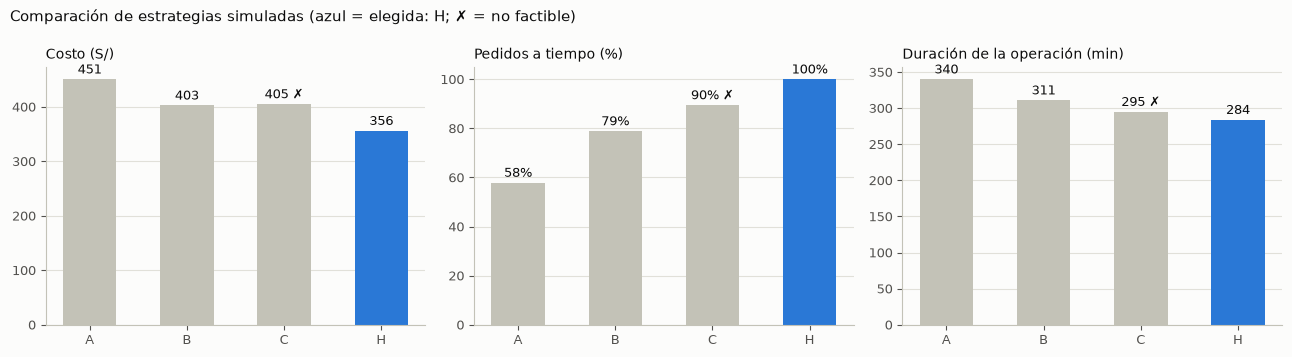

In [21]:
mostrar_agente(resultado, "evaluador")
display(Markdown("**KPIs simulados (tool `simular_estrategias`):**"))
display(tabla_kpis(resultado.estado))
if resultado.estado.estres:
    display(Markdown("**Pruebas de estrés (+30% tráfico, tool `prueba_estres`):**"))
    display(pd.DataFrame(resultado.estado.estres.values()))
if resultado.iteraciones > 1:
    display(Markdown(f"🔁 Hubo **{resultado.iteraciones - 1} replanificación(es)**: la primera propuesta no tenía ninguna estrategia factible."))
graficar_comparacion(resultado.estado, resultado.elegida, guardar_en=resultado.carpeta / "comparacion_kpis.png")

## 5.4 Resultado del Agente 4: Decisor

Salida cruda del Decisor (JSON con esquema estricto). En la sección 6 se presenta en formato legible.

In [22]:
mostrar_agente(resultado, "decisor")

**Agente 4 · Decisor / Coordinador logístico** · modelo `openai/gpt-oss-120b` · 1 llamada(s) a la API · 2,859 tokens · 2.1 s · 0 tool call(s)

```json
{
  "estrategia_elegida": "H",
  "resumen": "Se selecciona la estrategia H (línea base voraz) porque es la única factible con puntaje máximo (100) y mantiene puntualidad y entregas urgentes al 100% incluso bajo estrés (+30% tráfico). No se requiere escalado y los riesgos son manejables.",
  "por_que": [
    "Puntaje máximo (100) frente a B (73.2), A (54.7) y C (no factible).",
    "Mantiene 19/19 entregas a tiempo y 6/6 urgentes sin tardanza.",
    "Bajo prueba de estrés la puntualidad y urgentes permanecen al 100%, sin caída de puntaje.",
    "Cumple con los pesos del objetivo: puntualidad 30% y urgentes 30% se satisfacen plenamente."
  ],
  "criterios_que_pesaron": [
    {
      "criterio": "puntualidad",
      "importancia": "alta",
      "evidencia": "H: 19/19 a tiempo, puntualidad 100% (sin caída en estrés)."
    },
    {
      "criterio": "urgentes",
      "importancia": "alta",
      "evidencia": "H: 6/6 entregas urgentes a tiempo, 100% bajo estrés."
    },
    {
      "criterio": "costo",
      "importancia": "media",
      "evidencia": "H costo S/ 356.1, el más bajo entre las factibles."
    },
    {
      "criterio": "tiempo turno",
      "importancia": "media",
      "evidencia": "H finaliza a las 12:14, dentro del turno (07:30‑13:30)."
    }
  ],
  "desviacion_del_ranking": "ninguna",
  "trade_offs": [
    "Mayor uso de vehículos (se emplean los 5 disponibles) frente a la estrategia C que usaría menos, pero C no es factible.",
    "Costo ligeramente superior al mínimo posible, pero se prioriza puntualidad y urgentes."
  ],
  "riesgos": [
    {
      "riesgo": "Posible saturación de la furgoneta F1 con 7 pedidos (P09, P07, P11, P03, P01, P04, P06).",
      "mitigacion": "Revisar capacidad de carga antes de salir; si supera el límite, reubicar P06 a F2 que tiene espacio disponible."
    },
    {
      "riesgo": "Dependencia de la van V1 para 5 pedidos secos en zonas dispersas.",
      "mitigacion": "Verificar rutas en la app de tráfico; ajustar orden de visita si hay congestión inesperada."
    }
  ],
  "revisar_antes_de_aplicar": [
    "Confirmar capacidad de carga de cada furgoneta y van (peso y volumen).",
    "Validar disponibilidad de conductores y estado de los vehículos.",
    "Chequear que los pedidos urgentes (P09, P19) estén listos para cargar.",
    "Revisar la ventana horaria de cada pedido en el sistema TMS."
  ],
  "confianza": "alta",
  "escalar_a_humano": false
}
```

---
# 6. Decisión final (6.7)

La justificación es la que escribió el Decisor. Los **KPIs y la hoja de ruta no los escribe el LLM**: salen de la simulación de la estrategia elegida.

In [23]:
mostrar_decision(resultado)

### ✅ Alternativa seleccionada: **H · Línea base: heurística voraz sin LLM**
> Se selecciona la estrategia H (línea base voraz) porque es la única factible con puntaje máximo (100) y mantiene puntualidad y entregas urgentes al 100% incluso bajo estrés (+30% tráfico). No se requiere escalado y los riesgos son manejables.

**KPIs simulados:** costo **S/ 356.1** · 158.5 km · último regreso **12:14** · **19/19** pedidos a tiempo · urgentes **6/6** · 0 min de tardanza total · puntaje 100.0

**¿Por qué fue seleccionada?**
- Puntaje máximo (100) frente a B (73.2), A (54.7) y C (no factible).
- Mantiene 19/19 entregas a tiempo y 6/6 urgentes sin tardanza.
- Bajo prueba de estrés la puntualidad y urgentes permanecen al 100%, sin caída de puntaje.
- Cumple con los pesos del objetivo: puntualidad 30% y urgentes 30% se satisfacen plenamente.

**¿Qué criterios pesaron más?**
| criterio | importancia | evidencia |
|---|---|---|
| puntualidad | alta | H: 19/19 a tiempo, puntualidad 100% (sin caída en estrés). |
| urgentes | alta | H: 6/6 entregas urgentes a tiempo, 100% bajo estrés. |
| costo | media | H costo S/ 356.1, el más bajo entre las factibles. |
| tiempo turno | media | H finaliza a las 12:14, dentro del turno (07:30‑13:30). |

**Desviación respecto del ranking numérico:** ninguna

**Trade-offs aceptados:**
- Mayor uso de vehículos (se emplean los 5 disponibles) frente a la estrategia C que usaría menos, pero C no es factible.
- Costo ligeramente superior al mínimo posible, pero se prioriza puntualidad y urgentes.

**¿Qué riesgos permanecen?**
| riesgo | mitigación |
|---|---|
| Posible saturación de la furgoneta F1 con 7 pedidos (P09, P07, P11, P03, P01, P04, P06). | Revisar capacidad de carga antes de salir; si supera el límite, reubicar P06 a F2 que tiene espacio disponible. |
| Dependencia de la van V1 para 5 pedidos secos en zonas dispersas. | Verificar rutas en la app de tráfico; ajustar orden de visita si hay congestión inesperada. |

**¿Qué debe revisar un humano antes de aplicar la decisión?**
- [ ] Confirmar capacidad de carga de cada furgoneta y van (peso y volumen).
- [ ] Validar disponibilidad de conductores y estado de los vehículos.
- [ ] Chequear que los pedidos urgentes (P09, P19) estén listos para cargar.
- [ ] Revisar la ventana horaria de cada pedido en el sistema TMS.

**Confianza declarada por el Decisor:** alta · **Escalar a humano:** no

### 6.1 Hojas de ruta para los choferes y mapa

**F1**

,vuelta,orden,pedido,cliente,distrito,kg,tipo,prioridad,ventana,llegada,inicio_descarga,espera_min,estado
0,1,1,P09,Brasas del Parque,Lince,20.0,seco,urgente,08:00-09:30,08:00,08:00,0,a tiempo
1,1,2,P07,Pollería Sabor Norteño,Jesús María,85.0,refrigerado,urgente,08:00-10:00,08:16,08:16,0,a tiempo
2,1,3,P11,Pollería La Esquina,Magdalena del Mar,15.0,refrigerado,urgente,08:30-10:00,08:41,08:41,0,a tiempo
3,1,4,P03,Parrilla El Gaucho Limeño,San Isidro,140.0,refrigerado,urgente,09:00-10:30,09:04,09:04,0,a tiempo
4,1,5,P01,Pollería Brasa Real,Miraflores,110.0,refrigerado,normal,08:00-10:30,09:28,09:28,0,a tiempo
5,1,6,P04,Pollos Hermanos Quispe,Santiago de Surco,95.0,refrigerado,normal,09:00-11:30,10:04,10:04,0,a tiempo
6,1,7,P06,La Leña de Chorrillos,Chorrillos,130.0,refrigerado,normal,09:30-11:30,10:32,10:32,0,a tiempo


**F2**

,vuelta,orden,pedido,cliente,distrito,kg,tipo,prioridad,ventana,llegada,inicio_descarga,espera_min,estado
0,1,1,P19,Pollería Don Beto,San Borja,25.0,refrigerado,urgente,08:30-09:45,08:30,08:30,0,a tiempo
1,1,2,P15,Pollería Mi Causa,La Victoria,90.0,refrigerado,normal,08:30-10:30,08:53,08:53,0,a tiempo
2,1,3,P08,Parrillas Los Andes,La Molina,150.0,refrigerado,normal,09:00-11:00,09:41,09:41,0,a tiempo
3,1,4,P12,El Rincón Parrillero,San Miguel,120.0,refrigerado,normal,10:00-12:00,11:13,11:13,0,a tiempo
4,1,5,P10,Carbón y Sazón,Pueblo Libre,70.0,seco,normal,09:00-12:30,11:40,11:40,0,a tiempo


**V1**

,vuelta,orden,pedido,cliente,distrito,kg,tipo,prioridad,ventana,llegada,inicio_descarga,espera_min,estado
0,1,1,P13,Pollos a la Leña Rosita,Surquillo,30.0,seco,normal,08:00-11:00,08:00,08:00,0,a tiempo
1,1,2,P18,Brasería San Isidro,San Isidro,55.0,seco,normal,09:00-11:30,08:25,09:00,35,a tiempo
2,1,3,P05,Chifa Pollería Kam Lung,San Borja,60.0,seco,normal,08:00-12:00,09:31,09:31,0,a tiempo
3,1,4,P17,Pollería El Molinero,La Molina,40.0,seco,normal,10:00-12:00,10:12,10:12,0,a tiempo
4,1,5,P14,Asados Don Lucho,Santiago de Surco,45.0,seco,normal,10:00-12:30,10:51,10:51,0,a tiempo


**M1**

,vuelta,orden,pedido,cliente,distrito,kg,tipo,prioridad,ventana,llegada,inicio_descarga,espera_min,estado
0,1,1,P16,Parrilla Bar Miramar,Barranco,12.0,refrigerado,urgente,09:00-10:00,09:00,09:00,0,a tiempo


**M2**

,vuelta,orden,pedido,cliente,distrito,kg,tipo,prioridad,ventana,llegada,inicio_descarga,espera_min,estado
0,1,1,P02,Anticuchería Doña Pochita,Barranco,25.0,seco,normal,09:00-12:00,09:00,09:00,0,a tiempo


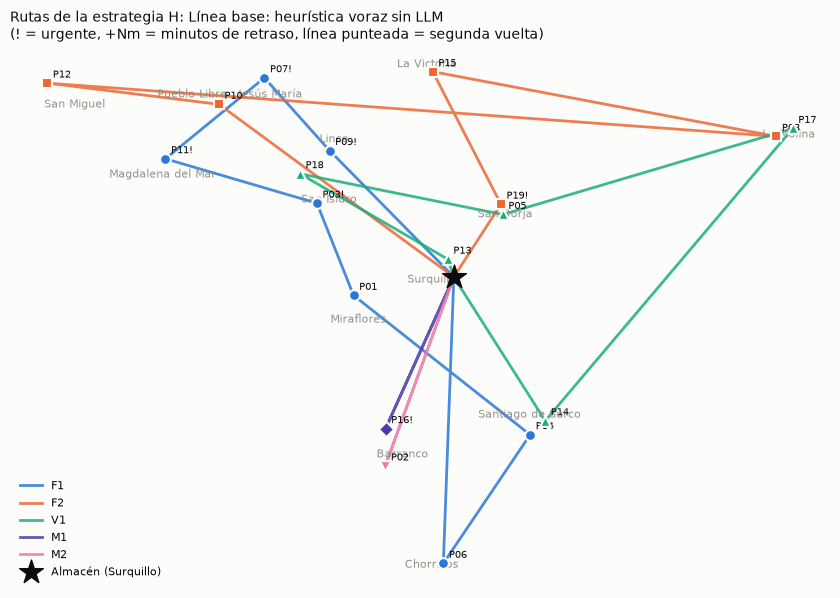

In [24]:
hoja = hoja_de_ruta(resultado.estado, resultado.elegida)
for vid, tramo in hoja.groupby("vehiculo", sort=False):
    display(Markdown(f"**{vid}**"))
    display(tramo.drop(columns=["vehiculo"]).reset_index(drop=True))
graficar_rutas(resultado.estado, resultado.elegida, guardar_en=resultado.carpeta / "mapa_rutas.png")

### 6.2 Aprobación humana (*human in the loop*)

El sistema **no despacha solo**. Con `APROBACION_INTERACTIVA = True` (como en la demo), el coordinador confirma o rechaza el plan. En una ejecución automática, el plan queda *pendiente de aprobación* junto con su checklist.

In [25]:
def aprobar(res):
    if res.escalar:
        print("⚠️ La auditoría o el Decisor marcaron este plan para REVISIÓN HUMANA obligatoria.")
    print(f"Plan propuesto: estrategia {res.elegida}. Checklist antes de despachar:")
    for x in res.decision.get("revisar_antes_de_aplicar", []):
        print("  ☐", x)
    if APROBACION_INTERACTIVA:
        r = input("¿Aprobar el despacho? (s/n o escribe un comentario): ").strip()
        estado_final = "APROBADO" if _norm(r) in ("s", "si") else "RECHAZADO" if _norm(r) == "n" else f"OBSERVADO: {r}"
    else:
        estado_final = "PENDIENTE DE APROBACIÓN DEL COORDINADOR"
    print(f"\nEstado del plan: {estado_final}")
    return estado_final

estado_aprobacion = aprobar(resultado)

Plan propuesto: estrategia H. Checklist antes de despachar:
  ☐ Confirmar capacidad de carga de cada furgoneta y van (peso y volumen).
  ☐ Validar disponibilidad de conductores y estado de los vehículos.
  ☐ Chequear que los pedidos urgentes (P09, P19) estén listos para cargar.
  ☐ Revisar la ventana horaria de cada pedido en el sistema TMS.

Estado del plan: PENDIENTE DE APROBACIÓN DEL COORDINADOR


---
# 7. Evaluación crítica (6.8)

No nos quedamos con "el sistema dio una respuesta". Medimos su calidad de cuatro maneras: (7.1) una **auditoría automática** de la decisión, (7.2) una comparación con una **regla simple sin LLM**, (7.3) qué pasa con **datos incorrectos** y (7.4) una corrida completa con **datos incompletos y una flota insuficiente**. Con eso respondemos las preguntas de la consigna en 7.5.

## 7.1 Auditoría automática de la decisión

In [26]:
display(resultado.auditoria)
print("Escalar a humano:", "SÍ" if resultado.escalar else "no")

,verificación,resultado,detalle
0,La estrategia elegida existe,✅,el Decisor eligió 'H'
1,El Analista aplicó todas las instrucciones (sin tool calls fallidas pendientes),✅,sí
2,"Sin violaciones duras (capacidad, frío, prohibiciones)",✅,ninguna
3,Todos los pedidos asignados,✅,19/19 a tiempo
4,Urgentes dentro de su ventana,✅,6/6
5,Puntualidad mínima aceptable (≥ 70% a tiempo),✅,100.0% a tiempo
6,Regreso dentro del turno,✅,"último regreso 12:14, 0 min fuera de turno"
7,Coincide con el #1 numérico o justifica la desviación,✅,#1 numérico: H (100.0); elegida: H (100.0)
8,Robustez evaluada con prueba de estrés,✅,caída 0.0 pts
9,El Evaluador usó el simulador (tool),✅,sí


Escalar a humano: no


## 7.2 ¿Los agentes le ganan a una regla simple?

Si un sistema multi-agente no supera a una heurística de diez líneas, no se justifican su costo ni su complejidad. Por eso el orquestador agrega a las propuestas del Planificador una **línea base H**: una regla voraz sin LLM (urgentes primero, luego por hora de cierre, cada pedido al vehículo compatible más cercano con capacidad). H cumple dos funciones:

1. **Red de seguridad:** si las tres propuestas del LLM son malas, el Decisor todavía tiene una alternativa razonable, y el sistema nunca recomienda algo peor que la regla simple.
2. **Vara de medida:** comparamos la mejor estrategia de los agentes contra H, con el mismo simulador y el mismo objetivo del día.

H se calcula sobre la operación que configuró el Analista a partir del texto libre. Es decir, aun cuando gana H, el trabajo de interpretación de los agentes sigue siendo necesario.

In [27]:
def comparar_con_heuristica(res):
    sims = res.estado.simulaciones
    agentes = [r for k, r in sims.items() if k != "H"]
    mejor = max(agentes, key=lambda r: r["puntaje"])
    filas = []
    for etiqueta, r in [("Elegida por el Decisor", sims[res.elegida]), ("Mejor propuesta de los agentes (A/B/C)", mejor),
                        ("Línea base H (sin LLM)", sims["H"])]:
        filas.append({"": etiqueta, "estrategia": r["id"], "factible": "sí" if r["factible"] else "NO", "costo S/": r["costo_soles"],
                      "hora fin": r["hora_fin"], "a tiempo": r["a_tiempo"], "urgentes a tiempo": r["urgentes_a_tiempo"],
                      "min tarde": r["min_tarde_total"], f"puntaje ({res.estado.objetivo})": r["puntaje"]})
    display(pd.DataFrame(filas))
    gana = "los agentes" if mejor["puntaje"] > sims["H"]["puntaje"] else "la línea base H"
    print(f"Mejor propuesta de los agentes vs línea base: {mejor['puntaje']} vs {sims['H']['puntaje']} puntos → gana {gana}.")
    if res.elegida == "H":
        print("El Decisor eligió la línea base: la red de seguridad funcionó y las propuestas del LLM no la superaron.")
    comp = {"objetivo": res.estado.objetivo, "elegida": sims[res.elegida], "mejor_agentes": mejor, "heuristica": sims["H"]}
    if res.carpeta:
        (res.carpeta / "comparacion_heuristica.json").write_text(json.dumps(comp, ensure_ascii=False, indent=2, default=str),
                                                                 encoding="utf-8")
    return comp

comparacion = comparar_con_heuristica(resultado)

,,estrategia,factible,costo S/,hora fin,a tiempo,urgentes a tiempo,min tarde,puntaje (puntualidad)
0,Elegida por el Decisor,H,sí,356.1,12:14,19/19,6/6,0,100.0
1,Mejor propuesta de los agentes (A/B/C),B,sí,402.7,12:41,15/19,5/6,184,73.2
2,Línea base H (sin LLM),H,sí,356.1,12:14,19/19,6/6,0,100.0


Mejor propuesta de los agentes vs línea base: 73.2 vs 100.0 puntos → gana la línea base H.
El Decisor eligió la línea base: la red de seguridad funcionó y las propuestas del LLM no la superaron.


## 7.3 ¿Qué pasa con datos incorrectos?

Llamamos directamente a las tools con errores típicos de un input escrito a la carrera (sin LLM, no gasta cuota). La idea es que **ningún dato inválido entre al estado en silencio**: o se corrige con un aviso o se rechaza con un error que el agente puede leer y corregir.

In [28]:
_e = EstadoOperacion()
pruebas = [
    ("Distrito con error de tipeo", "agregar_pedido", dict(distrito="Miraflorez", kg=40, tipo="seco", ventana_inicio="9:00", ventana_fin="10:00")),
    ("Distrito inexistente", "agregar_pedido", dict(distrito="Callao Norte", kg=40, tipo="seco", ventana_inicio="9:00", ventana_fin="10:00")),
    ("Peso negativo", "agregar_pedido", dict(distrito="Lince", kg=-5, tipo="seco", ventana_inicio="9:00", ventana_fin="10:00")),
    ("Ventana invertida", "agregar_pedido", dict(distrito="Lince", kg=20, tipo="seco", ventana_inicio="11:00", ventana_fin="9:00")),
    ("Pedido más grande que cualquier vehículo", "agregar_pedido", dict(distrito="La Molina", kg=900, tipo="refrigerado", ventana_inicio="8:00", ventana_fin="9:00")),
    ("Flota vacía", "configurar_operacion", dict(furgonetas_refrigeradas=0, vans=0, motos=0)),
    ("Factor escrito como porcentaje", "registrar_restriccion", dict(tipo="congestion", distritos=["Barranco"], factor=40)),
    ("Pedido inexistente", "modificar_pedido", dict(pedido_id="P99", ventana_fin="10:00")),
    ("Error PLAUSIBLE (15 kg → 150 kg)", "modificar_pedido", dict(pedido_id="P11", kg=150)),
]
display(pd.DataFrame([{"caso": caso, "tool": tool, "resultado": _resumen_resultado(ejecutar_tool(_e, tool, json.dumps(args)), 140)}
                      for caso, tool, args in pruebas]))

,caso,tool,resultado
0,Distrito con error de tipeo,agregar_pedido,"✅ id=P19, nota='Miraflorez' se interpretó como 'Miraflores'"
1,Distrito inexistente,agregar_pedido,"❌ distrito no reconocido 'Callao Norte'. Válidos: Ate, Barranco, Breña, Callao, Chorrillos, Comas, Independencia, Jesús María, La Molina..."
2,Peso negativo,agregar_pedido,"❌ kg fuera de rango (0, 600]: -5.0"
3,Ventana invertida,agregar_pedido,❌ ventana 11:00-09:00 inválida: el fin debe ser al menos 15 min después del inicio
4,Pedido más grande que cualquier vehículo,agregar_pedido,"❌ kg fuera de rango (0, 600]: 900.0"
5,Flota vacía,configurar_operacion,❌ la flota no puede quedar vacía
6,Factor escrito como porcentaje,registrar_restriccion,✅ registrada=congestión ×1.4 en Barranco
7,Pedido inexistente,modificar_pedido,"❌ pedido 'P99' no existe. Vigentes: P01, P02, P03, P04, P05, P06, P07, P08, P09, P10, P11, P12, P13, P14, P15, P16, P17, P18, P19"
8,Error PLAUSIBLE (15 kg → 150 kg),modificar_pedido,✅ id=P11


**Lectura.** Los errores de **formato** (distrito inexistente, peso negativo, ventana invertida, flota vacía) se rechazan, y los errores **leves** (tipeo, "40" en vez de 1.4) se corrigen dejando constancia. Pero el último caso muestra el límite real: **un error plausible pasa la validación**. Si alguien escribe 150 kg en vez de 15, el sistema lo acepta y planifica con un dato falso. Eso no se resuelve con más reglas; hace falta contrastar con el histórico del cliente y que una persona lo revise (ver 7.5).

## 7.4 Datos incompletos y flota insuficiente: corrida completa con solo 2 inputs

Usamos el **mínimo de inputs** (pedidos y flota), con un distrito mal escrito, un día con dos vehículos en el taller y tres pedidos urgentes grandes. Lo que esperamos de un sistema responsable es que detecte que no alcanza la capacidad, que intente replanificar y que **escale la decisión a una persona** en vez de fingir que todo está bien.

In [29]:
SOLICITUD_DEGRADADA = {
    "pedidos": "Los pedidos base y además 3 urgentes: 180 kg de pollo para La Molina entre 8:00 y 9:30, 90 kg de carne para el Callao "
               "entre 8:00 y 9:00, y 40 kg de carbón en Miraflorez entre 9 y 10. Cancelar el pedido de Pollería Mi Causa.",
    "flota": "Solo 1 furgoneta refrigerada y 1 moto; la van y la otra furgoneta están en el taller.",
}
EJECUTAR_ESCENARIO_DEGRADADO = True     # cuesta ~1 corrida extra de cuota; poner False si la cuota está justa
if EJECUTAR_ESCENARIO_DEGRADADO:
    degradado = ejecutar_sistema(SOLICITUD_DEGRADADA, etiqueta="escenario_degradado")
    alertas = alertas_del_dia(degradado.estado)
    display(Markdown("**Alertas calculadas por `resumen_operacion`:**\n\n" + ("\n".join(f"- {a}" for a in alertas) or "- ninguna")))
    display(tabla_kpis(degradado.estado))
    display(degradado.auditoria)
    print(f"Iteraciones Planificador⇄Evaluador: {degradado.iteraciones} · elegida: {degradado.elegida} · "
          f"escalar a humano: {'SÍ' if degradado.escalar else 'no'}")
    print("Qué debe autorizar una persona:", *[f"\n  • {x}" for x in degradado.decision.get("revisar_antes_de_aplicar", [])])


════════════════════════════════════════════════════════════════════════════════════════════════════
 PROMPT INICIAL · 2 inputs: pedidos, flota
════════════════════════════════════════════════════════════════════════════════════════════════════
   • pedidos: Los pedidos base y además 3 urgentes: 180 kg de pollo para La Molina entre 8:00 y 9:30, 90 kg de carne para el Callao entre 8:00 y 9:00, y 40 kg de carbón en Miraflorez entre 9 y 10. Cancelar el pedido de Pollería Mi Causa.
   • flota: Solo 1 furgoneta refrigerada y 1 moto; la van y la otra furgoneta están en el taller.

════════════════════════════════════════════════════════════════════════════════════════════════════
 1/4 · ANALISTA DE OPERACIONES (tools de datos)
════════════════════════════════════════════════════════════════════════════════════════════════════


   🔧 configurar_operacion(furgonetas_refrigeradas=1, motos=1, vans=0)
      → ✅ turno=07:30-13:30, objetivo=balanceado
   🔧 agregar_pedido(distrito='La Molina', kg=180, prioridad='urgente', tipo='refrigerado', ventana_fin='09:30', ve…)
      → ✅ id=P19
   🔧 agregar_pedido(distrito='Callao', kg=90, prioridad='urgente', tipo='refrigerado', ventana_fin='09:00', ventan…)
      → ✅ id=P20
   🔧 agregar_pedido(distrito='Miraflores', kg=40, prioridad='urgente', tipo='seco', ventana_fin='10:00', ventana_i…)
      → ✅ id=P21
   🔧 cancelar_pedido(motivo='Cancelado por coordinador de despacho', pedido_id='P15')
      → ✅ cancelado=P15
   ⏳ qwen/qwen3.8-27b: cuota por minuto agotada en todas las keys; espero 25s…


   🔧 resumen_operacion()
      → ✅ turno=07:30-13:30, objetivo=balanceado, pedidos=20, kg_total=1512, alertas=3
   ⏳ qwen/qwen3.8-27b: cuota por minuto agotada en todas las keys; espero 9s…


   ⚠️ 429 en key2…FhHH / qwen/qwen3.8-27b → bloqueo 1s y roto de key
   ⏳ qwen/qwen3.8-27b: cuota por minuto agotada en todas las keys; espero 1s…


   ✔ Agente 1 · Analista de operaciones: modelo qwen/qwen3.8-27b · 3 llamada(s) · 12,457 tokens · 40.5s · 6 tool call(s)

════════════════════════════════════════════════════════════════════════════════════════════════════
 2/4 · PLANIFICADOR DE RUTAS (iteración 1)
════════════════════════════════════════════════════════════════════════════════════════════════════


...

   ✔ Agente 4 · Decisor / Coordinador logístico: modelo openai/gpt-oss-120b · 1 llamada(s) · 4,203 tokens · 2.7s · 0 tool call(s)

════════════════════════════════════════════════════════════════════════════════════════════════════
 RESULTADO: estrategia A · ⚠️ REQUIERE REVISIÓN HUMANA · 96.0s · 39,396 tokens
════════════════════════════════════════════════════════════════════════════════════════════════════
📁 Evidencias guardadas en evidencias/20261011_163508_escenario_degradado/ (traza.json, resumen.md)


**Alertas calculadas por `resumen_operacion`:**

- CAPACIDAD: demanda 1512 kg > 630 kg por vuelta → hacen falta segundas vueltas o más vehículos
- FRÍO: 1127 kg refrigerados > 630 kg de capacidad con frío por vuelta
- AJUSTADO: P20 urgente en Callao: margen de 28 min aun saliendo directo

,estrategia,factible,costo S/,km,hora fin,min fuera turno,a tiempo,urgentes a tiempo,min tarde,puntaje,violaciones
0,H · Línea base: heurística voraz sin LLM,NO,217.7,96.8,13:14,0,2/20,2/8,772,24.0,"pedidos sin asignar: P01, P02, P04, P05, P06, P08, P10, P12, P14, P17, P18"
1,A · Agrupación geográfica,NO,474.9,172.5,19:57,387,6/20,5/8,3459,11.8,pedidos sin asignar: P17; F1 vuelta 2: 655 kg > capacidad 600 kg
2,C · Consolidación mínima de vehículos,NO,519.3,199.6,19:29,359,6/20,5/8,2723,11.6,pedidos sin asignar: P17; F1 vuelta 1: 1440 kg > capacidad 600 kg
3,B · Protección de ventanas críticas,NO,436.2,147.3,19:07,337,4/20,3/8,3191,8.7,P09 asignado en dos rutas; P16 asignado en dos rutas


,verificación,resultado,detalle
0,La estrategia elegida existe,✅,el Decisor eligió 'A'
1,El Analista aplicó todas las instrucciones (sin tool calls fallidas pendientes),✅,sí
2,"Sin violaciones duras (capacidad, frío, prohibiciones)",❌,pedidos sin asignar: P17; F1 vuelta 2: 655 kg > capacidad 600 kg
3,Todos los pedidos asignados,❌,6/20 a tiempo
4,Urgentes dentro de su ventana,⚠️,5/8
5,Puntualidad mínima aceptable (≥ 70% a tiempo),❌,30.0% a tiempo → bajo el umbral: el plan no sale sin revisión humana
6,Regreso dentro del turno,⚠️,"último regreso 19:57, 387 min fuera de turno"
7,Coincide con el #1 numérico o justifica la desviación,⚠️,#1 numérico: H (24.0); elegida: A (11.8)
8,Robustez evaluada con prueba de estrés,✅,caída 5.0 pts
9,El Evaluador usó el simulador (tool),✅,sí


Iteraciones Planificador⇄Evaluador: 2 · elegida: A · escalar a humano: SÍ
Qué debe autorizar una persona: 
  • Confirmar pesos exactos de los pedidos que se moverán para no superar 600 kg por vuelta. 
  • Verificar que P17 cumpla con requisitos de frío y peso antes de asignarlo. 
  • Chequear disponibilidad de un vehículo extra o moto para cubrir el sobrepeso. 
  • Recalcular la hora estimada de llegada del último pedido tras los ajustes.


## 7.5 Respuestas a las preguntas de la evaluación crítica

La celda siguiente arma un veredicto con la evidencia de esta corrida (auditoría + comparación con la heurística). Debajo están nuestras respuestas.

In [30]:
def veredicto(res, comp):
    a = res.auditoria.set_index("verificación")["resultado"]
    s = res.estado.simulaciones[res.elegida]
    puntos = [
        f"Factible según el simulador: {'sí' if s['factible'] else 'NO'}",
        f"Urgentes a tiempo: {s['urgentes_a_tiempo']} · pedidos a tiempo: {s['a_tiempo']}",
        f"Mejor propuesta de los agentes vs línea base H: {comp['mejor_agentes']['puntaje']} vs {comp['heuristica']['puntaje']} puntos"
        + (" (se eligió H: la red de seguridad funcionó)" if res.elegida == "H" else ""),
        f"Verificaciones críticas fallidas: {sum(a == '❌')} · advertencias: {sum(a == '⚠️')}",
    ]
    razonable = s["factible"] and sum(a == "❌") == 0
    display(Markdown(f"**¿La decisión fue razonable?** {'Sí, con las salvedades de abajo.' if razonable else 'No del todo: requiere revisión humana.'}\n\n"
                     + "\n".join(f"- {p}" for p in puntos)))

veredicto(resultado, comparacion)

**¿La decisión fue razonable?** Sí, con las salvedades de abajo.

- Factible según el simulador: sí
- Urgentes a tiempo: 6/6 · pedidos a tiempo: 19/19
- Mejor propuesta de los agentes vs línea base H: 73.2 vs 100.0 puntos (se eligió H: la red de seguridad funcionó)
- Verificaciones críticas fallidas: 0 · advertencias: 0

**¿La decisión fue razonable?**
Se juzga con evidencia, no por cómo suena la justificación: la estrategia elegida tiene que ser factible en el simulador, pasar la auditoría, cumplir el criterio que el objetivo del día pone primero y no quedar por debajo de la heurística sin LLM. La celda anterior resume esos cuatro puntos para esta corrida. Un matiz importante: "razonable" no significa "óptima". El sistema elige entre 3 propuestas, y si las 3 son mediocres elige la menos mala; por eso la comparación con la heurística es necesaria. Con flota insuficiente (7.4) no existe una solución buena, y lo correcto es replanificar y escalar a una persona en vez de presentar un plan como si fuera viable. La salida de 7.4 muestra si el sistema efectivamente lo hizo.

**¿Qué errores podría cometer el sistema?**
1. **Interpretación** (Analista): entender mal una frase ambigua, por ejemplo aplicar "después de las 10" al pedido equivocado, o no registrar una restricción mencionada de pasada. *Mitigación:* la tabla de *tool calls* y la bitácora de cambios muestran exactamente qué se interpretó.
2. **Propuestas pobres** (Planificador): estrategias que dejan pedidos sin asignar, exceden la capacidad o repiten la misma lógica. En pruebas con un modelo local de 7B, el Planificador dejó 13 de 19 pedidos sin asignar. *Mitigación:* el simulador lo detecta, se replanifica una vez y la línea base H evita que el sistema recomiende algo peor que la regla simple.
3. **Cifras inventadas** (Evaluador/Decisor): citar números que no salen del simulador. *Mitigación:* la auditoría revisa los montos y porcentajes citados contra los KPIs.
4. **Errores del modelo de mundo** (simulador): el tráfico real no sigue nuestro perfil por hora, las distancias son en línea recta × 1.4 y los clientes están en coordenadas aproximadas. Una estrategia "a tiempo" en simulación puede llegar tarde en la calle. *Mitigación parcial:* la prueba de estrés al +30%.
5. **Variabilidad:** con temperatura > 0, dos corridas con el mismo input pueden elegir estrategias distintas. Por eso los KPIs son deterministas y el Decisor solo elige entre opciones medidas.

**¿Qué pasaría si los datos fueran incompletos o incorrectos?**
- *Incompletos:* los inputs no dados toman su valor por defecto y el Analista lo declara como supuesto. Si falta capacidad, `resumen_operacion` lo detecta antes de planificar, el sistema replanifica y la auditoría obliga a escalar si la puntualidad cae bajo el 70% (7.4).
- *Mal interpretados por el Analista:* si una tool call falla y el agente no la corrige, el plan se construye sobre una configuración incompleta. En nuestras pruebas con un modelo local de 7B pasó con la flota: el Analista nunca logró registrar "1 furgoneta y 1 moto" y el sistema planificó con la flota por defecto. Por eso el agente recibe una insistencia automática y la auditoría muestra las llamadas que quedaron fallidas.
- *Incorrectos en formato:* las tools los rechazan o los corrigen con un aviso (7.3).
- *Incorrectos pero plausibles* (150 kg en vez de 15, una ventana mal copiada): **pasan**. El plan se ve correcto pero se basa en un dato falso. Es el riesgo más serio, porque no se nota.

**¿Dónde debería intervenir una persona?**
1. **Antes de planificar:** confirmar los cambios que interpretó el Analista (la bitácora), sobre todo los pedidos nuevos y las cancelaciones.
2. **Antes de despachar:** el checklist de `revisar_antes_de_aplicar` (por ejemplo, llamar al cliente urgente con poco margen o confirmar que la moto tiene la caja térmica cargada).
3. **Siempre que haya escalamiento:** cuando no hay estrategia factible, decisiones como subcontratar un vehículo, renegociar ventanas o priorizar a unos clientes sobre otros son comerciales y le corresponden a una persona, no al sistema.
4. **Después del día:** comparar las ETA simuladas con las reales para recalibrar el perfil de tráfico.

**¿Qué mejoraríamos en una siguiente versión?**
1. Tiempos reales con una API de rutas y tráfico (Google Routes u OSRM) en lugar de haversine × factor.
2. Un optimizador clásico (OR-Tools VRPTW) como tool del Planificador: el LLM elegiría la lógica y el solver optimizaría la secuencia.
3. Validación de datos contra el histórico de cada cliente (pesos y ventanas habituales) para atrapar los errores plausibles.
4. Varias corridas y voto entre ellas (*self-consistency*) para medir la estabilidad de la decisión.
5. Retroalimentación diaria: guardar las ETA reales y ajustar automáticamente los factores de tráfico por zona y hora.

---
# 8. Demo en vivo (exposición del miércoles)

**Cómo la corremos:**
1. Antes de la exposición: `.env` con las keys de al menos 3 integrantes y la celda **4.3 (*preflight*)** en verde.
2. Se ejecutan las celdas de §4 (definiciones) **sin** volver a correr §5 y §7, para no gastar cuota.
3. Le pedimos al otro equipo que dicte **los 5 inputs** (o al menos pedidos y flota). Ideas para guiarlos:
   - *pedidos*: "agreguen un pedido urgente de X kg en <distrito> entre <hora> y <hora>" o "cancelen el de <cliente>"
   - *flota*: "hoy se malogró <vehículo>"
   - *horario*: "salimos a las <hora> y volvemos antes de las <hora>"
   - *restricciones*: "hay un paro / obra / marcha en <distritos>" o "las furgonetas no pueden entrar a <distrito>"
   - *objetivo*: costo, puntualidad, rapidez o balanceado
4. Se pegan en `SOLICITUD_DEMO`, se cambia `EJECUTAR_DEMO = True` y se ejecuta. Mientras corre, narramos las líneas 🔧, que son la evidencia de que los agentes usan las tools.

In [31]:
EJECUTAR_DEMO = False          # ← True durante la exposición
APROBACION_INTERACTIVA = EJECUTAR_DEMO

SOLICITUD_DEMO = {             # ← lo dicta el otro equipo (mínimo pedidos y flota)
    "pedidos": "",
    "flota": "",
    "horario": "",
    "restricciones": "",
    "objetivo": "",
}

if EJECUTAR_DEMO:
    demo = ejecutar_sistema(SOLICITUD_DEMO, etiqueta="demo_en_vivo")
    mostrar_evidencia_tools(demo)
    mostrar_decision(demo)
    display(demo.auditoria)
    graficar_rutas(demo.estado, demo.elegida, guardar_en=demo.carpeta / "mapa_rutas.png")
    aprobar(demo)
else:
    print("Demo desactivada (EJECUTAR_DEMO = False). En la exposición: completar SOLICITUD_DEMO y poner True.")

Demo desactivada (EJECUTAR_DEMO = False). En la exposición: completar SOLICITUD_DEMO y poner True.


---
# 9. Gestión del consumo de Groq

Registro de todas las llamadas a la API de esta sesión: qué agente, qué modelo y qué key se usó, cuántos tokens consumió y cuánta cuota por minuto quedaba según las cabeceras de Groq. Con esta tabla dimensionamos la demo: sabemos cuántos tokens cuesta una corrida y cuántas keys necesitamos.

llamadas  tokens  latencia_media_s
agente               modelo                                                 
preflight            qwen/qwen3.8-27b            1      19               0.3
                     openai/gpt-oss-120b         1     100               0.5
analista             qwen/qwen3.8-27b            6   25356               1.4
planificador         openai/gpt-oss-120b         3   15707               5.9
evaluador            qwen/qwen3.8-27b            7   22076               1.6
evaluador-reparacion qwen/qwen3.8-27b            1     284               0.8
decisor              openai/gpt-oss-120b         2    7062               2.4

,llamadas,tokens
key,,
key1…iFTc,8,32647
key2…FhHH,13,37957


Total de la sesión: 21 llamadas · 70,604 tokens · rotaciones/esperas visibles arriba con ⚠️/⏳ si las hubo


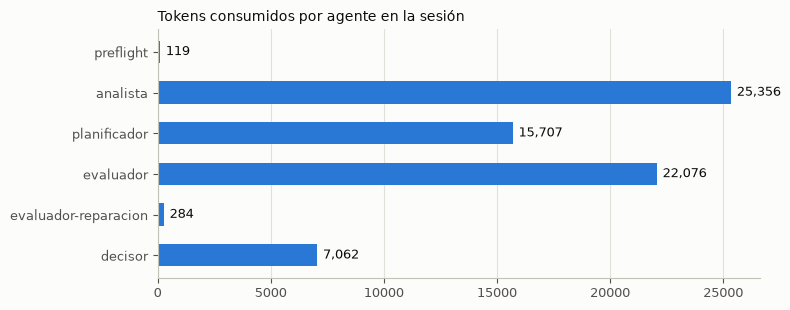

In [32]:
consumo = pd.DataFrame(gestor.registro)
display(consumo.groupby(["agente", "modelo"], sort=False)
        .agg(llamadas=("tokens_total", "size"), tokens=("tokens_total", "sum"), latencia_media_s=("latencia_s", "mean"))
        .round(1))
display(consumo.groupby("key").agg(llamadas=("tokens_total", "size"), tokens=("tokens_total", "sum")))
print(f"Total de la sesión: {len(consumo)} llamadas · {consumo.tokens_total.sum():,} tokens · "
      f"rotaciones/esperas visibles arriba con ⚠️/⏳ si las hubo")

por_agente = consumo.groupby("agente", sort=False)["tokens_total"].sum()
fig, ax = plt.subplots(figsize=(8, 0.5 + 0.45 * len(por_agente)))
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
ax.barh(por_agente.index[::-1], por_agente.values[::-1], color=COLORES[0], height=0.55)
for y, v in enumerate(por_agente.values[::-1]):
    ax.annotate(f"{v:,}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=TINTA)
ax.set_title("Tokens consumidos por agente en la sesión", fontsize=10, color=TINTA, loc="left")
_estilo_ejes(ax); ax.grid(axis="x", color=GRILLA); ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

---
# 10. Conclusiones

1. **Separar roles sirve si cada rol falla distinto.** Interpretar, proponer, medir y decidir tienen errores típicos diferentes. Separarlos permitió darle a cada uno su propia temperatura, modelo, salida estructurada y controles.
2. **El LLM interpreta y juzga; el código calcula.** Lo que más mejoró la calidad fue obligar al Evaluador a simular antes de opinar y dejar que los KPIs finales salgan del simulador, no del texto del modelo.
3. **Las tools son la frontera de confianza.** Todo dato que entra al estado pasa por una tool que valida, y todo número que sale lo produce una tool determinista.
4. **La decisión sigue siendo humana.** El sistema reduce la planificación a minutos y muestra los *trade-offs*, pero los errores plausibles en los datos y las decisiones comerciales (a qué cliente fallarle si no alcanza la flota) requieren al coordinador.
5. **Con la capa gratuita de Groq, la confiabilidad es parte del diseño.** La rotación de keys, el respaldo de modelos y la lectura de *rate limits* son lo que permite hacer la demo en vivo sin depender de la suerte.

**Entregables:** este notebook · `entregables/diagrama_flujo.png` · `evidencias/` (traza JSON, resumen y gráficos de cada corrida) · `entregables/Presentacion_LasGrills_Hackathon7.pptx`.